In [1]:
# ============================================================
# CELL 1: Install Required Libraries
# ============================================================
# Full stack for all 4 project parts.
# Installed once at the top for reproducibility.
# ============================================================

!pip install prophet xgboost statsmodels tensorflow streamlit -q

print("=" * 60)
print("✅  ALL DEPENDENCIES INSTALLED SUCCESSFULLY")
print("=" * 60)

✅  ALL DEPENDENCIES INSTALLED SUCCESSFULLY


In [1]:
# ============================================================
# CELL 2: Imports & Global Configuration
# ============================================================

# ── Core ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualization ────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

# ── Statistics ───────────────────────────────────────────────
import scipy
from scipy import stats
# ── Date Utilities ───────────────────────────────────────────
from datetime import datetime, timedelta

# ── Utilities ────────────────────────────────────────────────
import warnings
import sys
import os
import random
from collections import defaultdict

# ── Suppress Non-Critical Warnings ──────────────────────────
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════
# GLOBAL CONSTANTS — derived from actual data inspection
# Change ONLY here if column names differ
# ════════════════════════════════════════════════════════════

# Primary columns (verified against actual merged.csv)
ATM_COL    = 'ATM_CODE'           # ATM identifier  (e.g., 'CAEW001')
DATE_COL   = 'TRAN_DATE'          # Transaction date (format: dd-MMM-yy)
TARGET_COL = 'WITHDRAWAL_AMOUNT'  # Prediction target (EGP)
BANK_COL   = 'BANK_ID'            # Bank identifier  (numeric)
DATE_FMT   = '%d-%b-%y'           # strptime format  (e.g., '4-Dec-24')

# Egypt calendar constants
# Python's weekday(): Monday=0, Tuesday=1, ..., Friday=4, Saturday=5, Sunday=6
EGYPT_WEEKEND_DAYS  = [4, 5]      # Friday=4, Saturday=5

# Egyptian public holidays in data range (Sep–Dec 2024)
# ⚠️  Verify these dates with the bank's official HR calendar

EGYPT_HOLIDAYS = {
    # 2025
    pd.Timestamp('2025-01-07'):  'Coptic Christmas',
    pd.Timestamp('2025-04-25'):  'Sinai Liberation Day',
    pd.Timestamp('2025-05-01'):  'Labour Day',
    pd.Timestamp('2025-06-30'):  'June 30 Revolution',
    pd.Timestamp('2025-07-23'):  'Revolution Day',
    pd.Timestamp('2025-10-06'):  'Armed Forces Day',
    # 2026
    pd.Timestamp('2026-01-07'):  'Coptic Christmas',
    pd.Timestamp('2026-04-25'):  'Sinai Liberation Day',
    pd.Timestamp('2026-05-01'):  'Labour Day',
}

# Modeling thresholds
MIN_DAYS_SPARSE  = 30   # ATMs below this = insufficient for any model
MIN_DAYS_MODEL   = 60   # ATMs at/above this = ready for modeling

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ── Display Configuration ────────────────────────────────────
pd.set_option('display.max_columns',  60)
pd.set_option('display.width',       140)
pd.set_option('display.max_rows',    120)
pd.set_option('display.float_format', '{:,.2f}'.format)
np.set_printoptions(suppress=True, precision=2)

# ── Plot Style ───────────────────────────────────────────────
plt.rcParams.update({
    'figure.figsize'   : (14, 5),
    'font.size'        : 11,
    'axes.titlesize'   : 13,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 11,
    'axes.grid'        : True,
    'grid.alpha'       : 0.30,
    'lines.linewidth'  : 1.6,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
})
sns.set_style('whitegrid')
sns.set_palette('husl')

# ── Reusable Separator ───────────────────────────────────────
SEP  = '─' * 68
SEP2 = '═' * 68

# ── Confirmation ─────────────────────────────────────────────
# ── Confirmation ─────────────────────────────────────────────
print(SEP2)
print('✅  IMPORTS & CONFIGURATION COMPLETE')
print(SEP2)
print(f'  Python      : {sys.version.split()[0]}')
print(f'  Pandas      : {pd.__version__}')
print(f'  NumPy       : {np.__version__}')
print(f'  Matplotlib  : {plt.matplotlib.__version__}')
print(f'  Seaborn     : {sns.__version__}')
print(SEP)
print(f'  ATM Column  : {ATM_COL}')
print(f'  Date Column : {DATE_COL}  (format: {DATE_FMT})')
print(f'  Target      : {TARGET_COL}')
print(f'  Weekend     : Friday + Saturday (Egypt)')
print(f'  Holidays    : {len(EGYPT_HOLIDAYS)} defined')
print(SEP2)

════════════════════════════════════════════════════════════════════
✅  IMPORTS & CONFIGURATION COMPLETE
════════════════════════════════════════════════════════════════════
  Python      : 3.12.11
  Pandas      : 2.3.0
  NumPy       : 2.3.1
  Matplotlib  : 3.11.1
  Seaborn     : 0.13.2
────────────────────────────────────────────────────────────────────
  ATM Column  : ATM_CODE
  Date Column : TRAN_DATE  (format: %d-%b-%y)
  Target      : WITHDRAWAL_AMOUNT
  Weekend     : Friday + Saturday (Egypt)
  Holidays    : 9 defined
════════════════════════════════════════════════════════════════════


In [2]:
# ============================================================
# CELL 3: Load Raw Data & Structural Inspection
# ============================================================

print(SEP2)
print('📂  LOADING: merged.csv')
print(SEP2)

# ── Load ─────────────────────────────────────────────────────
try:
    df = pd.read_csv('merged.csv', low_memory=False)
    print(f'\n✅  Loaded successfully!\n')
except FileNotFoundError:
    print('\n❌  ERROR: merged.csv not found!')
    print('   → In Colab: Click the 📁 icon (left panel) → Upload File')
    print('   → Or run your amt.py merge script first')
    raise

# ── Immediate Cleaning: Strip Whitespace from String Columns ─
# Confirmed issue: DAY_OF_WEEK = "MONDAY   " in raw data
string_cols = df.select_dtypes(include='object').columns.tolist()
df[string_cols] = df[string_cols].apply(
    lambda col: col.str.strip() if col.dtype == 'object' else col
)
print(f'  ✂️  Stripped trailing/leading spaces from '
      f'{len(string_cols)} string columns')
print(f'  (Confirmed fix: DAY_OF_WEEK was "MONDAY   " → now "MONDAY")')

# ── Smart ATM Column Detection ───────────────────────────────
print(f'\n{SEP}')
print('🔍  ATM IDENTIFIER COLUMN DETECTION')
print(SEP)

if 'ATM_ID' in df.columns:
    ATM_COL = 'ATM_ID'
    print(f'  ✅  Found: ATM_ID (numeric)')
elif 'ATM_CODE' in df.columns:
    ATM_COL = 'ATM_CODE'
    print(f'  ✅  Found: ATM_CODE (alphanumeric, e.g., "CAEW001")')
    print(f'  ⚠️   NOTE: Project description says "ATM_ID = 6698" but')
    print(f'       actual column is ATM_CODE. Using ATM_CODE throughout.')
else:
    candidates = [c for c in df.columns if 'ATM' in c.upper()]
    print(f'  ❌  Neither ATM_ID nor ATM_CODE found!')
    print(f'  Columns containing "ATM": {candidates}')
    ATM_COL = candidates[0] if candidates else None
    print(f'  → Using: {ATM_COL}')

# Verify essential columns exist
essential = [ATM_COL, DATE_COL, TARGET_COL]
missing_essential = [c for c in essential if c not in df.columns]
if missing_essential:
    print(f'\n  ❌  CRITICAL: Missing essential columns: {missing_essential}')
    print(f'  Available columns: {df.columns.tolist()}')
    raise KeyError(f'Essential columns missing: {missing_essential}')
else:
    print(f'\n  ✅  All essential columns present:')
    for col in essential:
        print(f'     [{col}] dtype={df[col].dtype}, '
              f'sample="{df[col].dropna().iloc[0]}"')

# ── Shape ────────────────────────────────────────────────────
print(f'\n{SEP}')
print('📊  DATASET SHAPE')
print(SEP)
print(f'  Rows    : {df.shape[0]:>10,}')
print(f'  Columns : {df.shape[1]:>10,}')

# ── Full Column Catalog ──────────────────────────────────────
print(f'\n{SEP}')
print('📋  COMPLETE COLUMN CATALOG')
print(SEP)

catalog = pd.DataFrame({
    'Index'       : range(len(df.columns)),
    'Column'      : df.columns.tolist(),
    'Dtype'       : df.dtypes.values.astype(str),
    'Non-Null'    : df.notna().sum().values,
    'Null_Count'  : df.isna().sum().values,
    'Null_%'      : (df.isna().mean() * 100).round(1).values,
    'Sample'      : [
        str(df[c].dropna().iloc[0])[:28] if df[c].notna().any()
        else '⚠️  ALL NULL'
        for c in df.columns
    ]
})

print(catalog.to_string(index=False))

# ── First 3 Rows (Transposed) ────────────────────────────────
print(f'\n{SEP}')
print('🔍  FIRST 3 ROWS — Raw Values (Transposed for Readability)')
print(SEP)
# Transpose so columns are rows — more readable with 86 columns
print(df.head(3).T.to_string())

print(f'\n{SEP2}')
print('✅  DATA LOAD COMPLETE')
print(SEP2)

════════════════════════════════════════════════════════════════════
📂  LOADING: merged.csv
════════════════════════════════════════════════════════════════════

✅  Loaded successfully!

  ✂️  Stripped trailing/leading spaces from 28 string columns
  (Confirmed fix: DAY_OF_WEEK was "MONDAY   " → now "MONDAY")

────────────────────────────────────────────────────────────────────
🔍  ATM IDENTIFIER COLUMN DETECTION
────────────────────────────────────────────────────────────────────
  ✅  Found: ATM_ID (numeric)

  ✅  All essential columns present:
     [ATM_ID] dtype=int64, sample="6698"
     [TRAN_DATE] dtype=object, sample="06-JAN-25"
     [WITHDRAWAL_AMOUNT] dtype=int64, sample="141900"

────────────────────────────────────────────────────────────────────
📊  DATASET SHAPE
────────────────────────────────────────────────────────────────────
  Rows    :  1,160,424
  Columns :         93

────────────────────────────────────────────────────────────────────
📋  COMPLETE COLUMN CATALOG
─────

════════════════════════════════════════════════════════════════════
🔍  COMPREHENSIVE DATASET INSPECTION — 11 STEPS
════════════════════════════════════════════════════════════════════

▶ 4.1  PARSE TRAN_DATE──────────────────────────────────────────────
  Expected format : %d-%b-%y  (e.g., "4-Dec-24", "30-Nov-24")
  Raw sample      : ['06-JAN-25', '18-MAY-25', '18-FEB-25', '08-MAR-25', '22-FEB-25']

  ✅  Parsing complete:
     Successful :  1,160,424  (100.00%)
     Failed      : 0  ✅  Zero parsing errors!

  Parsed samples:
     2025-01-06 (Monday)
     2025-05-18 (Sunday)
     2025-02-18 (Tuesday)
     2025-03-08 (Saturday)
     2025-02-22 (Saturday)

▶ 4.2  WITHDRAWAL_AMOUNT CLEANING───────────────────────────────────
  Raw dtype       : int64
  Raw sample      : [141900, 114600, 176500, 26200, 72750]

  After conversion:
     Dtype         : int64
     Null values   : 0
     Numeric range : 0 → 2,921,250 EGP

  ⚠️   AMOUNT vs WITHDRAWAL_AMOUNT:
     AMOUNT == WITHDRAWAL_AMOUNT : 5

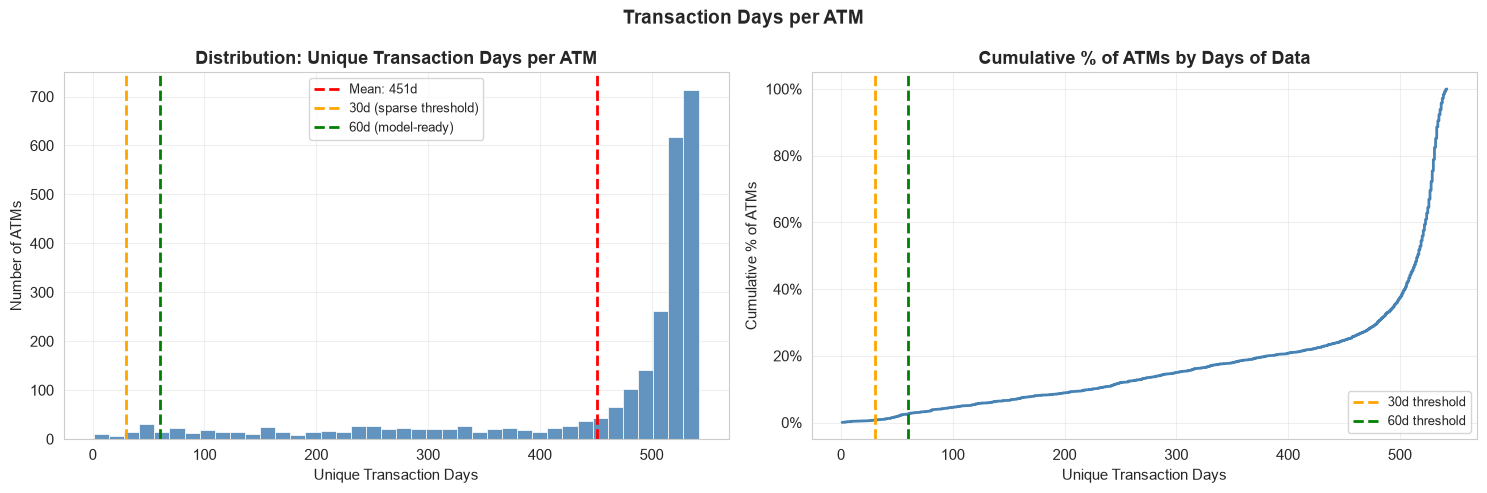

  📊  Saved: 04a_days_per_atm.png

▶ 4.6  ATMs WITH INSUFFICIENT DATA──────────────────────────────────

  ATMs with < 30 days (too sparse for any model)  :    16
  ATMs with 30–59 days (borderline)        :    49
  ATMs with ≥ 60 days (model-ready)         : 2,507
  Total ATMs                                   : 2,572

  ATMs with < 30 days of data:
 ATM_ID  Days
  19340     1
  19521     3
  19520     3
  19499     5
  19500     5
  19519     6
  19481     9
  19480     9
  19479     9
  19459    13
  19439    16
  19400    21
  19419    23
  19381    25
  19359    27
  19399    27

  Recommendation: Exclude these ATMs from Part 3 modeling.

▶ 4.7  RECORDS PER ATM PER DAY──────────────────────────────────────

  Total ATM-Day combinations :  1,160,424

  Records/Day  |  ATM-Day Pairs  |  % of Total  |  Bar Chart
  ───────────────────────────────────────────────────────────────
            1  |        1,160,424  |      100.00%  |  ███████████████████████████████████

  Always 1 record 

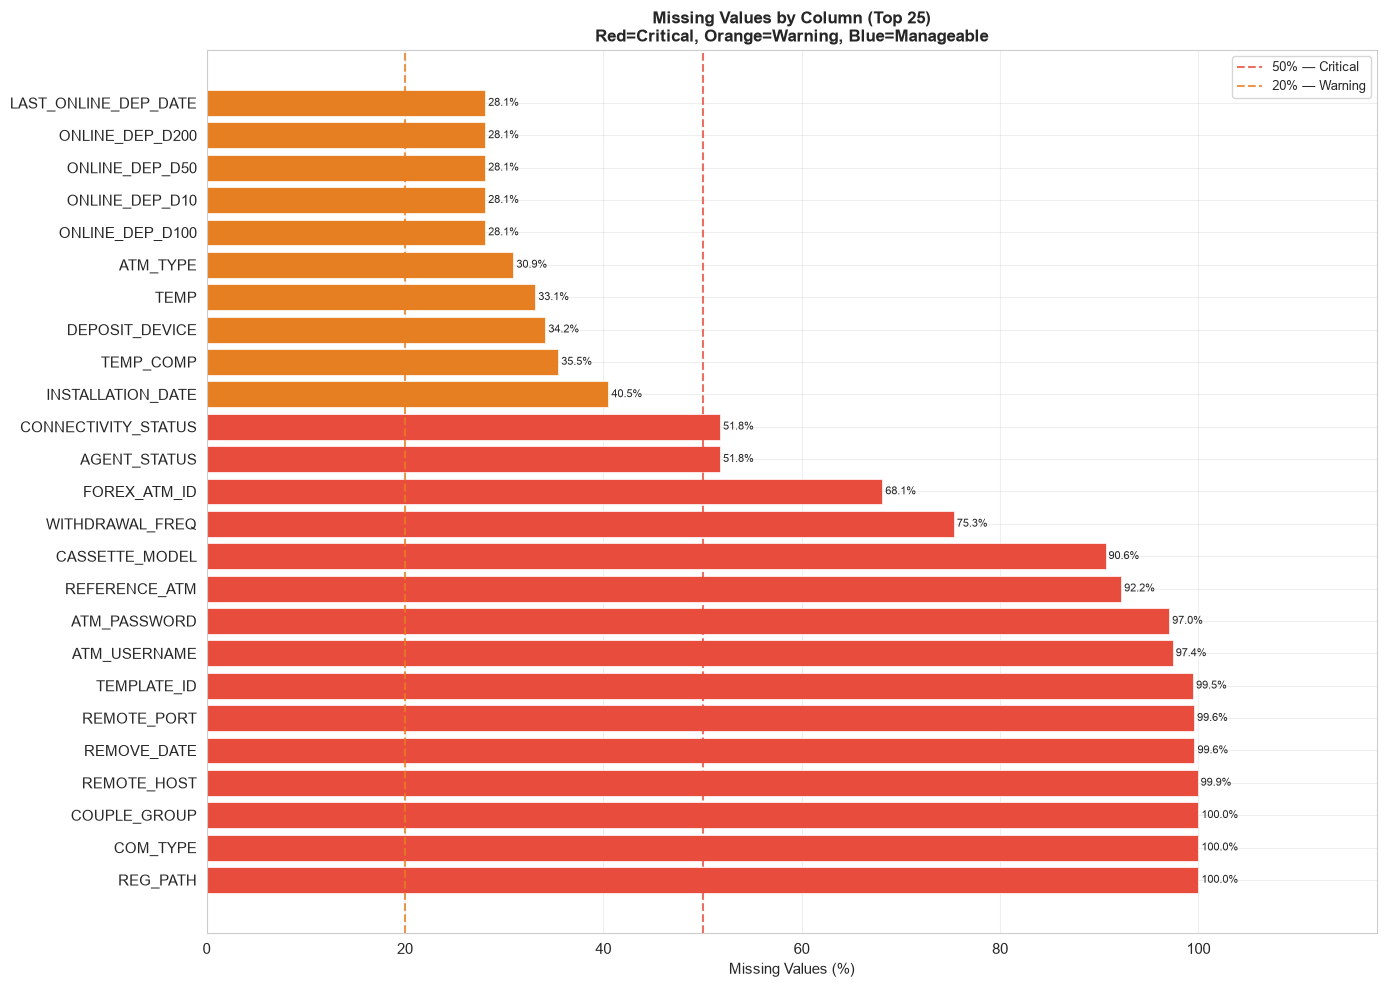

  📊  Saved: 04b_missing_values.png

▶ 4.9  DUPLICATE RECORDS────────────────────────────────────────────

  Transaction ID (ID) duplicates :        0
  Full-row duplicates           :        0
  [ATM_CODE, TRAN_DATE, AMOUNT] :        0

  ✅  Zero full-row duplicates detected!

▶ 4.10  ZERO AND NEGATIVE WITHDRAWALS───────────────────────────────

  Positive withdrawals : 1,152,112  (99.28%)
  Zero withdrawals     :    8,312  (0.72%)
  Negative withdrawals :        0  (0.00%)

  ⚠️   Zero withdrawals found!
  Possible causes:
    1. ATM was offline/down (check CONNECTIVITY_STATUS)
    2. ATM was empty (cash-out event)
    3. Day had deposits only (no withdrawals)
    4. Data entry error

  CONNECTIVITY_STATUS for zero-withdrawal rows:
  CONNECTIVITY_STATUS
Down    5103

▶ 4.11  WITHDRAWAL_AMOUNT DISTRIBUTION──────────────────────────────

  WITHDRAWAL_AMOUNT — Descriptive Statistics:
  ─────────────────────────────────────────────
  Count           :       1,160,424
  Min             :  

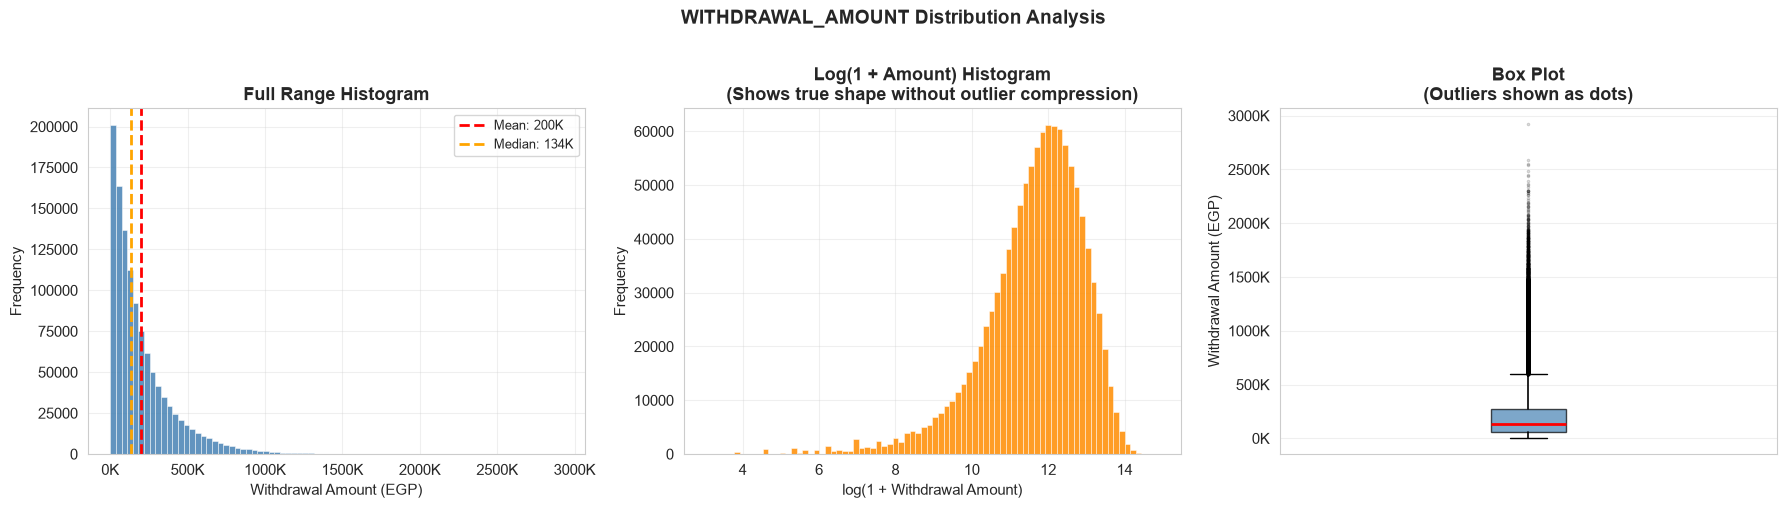

  📊  Saved: 04c_withdrawal_distribution.png

════════════════════════════════════════════════════════════════════
✅  INSPECTION COMPLETE — 11 STEPS DONE
════════════════════════════════════════════════════════════════════


In [3]:
# ============================================================
# CELL 4: COMPREHENSIVE DATASET INSPECTION
# ============================================================
# Tracking dict — collects findings for the Summary cell
findings = {}

print(SEP2)
print('🔍  COMPREHENSIVE DATASET INSPECTION — 11 STEPS')
print(SEP2)


# ════════════════════════════════════════════════════════════
# 4.1  PARSE TRAN_DATE
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.1  PARSE TRAN_DATE":─<68}')

print(f'  Expected format : {DATE_FMT}  (e.g., "4-Dec-24", "30-Nov-24")')
print(f'  Raw sample      : {df[DATE_COL].head(5).tolist()}')

try:
    df['TRAN_DATE_PARSED'] = pd.to_datetime(
    df[DATE_COL],
    errors='coerce')

    n_failed  = df['TRAN_DATE_PARSED'].isna().sum()
    n_success = len(df) - n_failed

    print(f'\n  ✅  Parsing complete:')
    print(f'     Successful : {n_success:>10,}  ({n_success/len(df)*100:.2f}%)')

    if n_failed > 0:
        print(f'     ⚠️  Failed   : {n_failed:>10,}  ({n_failed/len(df)*100:.2f}%)')
        bad_rows = df[df['TRAN_DATE_PARSED'].isna()][DATE_COL]
        print(f'     Bad samples : {bad_rows.head(5).tolist()}')
    else:
        print(f'     Failed      : 0  ✅  Zero parsing errors!')

    print(f'\n  Parsed samples:')
    parsed_sample = (df['TRAN_DATE_PARSED'].dropna().head(5)
                       .dt.strftime('%Y-%m-%d (%A)'))
    for s in parsed_sample:
        print(f'     {s}')

    findings['date_parse_failures'] = n_failed

except Exception as e:
    print(f'  ❌  Parsing ERROR: {e}')
    raise


# ════════════════════════════════════════════════════════════
# 4.2  WITHDRAWAL_AMOUNT CLEANING & VALIDATION
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.2  WITHDRAWAL_AMOUNT CLEANING":─<68}')

print(f'  Raw dtype       : {df[TARGET_COL].dtype}')
print(f'  Raw sample      : {df[TARGET_COL].head(5).tolist()}')

# Clean: remove commas/spaces that prevent numeric conversion
df[TARGET_COL] = (
    df[TARGET_COL]
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace(' ', '', regex=False)
)
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='coerce')

n_target_null = df[TARGET_COL].isna().sum()
print(f'\n  After conversion:')
print(f'     Dtype         : {df[TARGET_COL].dtype}')
print(f'     Null values   : {n_target_null:,}')
print(f'     Numeric range : {df[TARGET_COL].min():,.0f} → '
      f'{df[TARGET_COL].max():,.0f} EGP')

# Note on AMOUNT vs WITHDRAWAL_AMOUNT
if 'AMOUNT' in df.columns and 'WALLET_AMOUNT' in df.columns:
    df['AMOUNT'] = pd.to_numeric(
        df['AMOUNT'].astype(str).str.replace(',','').str.replace(' ',''),
        errors='coerce'
    )
    df['WALLET_AMOUNT']  = pd.to_numeric(df['WALLET_AMOUNT'], errors='coerce')
    df['FOREX_AMOUNT']   = pd.to_numeric(df['FOREX_AMOUNT'],  errors='coerce')

    equal_mask = (
        df['AMOUNT'].round(0) == df[TARGET_COL].round(0)
    )
    pct_equal  = equal_mask.sum() / len(df) * 100
    print(f'\n  ⚠️   AMOUNT vs WITHDRAWAL_AMOUNT:')
    print(f'     AMOUNT == WITHDRAWAL_AMOUNT : {pct_equal:.1f}% of rows')
    print(f'     → Confirms AMOUNT is leakage (contains target info)')
    print(f'     → Never use AMOUNT, WALLET_AMOUNT, or FOREX_AMOUNT as features')

findings['target_nulls'] = n_target_null


# ════════════════════════════════════════════════════════════
# 4.3  UNIQUE ATMs AND BANKS
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.3  UNIQUE ATMs AND BANKS":─<68}')

n_atms  = df[ATM_COL].nunique()
n_banks = df[BANK_COL].nunique() if BANK_COL in df.columns else None

print(f'\n  Unique ATMs   : {n_atms:>6,}')

if n_banks is not None:
    print(f'  Unique Banks  : {n_banks:>6,}')
    print(f'  ATMs / Bank   : {n_atms/n_banks:>6.1f}  (average)')

    # ATMs per bank breakdown
    atms_per_bank = (df.groupby(BANK_COL)[ATM_COL]
                       .nunique()
                       .sort_values(ascending=False)
                       .rename('ATM_Count'))
    print(f'\n  ATMs per Bank:')
    print(f'  {atms_per_bank.to_string()}')

# Check ACTIVE_FLAG if it exists
if 'ACTIVE_FLAG' in df.columns:
    print(f'\n  ACTIVE_FLAG distribution:')
    print(f'  {df.groupby(ATM_COL)["ACTIVE_FLAG"].first().value_counts().to_string()}')
    print(f'  ⚠️  Inactive ATMs may have zero or near-zero withdrawals')

# Check CONNECTIVITY_STATUS
if 'CONNECTIVITY_STATUS' in df.columns:
    cs_dist = df['CONNECTIVITY_STATUS'].value_counts()
    print(f'\n  CONNECTIVITY_STATUS distribution:')
    print(f'  {cs_dist.to_string()}')
    print(f'  ⚠️  "Down" status rows = ATM outage periods (may need exclusion)')

findings['n_atms']  = n_atms
findings['n_banks'] = n_banks


# ════════════════════════════════════════════════════════════
# 4.4  DATE RANGE
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.4  DATE RANGE":─<68}')

valid_dates = df['TRAN_DATE_PARSED'].dropna()
date_min    = valid_dates.min()
date_max    = valid_dates.max()
span_days   = (date_max - date_min).days

print(f'\n  Earliest date : {date_min.strftime("%Y-%m-%d")} ({date_min.strftime("%A")})')
print(f'  Latest date   : {date_max.strftime("%Y-%m-%d")} ({date_max.strftime("%A")})')
print(f'  Calendar span : {span_days} days  (~{span_days/30.4:.1f} months)')

print(f'\n  Monthly record counts:')
month_counts = (df.groupby(df['TRAN_DATE_PARSED'].dt.to_period('M'))
                   .size()
                   .rename('Records'))
for period, count in month_counts.items():
    bar_len = int(count / month_counts.max() * 25)
    bar = '█' * bar_len
    print(f'    {str(period):<10}  {count:>7,}  {bar}')

findings['date_min']   = date_min
findings['date_max']   = date_max
findings['span_days']  = span_days


# ════════════════════════════════════════════════════════════
# 4.5  DAYS PER ATM — DISTRIBUTION
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.5  TRANSACTION DAYS PER ATM":─<68}')

# Unique transaction dates per ATM (not calendar days — yet)
days_per_atm = (df.groupby(ATM_COL)['TRAN_DATE_PARSED']
                  .nunique()
                  .rename('TxnDays')
                  .sort_values())

print(f'\n  Min days  : {days_per_atm.min():>5}  '
      f'  ATM: {days_per_atm.idxmin()}')
print(f'  Max days  : {days_per_atm.max():>5}  '
      f'  ATM: {days_per_atm.idxmax()}')
print(f'  Mean days : {days_per_atm.mean():>5.1f}')
print(f'  Median    : {days_per_atm.median():>5.0f}')
print(f'  Std Dev   : {days_per_atm.std():>5.1f}')

print(f'\n  Percentile Distribution:')
for p in [5, 10, 25, 50, 75, 90, 95, 99]:
    print(f'    {p:>3}th pct : {days_per_atm.quantile(p/100):.0f} days')

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: histogram
axes[0].hist(days_per_atm, bins=40,
             color='steelblue', edgecolor='white',
             alpha=0.85, linewidth=0.6)
axes[0].axvline(days_per_atm.mean(),
                color='red', ls='--', lw=2,
                label=f'Mean: {days_per_atm.mean():.0f}d')
axes[0].axvline(MIN_DAYS_SPARSE,
                color='orange', ls='--', lw=2,
                label=f'{MIN_DAYS_SPARSE}d (sparse threshold)')
axes[0].axvline(MIN_DAYS_MODEL,
                color='green', ls='--', lw=2,
                label=f'{MIN_DAYS_MODEL}d (model-ready)')
axes[0].set_title('Distribution: Unique Transaction Days per ATM')
axes[0].set_xlabel('Unique Transaction Days')
axes[0].set_ylabel('Number of ATMs')
axes[0].legend(fontsize=9)

# Right: cumulative
sorted_days  = days_per_atm.sort_values().values
cumulative   = np.arange(1, len(sorted_days) + 1) / len(sorted_days) * 100
axes[1].plot(sorted_days, cumulative, color='steelblue', lw=2)
axes[1].axvline(MIN_DAYS_SPARSE, color='orange', ls='--', lw=2,
                label=f'{MIN_DAYS_SPARSE}d threshold')
axes[1].axvline(MIN_DAYS_MODEL, color='green', ls='--', lw=2,
                label=f'{MIN_DAYS_MODEL}d threshold')
axes[1].set_title('Cumulative % of ATMs by Days of Data')
axes[1].set_xlabel('Unique Transaction Days')
axes[1].set_ylabel('Cumulative % of ATMs')
axes[1].legend(fontsize=9)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())

plt.suptitle('Transaction Days per ATM', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('04a_days_per_atm.png', dpi=110, bbox_inches='tight')
plt.show()
print('  📊  Saved: 04a_days_per_atm.png')

findings['days_per_atm'] = days_per_atm


# ════════════════════════════════════════════════════════════
# 4.6  ATMs WITH < 30 DAYS (TOO SPARSE TO MODEL)
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.6  ATMs WITH INSUFFICIENT DATA":─<68}')

atms_lt30  = days_per_atm[days_per_atm < MIN_DAYS_SPARSE]
atms_lt60  = days_per_atm[days_per_atm < MIN_DAYS_MODEL]
atms_ge60  = days_per_atm[days_per_atm >= MIN_DAYS_MODEL]

print(f'\n  ATMs with < {MIN_DAYS_SPARSE} days (too sparse for any model)  : '
      f'{len(atms_lt30):>5,}')
print(f'  ATMs with {MIN_DAYS_SPARSE}–{MIN_DAYS_MODEL-1} days (borderline)        : '
      f'{len(atms_lt60) - len(atms_lt30):>5,}')
print(f'  ATMs with ≥ {MIN_DAYS_MODEL} days (model-ready)         : '
      f'{len(atms_ge60):>5,}')
print(f'  Total ATMs                                   : '
      f'{n_atms:>5,}')

if len(atms_lt30) > 0:
    print(f'\n  ATMs with < {MIN_DAYS_SPARSE} days of data:')
    sparse_df = atms_lt30.reset_index()
    sparse_df.columns = [ATM_COL, 'Days']
    print(sparse_df.to_string(index=False))
    print(f'\n  Recommendation: Exclude these ATMs from Part 3 modeling.')
else:
    print(f'\n  ✅  All ATMs have ≥ {MIN_DAYS_SPARSE} days of data!')

findings['atms_lt30']  = len(atms_lt30)
findings['atms_lt60']  = len(atms_lt60)
findings['atms_ge60']  = len(atms_ge60)


# ════════════════════════════════════════════════════════════
# 4.7  RECORDS PER ATM PER DAY — IS IT ALWAYS 1?
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.7  RECORDS PER ATM PER DAY":─<68}')

rpd = (df.dropna(subset=['TRAN_DATE_PARSED'])
         .groupby([ATM_COL, 'TRAN_DATE_PARSED'])
         .size()
         .rename('n_records'))

vc_rpd = rpd.value_counts().sort_index()
always_one = (rpd == 1).all()

print(f'\n  Total ATM-Day combinations : {len(rpd):>10,}')
print(f'\n  Records/Day  |  ATM-Day Pairs  |  % of Total  |  Bar Chart')
print(f'  {"─"*63}')
for n_rec, count in vc_rpd.items():
    pct = count / len(rpd) * 100
    bar = '█' * min(int(pct / 2), 35)
    print(f'  {n_rec:>11}  |  {count:>15,}  |  {pct:>10.2f}%  |  {bar}')

print(f'\n  Always 1 record per ATM-Day? → ', end='')
if always_one:
    print('YES ✅')
    print('\n  → Aggregation choice does not matter (SUM = MEAN for n=1)')
    print('  → But we use SUM anyway for consistency when new data arrives')
    AGGREGATION_METHOD = 'SUM'
    AGGREGATION_REASON = (
        'All ATM-days have exactly 1 record, so SUM = MEAN. '
        'SUM is preferred because it is semantically correct '
        '(total cash dispensed) and robust if future data has multiple records.'
    )
else:
    multi_pairs = (rpd > 1).sum()
    max_rpd     = rpd.max()
    print(f'NO ❌')
    print(f'\n  {multi_pairs:,} ATM-Day pairs have MORE than 1 record')
    print(f'  Maximum records in a single ATM-Day: {max_rpd}')
    print(f'\n  ┌────────────────────────────────────────────────────────────┐')
    print(f'  │  ✅  DECISION: USE SUM (not MEAN)                          │')
    print(f'  │                                                              │')
    print(f'  │  Business Reason:                                            │')
    print(f'  │  Multiple records = multiple refill/replenishment batches   │')
    print(f'  │  at the same ATM on the same day.                           │')
    print(f'  │                                                              │')
    print(f'  │  SUM → Total cash dispensed from ATM that day  ✅ CORRECT  │')
    print(f'  │  MEAN→ Avg per batch (under-counts true demand) ❌ WRONG   │')
    print(f'  │                                                              │')
    print(f'  │  Example: 200K morning batch + 300K afternoon batch        │')
    print(f'  │    SUM = 500K  (correct daily total)                        │')
    print(f'  │    MEAN= 250K  (severely underestimates demand)             │')
    print(f'  └────────────────────────────────────────────────────────────┘')
    AGGREGATION_METHOD = 'SUM'
    AGGREGATION_REASON = (
        'Multiple records per ATM-day represent different replenishment '
        'sessions. SUM gives the true total daily cash demand.'
    )

findings['aggregation_method'] = AGGREGATION_METHOD
findings['aggregation_reason'] = AGGREGATION_REASON
findings['always_one_record']  = always_one


# ════════════════════════════════════════════════════════════
# 4.8  MISSING VALUES PER COLUMN
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.8  MISSING VALUES":─<68}')

null_counts = df.isna().sum()
null_nonzero = null_counts[null_counts > 0].sort_values(ascending=False)

if len(null_nonzero) == 0:
    print('\n  ✅  No missing values in any column!')
    findings['n_cols_with_nulls'] = 0
else:
    null_df = pd.DataFrame({
        'Column'        : null_nonzero.index,
        'Missing_Count' : null_nonzero.values,
        'Missing_%'     : (null_nonzero / len(df) * 100).round(2).values,
        'Dtype'         : df[null_nonzero.index].dtypes.values.astype(str),
        'Severity'      : ['🔴 Critical' if p >= 50
                           else '🟠 Warning'  if p >= 20
                           else '🟡 Minor'
                           for p in (null_nonzero / len(df) * 100)]
    }).reset_index(drop=True)

    print(f'\n  Columns with missing values: {len(null_df)} / {df.shape[1]}')
    print(f'\n{null_df.to_string(index=False)}')

    # Categorize by severity
    crit  = null_df[null_df['Missing_%'] >= 50]
    warn  = null_df[(null_df['Missing_%'] >= 20) & (null_df['Missing_%'] < 50)]
    minor = null_df[null_df['Missing_%'] <  20]
    print(f'\n  Summary by Severity:')
    print(f'    🔴 Critical (≥50% missing) : {len(crit):>3} columns')
    print(f'    🟠 Warning  (20–49% missing): {len(warn):>3} columns')
    print(f'    🟡 Minor    (<20%  missing) : {len(minor):>3} columns')

    # Plot (top 25 most-missing columns)
    plot_null = null_df.head(25).copy()
    fig, ax = plt.subplots(figsize=(14, max(5, len(plot_null) * 0.40)))
    colors   = ['#e74c3c' if p >= 50
                else '#e67e22' if p >= 20
                else '#3498db'
                for p in plot_null['Missing_%']]
    bars = ax.barh(plot_null['Column'], plot_null['Missing_%'],
                   color=colors, edgecolor='white', linewidth=0.5)
    ax.axvline(50, color='#e74c3c', ls='--', lw=1.5, alpha=0.8,
               label='50% — Critical')
    ax.axvline(20, color='#e67e22', ls='--', lw=1.5, alpha=0.8,
               label='20% — Warning')
    for bar, val in zip(bars, plot_null['Missing_%']):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', fontsize=8)
    ax.set_title('Missing Values by Column (Top 25)\n'
                 'Red=Critical, Orange=Warning, Blue=Manageable',
                 fontsize=12)
    ax.set_xlabel('Missing Values (%)')
    ax.legend(fontsize=9)
    ax.set_xlim(0, plot_null['Missing_%'].max() * 1.18)
    plt.tight_layout()
    plt.savefig('04b_missing_values.png', dpi=110, bbox_inches='tight')
    plt.show()
    print('  📊  Saved: 04b_missing_values.png')

    findings['n_cols_with_nulls'] = len(null_df)
    findings['critical_null_cols'] = crit['Column'].tolist()


# ════════════════════════════════════════════════════════════
# 4.9  DUPLICATE RECORDS
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.9  DUPLICATE RECORDS":─<68}')

# Full-row duplicates
n_full_dup = df.duplicated().sum()

# ATM + Date duplicates (same ATM, same date, same amount)
if 'ID' in df.columns:
    n_txn_dup = df.duplicated(subset=['ID']).sum()
    print(f'\n  Transaction ID (ID) duplicates : {n_txn_dup:>8,}')

n_atm_date_dup = df.duplicated(
    subset=[ATM_COL, DATE_COL, TARGET_COL]
).sum()

print(f'  Full-row duplicates           : {n_full_dup:>8,}')
print(f'  [ATM_CODE, TRAN_DATE, AMOUNT] : {n_atm_date_dup:>8,}')

if n_full_dup > 0:
    print(f'\n  ⚠️  {n_full_dup} exact duplicate rows detected!')
    print(f'  Sample duplicate row:')
    dup_sample = df[df.duplicated(keep=False)].head(2)
    print(dup_sample[[ATM_COL, DATE_COL, TARGET_COL]].to_string())
    print(f'\n  → Will remove full duplicates before aggregation in Cell 5')
else:
    print(f'\n  ✅  Zero full-row duplicates detected!')

findings['n_full_duplicates']    = n_full_dup
findings['n_atm_date_dup']       = n_atm_date_dup


# ════════════════════════════════════════════════════════════
# 4.10  ZERO / NEGATIVE WITHDRAWALS
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.10  ZERO AND NEGATIVE WITHDRAWALS":─<68}')

valid_target = df[TARGET_COL].dropna()
n_zero  = (valid_target == 0).sum()
n_neg   = (valid_target < 0).sum()
n_pos   = (valid_target > 0).sum()

pct_zero = n_zero  / len(valid_target) * 100
pct_neg  = n_neg   / len(valid_target) * 100

print(f'\n  Positive withdrawals : {n_pos:>8,}  ({n_pos/len(valid_target)*100:.2f}%)')
print(f'  Zero withdrawals     : {n_zero:>8,}  ({pct_zero:.2f}%)')
print(f'  Negative withdrawals : {n_neg:>8,}  ({pct_neg:.2f}%)')

if n_zero > 0:
    print(f'\n  ⚠️   Zero withdrawals found!')
    print(f'  Possible causes:')
    print(f'    1. ATM was offline/down (check CONNECTIVITY_STATUS)')
    print(f'    2. ATM was empty (cash-out event)')
    print(f'    3. Day had deposits only (no withdrawals)')
    print(f'    4. Data entry error')

    # Cross-check with connectivity
    if 'CONNECTIVITY_STATUS' in df.columns:
        zero_rows   = df[df[TARGET_COL] == 0]
        cs_in_zeros = zero_rows['CONNECTIVITY_STATUS'].value_counts()
        print(f'\n  CONNECTIVITY_STATUS for zero-withdrawal rows:')
        print(f'  {cs_in_zeros.to_string()}')

if n_neg > 0:
    print(f'\n  ❌  {n_neg} NEGATIVE withdrawals found — likely data errors!')
    neg_sample = df[df[TARGET_COL] < 0][[ATM_COL, DATE_COL, TARGET_COL]].head(5)
    print(f'  Sample negative rows:')
    print(neg_sample.to_string(index=False))
    print(f'  → Will flag these in Part 2 cleaning step')

findings['n_zero_withdrawals']    = n_zero
findings['n_negative_withdrawals']= n_neg


# ════════════════════════════════════════════════════════════
# 4.11  WITHDRAWAL_AMOUNT DISTRIBUTION
# ════════════════════════════════════════════════════════════
print(f'\n{"▶ 4.11  WITHDRAWAL_AMOUNT DISTRIBUTION":─<68}')

wa = df[TARGET_COL].dropna()

# Descriptive statistics
desc_stats = {
    'Count'       : len(wa),
    'Min'         : wa.min(),
    'Max'         : wa.max(),
    'Mean'        : wa.mean(),
    'Median'      : wa.median(),
    'Std Dev'     : wa.std(),
    'Variance'    : wa.var(),
    'Skewness'    : wa.skew(),
    'Kurtosis'    : wa.kurtosis(),
    '1st Pct'     : wa.quantile(0.01),
    '5th Pct'     : wa.quantile(0.05),
    '25th Pct'    : wa.quantile(0.25),
    '75th Pct'    : wa.quantile(0.75),
    '95th Pct'    : wa.quantile(0.95),
    '99th Pct'    : wa.quantile(0.99),
}

print(f'\n  WITHDRAWAL_AMOUNT — Descriptive Statistics:')
print(f'  {"─"*45}')
for stat, val in desc_stats.items():
    if stat == 'Count':
        print(f'  {stat:<15} : {int(val):>15,}')
    elif stat in ['Skewness', 'Kurtosis']:
        print(f'  {stat:<15} : {val:>15.4f}')
    else:
        print(f'  {stat:<15} : {val:>15,.0f} EGP')

# Interpret skewness
sk = wa.skew()
if abs(sk) < 0.5:
    sk_label = 'approximately symmetric'
elif sk > 0:
    sk_label = f'right-skewed (positively) → long tail at high values'
else:
    sk_label = f'left-skewed (negatively) → long tail at low values'
print(f'\n  Skewness interpretation: {sk_label}')
if abs(sk) > 1:
    print(f'  → Log transformation likely needed before modeling')

# 3-Panel distribution plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('WITHDRAWAL_AMOUNT Distribution Analysis',
             fontsize=14, fontweight='bold', y=1.01)

# Panel 1: Full range histogram
axes[0].hist(wa, bins=80, color='steelblue',
             edgecolor='white', alpha=0.85, linewidth=0.4)
axes[0].axvline(wa.mean(),   color='red',    ls='--', lw=2,
                label=f'Mean: {wa.mean()/1e3:.0f}K')
axes[0].axvline(wa.median(), color='orange', ls='--', lw=2,
                label=f'Median: {wa.median()/1e3:.0f}K')
axes[0].set_title('Full Range Histogram')
axes[0].set_xlabel('Withdrawal Amount (EGP)')
axes[0].set_ylabel('Frequency')
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)
axes[0].legend(fontsize=9)

# Panel 2: Log-scale histogram
wa_nonzero = wa[wa > 0]
axes[1].hist(np.log1p(wa_nonzero), bins=80,
             color='darkorange', edgecolor='white',
             alpha=0.85, linewidth=0.4)
axes[1].set_title('Log(1 + Amount) Histogram\n(Shows true shape without outlier compression)')
axes[1].set_xlabel('log(1 + Withdrawal Amount)')
axes[1].set_ylabel('Frequency')

# Panel 3: Box plot
bp = axes[2].boxplot(wa, patch_artist=True, notch=False,
                     boxprops    =dict(facecolor='steelblue', alpha=0.7),
                     medianprops =dict(color='red', linewidth=2),
                     whiskerprops=dict(linewidth=1.2),
                     flierprops  =dict(marker='.', alpha=0.2, markersize=3))
axes[2].set_title('Box Plot\n(Outliers shown as dots)')
axes[2].set_ylabel('Withdrawal Amount (EGP)')
axes[2].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)
axes[2].set_xticks([])

plt.tight_layout()
plt.savefig('04c_withdrawal_distribution.png', dpi=110, bbox_inches='tight')
plt.show()
print('  📊  Saved: 04c_withdrawal_distribution.png')

print(f'\n{SEP2}')
print('✅  INSPECTION COMPLETE — 11 STEPS DONE')
print(SEP2)

findings['wa_mean']   = wa.mean()
findings['wa_median'] = wa.median()
findings['wa_max']    = wa.max()
findings['wa_skew']   = wa.skew()

In [ ]:
# ============================================================
# CELL 5: DAILY AGGREGATION
# ============================================================
# Target: daily_df with one row per ATM per day
# Method: SUM
# MOD 1: No Imputation — Keep Only Real Transaction Days
# ============================================================

print(SEP2)
print('📊  DAILY AGGREGATION: PER ATM PER DAY')
print(SEP2)

# ── Step 1: Remove Full Duplicates ────────────────────────
n_before = len(df)
df_clean = df.drop_duplicates()
n_after  = len(df_clean)

if n_before != n_after:
    print(f'  Removed {n_before - n_after:,} full duplicate rows')
else:
    print(f'  ✅  No full duplicates to remove')

# ── Step 2: Filter Valid Rows ─────────────────────────────
valid_mask = (
    df_clean['TRAN_DATE_PARSED'].notna() &
    df_clean[TARGET_COL].notna()
)
df_valid  = df_clean[valid_mask].copy()
n_dropped = len(df_clean) - len(df_valid)

print(f'  Rows with valid date AND withdrawal : {len(df_valid):>10,}')
if n_dropped > 0:
    print(f'  Rows dropped (null date or amount)  : {n_dropped:>10,}')

# ── Step 3: Aggregate ─────────────────────────────────────
print(f'\n  Aggregating: SUM per ({ATM_COL}, TRAN_DATE_PARSED) ...')

daily_df = (
    df_valid
    .groupby([ATM_COL, 'TRAN_DATE_PARSED'], as_index=False)
    .agg(
        DAILY_WITHDRAWAL = (TARGET_COL, 'sum'),
        N_RECORDS        = (TARGET_COL, 'count'),
        MAX_SINGLE_TXN   = (TARGET_COL, 'max'),
    )
    .rename(columns={'TRAN_DATE_PARSED': 'TRAN_DATE'})
    .sort_values([ATM_COL, 'TRAN_DATE'])
    .reset_index(drop=True)
)

# ── ✅ MOD 1: Keep Only Real Transaction Days ─────────────
# بدل ما نملأ الأيام الناقصة بصفر أو Forward Fill
# نشيل الأيام اللي مفيش فيها سحب حقيقي خالص
before_mod1 = len(daily_df)
daily_df = daily_df[daily_df['DAILY_WITHDRAWAL'] > 0].copy()
after_mod1  = len(daily_df)

print(f'\n  ✅ MOD 1: No Imputation Applied!')
print(f'     Before : {before_mod1:>10,} rows')
print(f'     After  : {after_mod1:>10,} rows')
print(f'     Removed: {before_mod1 - after_mod1:>10,} zero rows')
print(f'     → Real transaction days only ✅')
print(f'     → الجمعة والسبت موجودين لأن فيهم سحب حقيقي ✅')

# ── Step 4: Add Calendar Features ────────────────────────
daily_df['DAY_OF_WEEK']      = daily_df['TRAN_DATE'].dt.dayofweek
daily_df['DAY_OF_WEEK_NAME'] = daily_df['TRAN_DATE'].dt.day_name()
daily_df['DAY_OF_MONTH']     = daily_df['TRAN_DATE'].dt.day
daily_df['IS_WEEKEND']       = daily_df['DAY_OF_WEEK'].isin(
    EGYPT_WEEKEND_DAYS
).astype(int)

# ── Step 5: Attach Static ATM Features ───────────────────
static_cols = [
    ATM_COL, BANK_COL,
    'C2_DENOM', 'DEPOSIT_SUPPORT', 'MAX_TARGET_AMOUNT',
    'MORNING', 'EVENING', 'WEEKEND', 'HOLIDAY',
    'FLM_SP_ID', 'SLM_SP_ID', 'SLM_ZONE_ID',
    'ONLINE_DEP_D50', 'ONLINE_DEP_D100', 'ONLINE_DEP_D200',
    'MAX_REFILL_DURATION', 'WITHDRAWAL_FREQ',
    'ATM_TYPE', 'ATM_VENDOR',
    'CIT_ZONE_NAME', 'FLM_ZONE_NAME', 'SLM_ZONE_NAME',
    'CONNECTIVITY_STATUS', 'ACTIVE_FLAG'
]

static_cols_existing    = [c for c in static_cols if c in df.columns]
missing_static          = [c for c in static_cols if c not in df.columns]
static_cols_for_groupby = [c for c in static_cols_existing if c != ATM_COL]

if missing_static:
    print(f'\n  ⚠️   Static columns not found: {missing_static}')

static_info = (
    df_valid
    .groupby(ATM_COL)[static_cols_for_groupby]
    .first()
    .reset_index()
)

daily_df = daily_df.merge(static_info, on=ATM_COL, how='left')

print(f'\n  ✅  Aggregation complete!')

# ── Step 6: Validate & Inspect ────────────────────────────
print(f'\n{SEP}')
print('  DAILY_DF — SHAPE & STRUCTURE')
print(SEP)
print(f'  Rows    : {daily_df.shape[0]:>10,}')
print(f'  Columns : {daily_df.shape[1]:>10,}')

print(f'\n  Column List:')
for i, col in enumerate(daily_df.columns):
    dtype = daily_df[col].dtype
    print(f'    [{i:>2}] {col:<30} {str(dtype):<15}')

# Records-per-day sanity check
print(f'\n  Multi-record ATM-Days (N_RECORDS > 1):')
multi_rec = daily_df[daily_df['N_RECORDS'] > 1]
if len(multi_rec) == 0:
    print(f'    ✅  Zero — every ATM-Day had exactly 1 source record')
else:
    print(f'    {len(multi_rec):,} ATM-Days had multiple records '
          f'(max: {daily_df["N_RECORDS"].max()} records in one day)')
    print(f'    → SUM correctly captures total cash for those days')

# Sample output
print(f'\n  Sample rows (first 10):')
sample_cols = [ATM_COL, 'TRAN_DATE', 'DAILY_WITHDRAWAL',
               'N_RECORDS', 'DAY_OF_WEEK_NAME', 'DAY_OF_MONTH']
print(daily_df[sample_cols].head(10).to_string(index=False))

# ── Verify Weekend Has Real Values (MOD 1 Proof) ──────────
print(f'\n  ✅ MOD 1 Verification — Weekend Has Real Values:')
print(f'  {"─"*55}')
print(f'  {"Day":<12} {"Avg":>12} {"Count":>10}')
print(f'  {"─"*55}')

day_order = [
    'Monday','Tuesday','Wednesday',
    'Thursday','Friday','Saturday','Sunday'
]
for day in day_order:
    mask = daily_df['DAY_OF_WEEK_NAME'] == day
    if mask.sum() > 0:
        avg = daily_df[mask]['DAILY_WITHDRAWAL'].mean()
        cnt = mask.sum()
        flag = ''
        if day in ['Friday', 'Saturday']:
            flag = '← ويكند مش صفر! ✅'
        elif day == 'Thursday':
            flag = '← Peak'
        print(f'  {day:<12} {avg:>12,.0f} {cnt:>10,}  {flag}')

# Per-ATM summary
atm_summary = (
    daily_df
    .groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .agg(['count', 'sum', 'mean', 'max'])
    .rename(columns={
        'count': 'N_Days',
        'sum'  : 'Total_Withdrawal',
        'mean' : 'Avg_Daily',
        'max'  : 'Max_Daily'
    })
    .sort_values('Total_Withdrawal', ascending=False)
)

print(f'\n  Per-ATM Summary (Top 10 by Total Withdrawal):')
print(atm_summary.head(10).to_string())
print(f'\n  Per-ATM Summary (Bottom 5 by Total Withdrawal):')
print(atm_summary.tail(5).to_string())

# Stats
print(f'\n  DAILY_WITHDRAWAL Statistics:')
dw_stats = daily_df['DAILY_WITHDRAWAL'].describe()
for stat, val in dw_stats.items():
    print(f'    {stat:<10} : {val:>15,.0f} EGP')

print(f'\n{SEP2}')
print(f'✅  DAILY AGGREGATION COMPLETE — MOD 1 APPLIED')
print(f'    daily_df: {daily_df.shape[0]:,} rows × {daily_df.shape[1]} columns')
print(f'    No Imputation — Real Data Only ✅')
print(SEP2)

════════════════════════════════════════════════════════════════════
📊  DAILY AGGREGATION: PER ATM PER DAY
════════════════════════════════════════════════════════════════════
  ✅  No full duplicates to remove
  Rows with valid date AND withdrawal :  1,160,424

  Aggregating: SUM per (ATM_ID, TRAN_DATE_PARSED) ...

  ✅  Aggregation complete!

────────────────────────────────────────────────────────────────────
  DAILY_DF — SHAPE & STRUCTURE
────────────────────────────────────────────────────────────────────
  Rows    :  1,160,424
  Columns :         32

  Column List:
    [ 0] ATM_ID                         int64          
    [ 1] TRAN_DATE                      datetime64[ns] 
    [ 2] DAILY_WITHDRAWAL               int64          
    [ 3] N_RECORDS                      int64          
    [ 4] MAX_SINGLE_TXN                 int64          
    [ 5] DAY_OF_WEEK                    int32          
    [ 6] DAY_OF_WEEK_NAME               object         
    [ 7] DAY_OF_MONTH           

════════════════════════════════════════════════════════════════════
📅  MISSING DATES ANALYSIS — PER ATM
════════════════════════════════════════════════════════════════════

  Egypt Weekend Days : Friday + Saturday
  Holidays in scope  : 9
    2025-01-07 (Tuesday) → Coptic Christmas
    2025-04-25 (Friday) → Sinai Liberation Day
    2025-05-01 (Thursday) → Labour Day
    2025-06-30 (Monday) → June 30 Revolution
    2025-07-23 (Wednesday) → Revolution Day
    2025-10-06 (Monday) → Armed Forces Day
    2026-01-07 (Wednesday) → Coptic Christmas
    2026-04-25 (Saturday) → Sinai Liberation Day
    2026-05-01 (Friday) → Labour Day

  Analyzing missing dates for 2572 ATMs ...

  Missing Dates Summary — Sorted by Missing %:
────────────────────────────────────────────────────────────────────
 ATM_ID  Calendar_Days  Present_Days  Missing_Total  Missing_Weekend  Missing_Holiday  Missing_Unknown  Missing_%  Unknown_%
  16450            548            91            457              136          

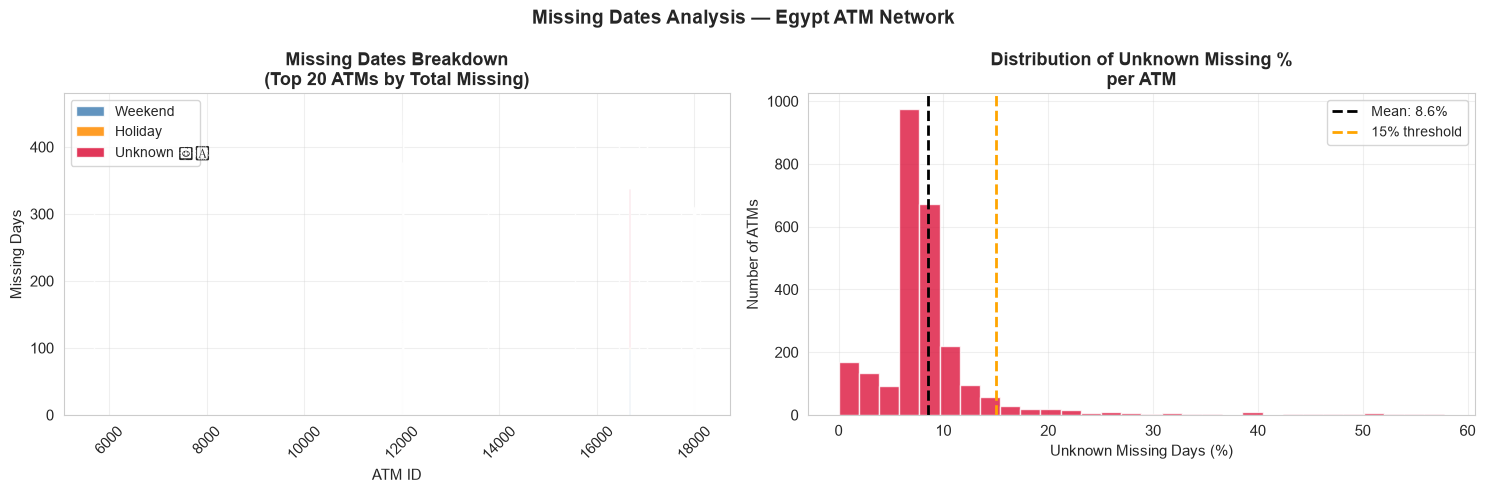

  📊  Saved: 06_missing_dates_analysis.png

════════════════════════════════════════════════════════════════════
✅  MISSING DATES ANALYSIS COMPLETE
════════════════════════════════════════════════════════════════════


In [ ]:
# ============================================================
# CELL 6: MISSING DATES ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(SEP2)
print('📅  MISSING DATES ANALYSIS — PER ATM')
print(SEP2)

# ✅ تعريف الـ Holidays الصح
EGYPT_HOLIDAYS = {
    pd.Timestamp('2025-01-07'): 'Coptic Christmas',
    pd.Timestamp('2025-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2025-05-01'): 'Labour Day',
    pd.Timestamp('2025-06-30'): 'June 30 Revolution',
    pd.Timestamp('2025-07-23'): 'Revolution Day',
    pd.Timestamp('2025-10-06'): 'Armed Forces Day',
    pd.Timestamp('2026-01-07'): 'Coptic Christmas',
    pd.Timestamp('2026-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2026-05-01'): 'Labour Day',
}

EGYPT_WEEKEND_DAYS = [4, 5]  # Friday=4, Saturday=5

# ✅ إصلاح
holiday_set  = set(EGYPT_HOLIDAYS.keys())
weekend_days = set(EGYPT_WEEKEND_DAYS)

print(f'\n  Egypt Weekend Days : Friday + Saturday')
print(f'  Holidays in scope  : {len(EGYPT_HOLIDAYS)}')
for dt, name in EGYPT_HOLIDAYS.items():
    print(f'    {dt.strftime("%Y-%m-%d")} ({dt.strftime("%A")}) → {name}')

# ── Per-ATM Missing Date Analysis ────────────────────────────
print(f'\n  Analyzing missing dates for {daily_df[ATM_COL].nunique()} ATMs ...')

records_list = []

for atm_code, atm_group in daily_df.groupby(ATM_COL):

    actual_dates = set(atm_group['TRAN_DATE'].dt.normalize())

    date_min_atm = atm_group['TRAN_DATE'].min().normalize()
    date_max_atm = atm_group['TRAN_DATE'].max().normalize()
    full_range   = pd.date_range(
        start=date_min_atm,
        end=date_max_atm,
        freq='D'
    )
    total_calendar_days = len(full_range)

    missing_dates = [d for d in full_range if d not in actual_dates]

    n_weekend = 0
    n_holiday = 0
    n_unknown = 0
    unknown_dates = []

    for d in missing_dates:
        if d.dayofweek in weekend_days:
            n_weekend += 1
        elif d in holiday_set:
            n_holiday += 1
        else:
            n_unknown += 1
            unknown_dates.append(d)

    records_list.append({
        ATM_COL          : atm_code,
        'Calendar_Days'  : total_calendar_days,
        'Present_Days'   : len(actual_dates),
        'Missing_Total'  : len(missing_dates),
        'Missing_Weekend': n_weekend,
        'Missing_Holiday': n_holiday,
        'Missing_Unknown': n_unknown,
        'Missing_%'      : round(len(missing_dates) / total_calendar_days * 100, 1),
        'Unknown_%'      : round(n_unknown / max(total_calendar_days, 1) * 100, 1),
        'Unknown_Dates'  : unknown_dates,
    })

missing_summary = pd.DataFrame(records_list)

# ── Display Summary ───────────────────────────────────────────
display_cols = [
    ATM_COL, 'Calendar_Days', 'Present_Days',
    'Missing_Total', 'Missing_Weekend', 'Missing_Holiday',
    'Missing_Unknown', 'Missing_%', 'Unknown_%'
]
display_df = missing_summary[display_cols].sort_values(
    'Missing_%', ascending=False
)

print(f'\n  Missing Dates Summary — Sorted by Missing %:')
print(SEP)
print(display_df.to_string(index=False))

# ── Aggregate Stats ───────────────────────────────────────────
print(f'\n{SEP}')
print('  AGGREGATE STATISTICS ACROSS ALL ATMs')
print(SEP)

total_missing  = missing_summary['Missing_Total'].sum()
total_weekend  = missing_summary['Missing_Weekend'].sum()
total_holiday  = missing_summary['Missing_Holiday'].sum()
total_unknown  = missing_summary['Missing_Unknown'].sum()
total_calendar = missing_summary['Calendar_Days'].sum()
total_present  = missing_summary['Present_Days'].sum()

print(f'\n  Total ATM-Day slots : {total_calendar:>10,}')
print(f'  Present             : {total_present:>10,}  ({total_present/total_calendar*100:.1f}%)')
print(f'  Missing (total)     : {total_missing:>10,}  ({total_missing/total_calendar*100:.1f}%)')
print(f'    ↳ Weekend         : {total_weekend:>10,}  ({total_weekend/total_calendar*100:.1f}%)')
print(f'    ↳ Holiday         : {total_holiday:>10,}  ({total_holiday/total_calendar*100:.1f}%)')
print(f'    ↳ Unknown         : {total_unknown:>10,}  ({total_unknown/total_calendar*100:.1f}%)')

# ── ATMs with High Unknown % ──────────────────────────────────
print(f'\n{SEP}')
print('  ⚠️   ATMs WITH HIGH UNKNOWN MISSING % (>15%)')
print(SEP)

high_unknown = missing_summary[
    missing_summary['Unknown_%'] > 15
].sort_values('Unknown_%', ascending=False)

if len(high_unknown) == 0:
    print('\n  ✅  No ATMs with >15% unexplained missing dates!')
else:
    print(f'\n  {len(high_unknown)} ATMs with >15% unexplained missing days:')
    print(high_unknown[display_cols].to_string(index=False))

# ── Weekend Pattern ───────────────────────────────────────────
print(f'\n{SEP}')
print('  WEEKEND PATTERN VALIDATION')
print(SEP)

dow_withdrawal = (
    daily_df
    .groupby('DAY_OF_WEEK_NAME')['DAILY_WITHDRAWAL']
    .agg(['mean', 'count'])
    .round(0)
)
dow_order = ['Monday','Tuesday','Wednesday','Thursday',
             'Friday','Saturday','Sunday']
dow_withdrawal = dow_withdrawal.reindex(
    [d for d in dow_order if d in dow_withdrawal.index]
)

print(f'\n  Average Daily Withdrawal by Day of Week:')
for day, row in dow_withdrawal.iterrows():
    is_weekend = '🏖️  WEEKEND' if day in ['Friday','Saturday'] else ''
    bar_len    = int(row['mean'] / dow_withdrawal['mean'].max() * 30)
    bar        = '█' * bar_len
    print(f'  {day:<12} : {row["mean"]:>12,.0f} EGP  |  {bar:<30}  {is_weekend}')

# ── Visualization ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Stacked bar
top_missing_atms = (
    missing_summary
    .sort_values('Missing_Total', ascending=False)
    .head(20)
    .set_index(ATM_COL)
)

bottom_vals = top_missing_atms['Missing_Weekend']
axes[0].bar(top_missing_atms.index,
            top_missing_atms['Missing_Weekend'],
            label='Weekend',    color='steelblue',  alpha=0.85)
axes[0].bar(top_missing_atms.index,
            top_missing_atms['Missing_Holiday'],
            bottom=bottom_vals,
            label='Holiday',    color='darkorange', alpha=0.85)
axes[0].bar(top_missing_atms.index,
            top_missing_atms['Missing_Unknown'],
            bottom=bottom_vals + top_missing_atms['Missing_Holiday'],
            label='Unknown ⚠️', color='crimson',    alpha=0.85)
axes[0].set_title('Missing Dates Breakdown\n(Top 20 ATMs by Total Missing)')
axes[0].set_xlabel('ATM ID')
axes[0].set_ylabel('Missing Days')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(fontsize=10)

# Right: Histogram
axes[1].hist(missing_summary['Unknown_%'], bins=30,
             color='crimson', edgecolor='white', alpha=0.8)
axes[1].axvline(missing_summary['Unknown_%'].mean(),
                color='black', ls='--', lw=2,
                label=f'Mean: {missing_summary["Unknown_%"].mean():.1f}%')
axes[1].axvline(15, color='orange', ls='--', lw=2,
                label='15% threshold')
axes[1].set_title('Distribution of Unknown Missing %\nper ATM')
axes[1].set_xlabel('Unknown Missing Days (%)')
axes[1].set_ylabel('Number of ATMs')
axes[1].legend(fontsize=10)

plt.suptitle('Missing Dates Analysis — Egypt ATM Network',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('06_missing_dates_analysis.png', dpi=110, bbox_inches='tight')
plt.show()
print('  📊  Saved: 06_missing_dates_analysis.png')

print(f'\n{SEP2}')
print('✅  MISSING DATES ANALYSIS COMPLETE')
print(SEP2)

# Store
findings['total_missing']      = total_missing
findings['total_weekend_miss'] = total_weekend
findings['total_holiday_miss'] = total_holiday
findings['total_unknown_miss'] = total_unknown
findings['missing_summary']    = missing_summary

════════════════════════════════════════════════════════════════════
📊  TIME SERIES VISUALIZATION — 7 ATMs
════════════════════════════════════════════════════════════════════
  Selected ATMs for visualization:
    [Top 1    ] 6758            Total:     408,264,800 EGP  |  530 days
    [Top 2    ] 11521           Total:     379,667,900 EGP  |  531 days
    [Top 3    ] 10600           Total:     377,653,950 EGP  |  521 days
    [Bottom 1 ] 19500           Total:           8,200 EGP  |  5 days
    [Bottom 2 ] 19340           Total:           4,700 EGP  |  1 days
    [Bottom 3 ] 19269           Total:               0 EGP  |  31 days
    [Random   ] 9348            Total:     155,586,550 EGP  |  527 days


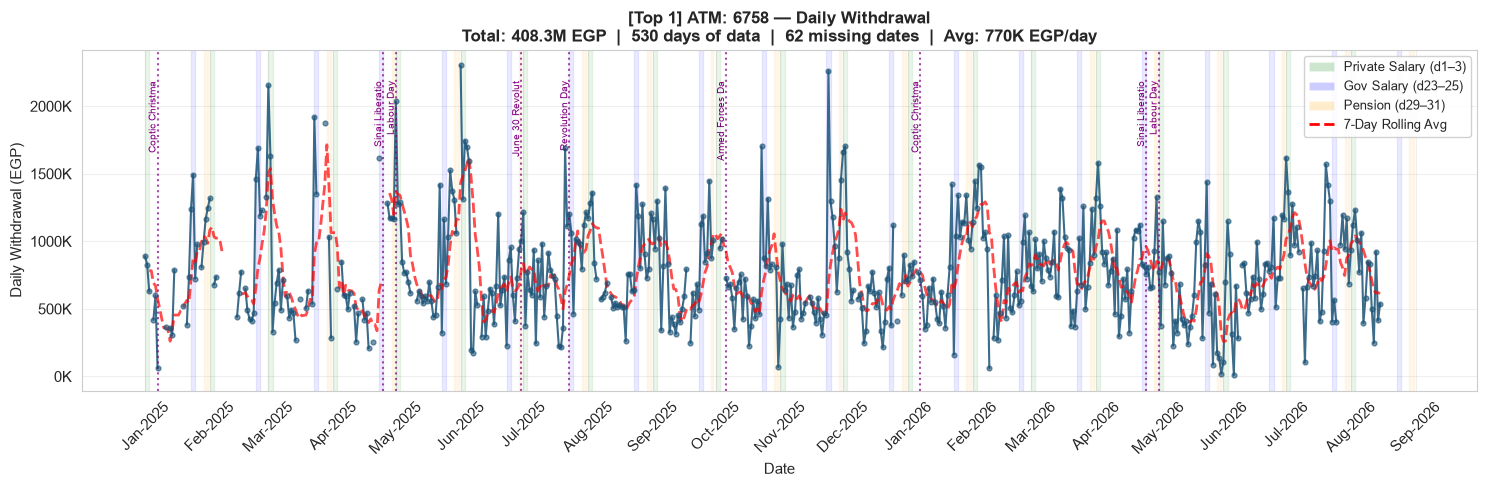

  📊  Saved: 07_ts_Top_1_6758.png



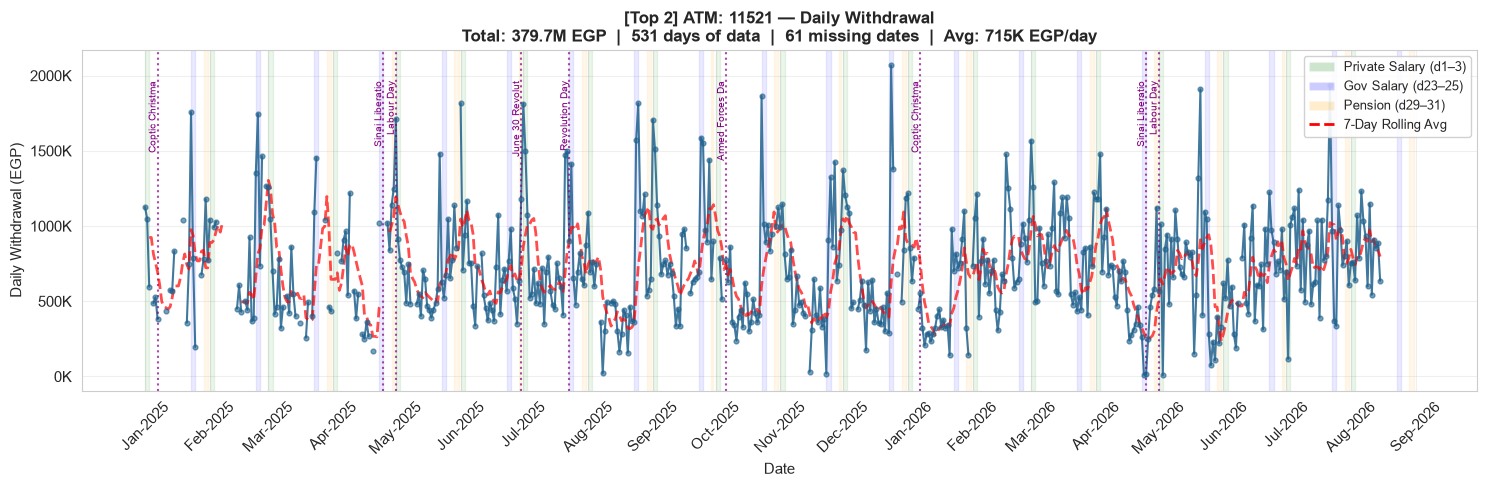

  📊  Saved: 07_ts_Top_2_11521.png



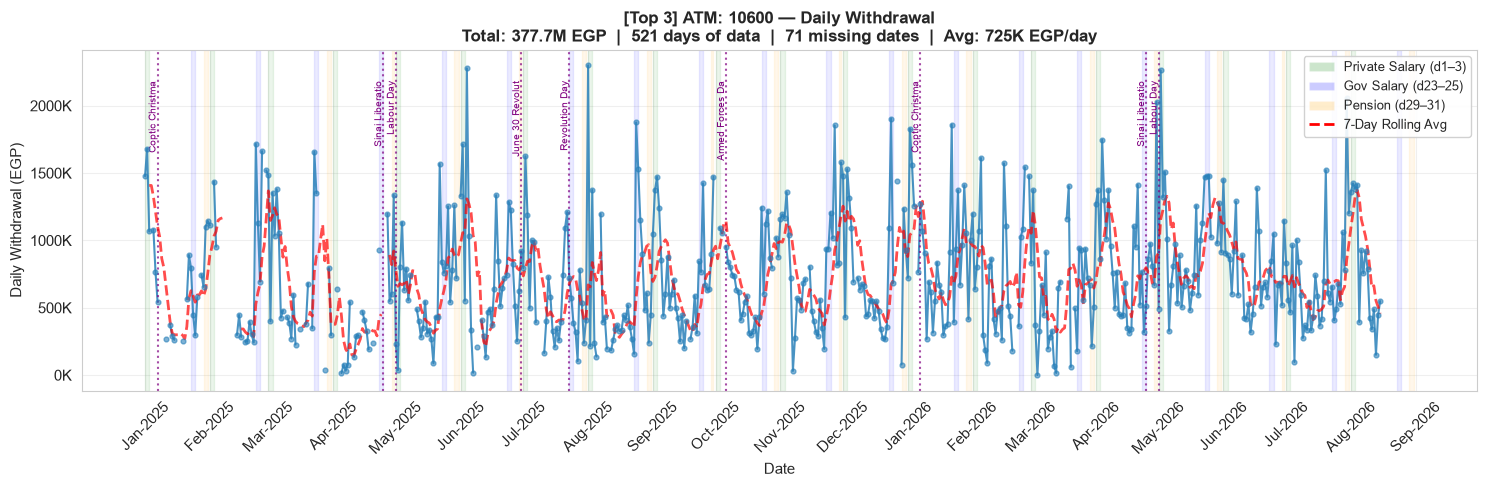

  📊  Saved: 07_ts_Top_3_10600.png



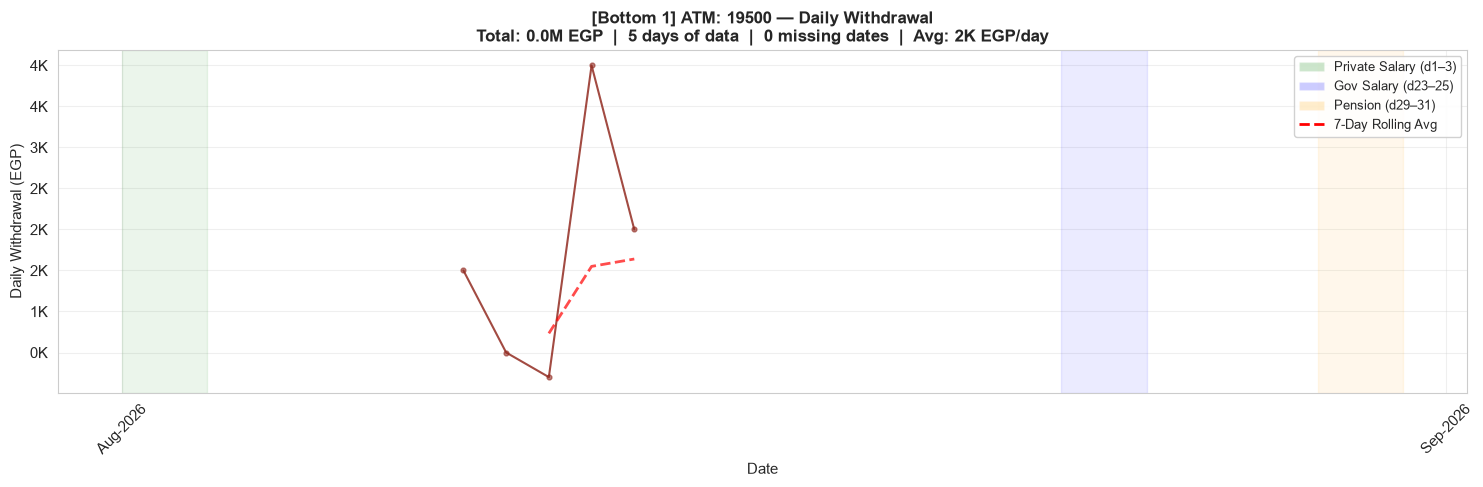

  📊  Saved: 07_ts_Bottom_1_19500.png



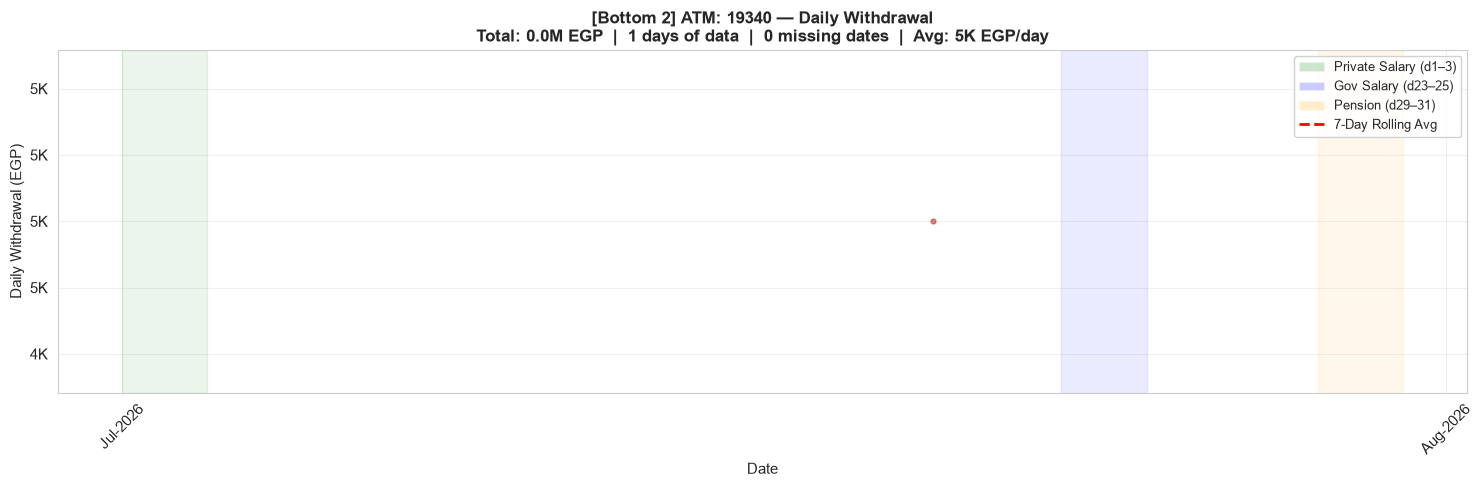

  📊  Saved: 07_ts_Bottom_2_19340.png



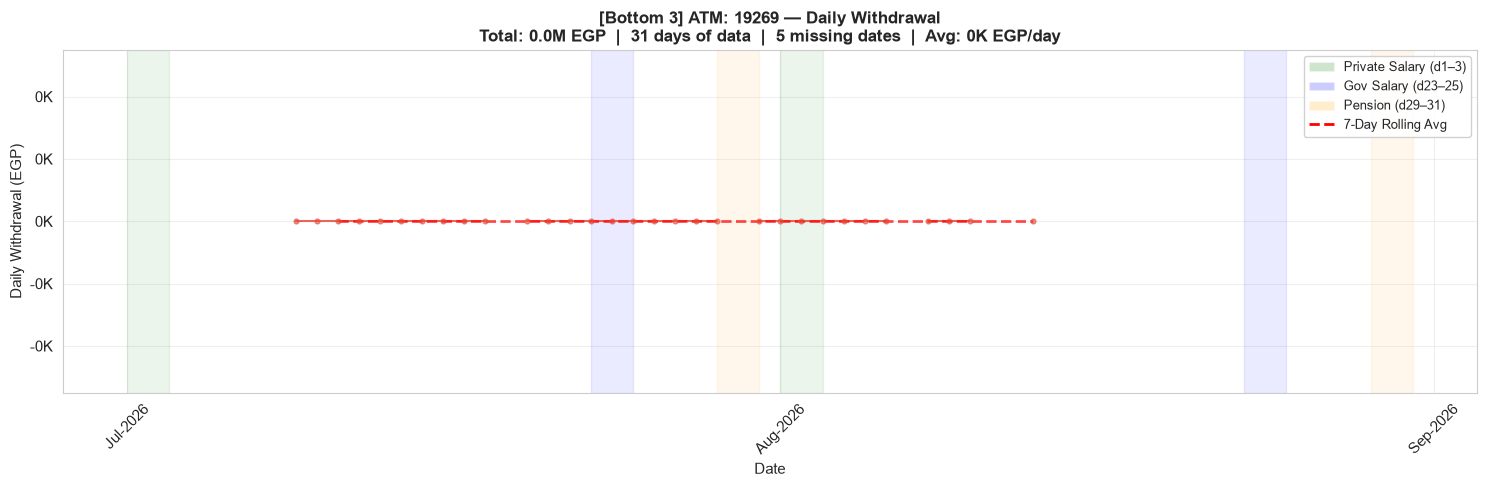

  📊  Saved: 07_ts_Bottom_3_19269.png



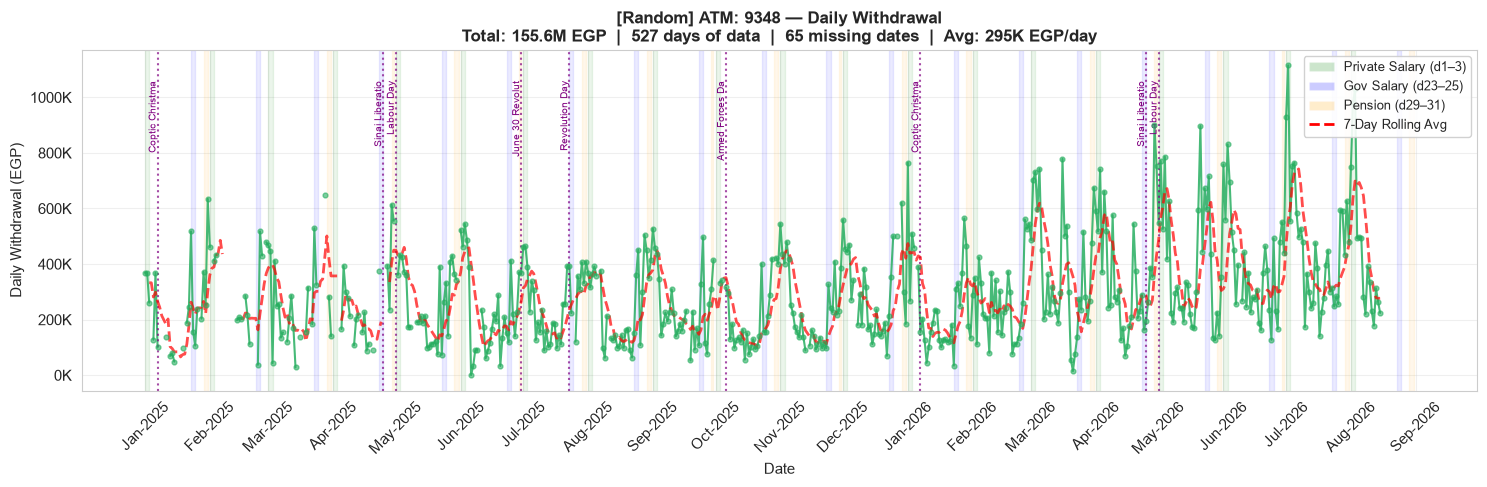

  📊  Saved: 07_ts_Random_9348.png

════════════════════════════════════════════════════════════════════
✅  TIME SERIES VISUALIZATION COMPLETE
════════════════════════════════════════════════════════════════════


In [6]:
# ============================================================
# CELL 7: TIME SERIES VISUALIZATION
# ============================================================

# ✅ تأكد إن EGYPT_HOLIDAYS dict مش set
EGYPT_HOLIDAYS = {
    pd.Timestamp('2025-01-07'): 'Coptic Christmas',
    pd.Timestamp('2025-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2025-05-01'): 'Labour Day',
    pd.Timestamp('2025-06-30'): 'June 30 Revolution',
    pd.Timestamp('2025-07-23'): 'Revolution Day',
    pd.Timestamp('2025-10-06'): 'Armed Forces Day',
    pd.Timestamp('2026-01-07'): 'Coptic Christmas',
    pd.Timestamp('2026-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2026-05-01'): 'Labour Day',
}

print(SEP2)
print('📊  TIME SERIES VISUALIZATION — 7 ATMs')
print(SEP2)

atm_totals = (daily_df
              .groupby(ATM_COL)['DAILY_WITHDRAWAL']
              .sum()
              .sort_values(ascending=False))

top3    = atm_totals.head(3).index.tolist()
bottom3 = atm_totals.tail(3).index.tolist()

remaining = [a for a in atm_totals.index
             if a not in top3 + bottom3]
rand_atm  = random.choice(remaining) if remaining else top3[0]

atms_to_plot = top3 + bottom3 + [rand_atm]
labels       = (
    [f'Top {i+1}' for i in range(3)] +
    [f'Bottom {i+1}' for i in range(3)] +
    ['Random']
)

print(f'  Selected ATMs for visualization:')
for atm, label in zip(atms_to_plot, labels):
    total = atm_totals.get(atm, 0)
    days  = (daily_df[daily_df[ATM_COL] == atm].shape[0])
    print(f'    [{label:<9}] {str(atm):<15} '
          f'Total: {total:>15,.0f} EGP  |  {days} days')

def add_salary_shading(ax, date_min, date_max):
    current = date_min.replace(day=1)
    while current <= date_max:
        month_end = (current.replace(day=28) + timedelta(days=4))
        month_end = month_end - timedelta(days=month_end.day)
        try:
            ax.axvspan(current.replace(day=1),
                       min(current.replace(day=3), month_end),
                       alpha=0.08, color='green', label='_nolegend_')
            ax.axvspan(current.replace(day=23),
                       min(current.replace(day=25), month_end),
                       alpha=0.08, color='blue', label='_nolegend_')
            ax.axvspan(current.replace(day=29),
                       month_end,
                       alpha=0.08, color='orange', label='_nolegend_')
        except ValueError:
            pass
        if current.month == 12:
            current = current.replace(year=current.year + 1, month=1, day=1)
        else:
            current = current.replace(month=current.month + 1, day=1)

colors_by_group = {
    'Top 1': '#1a5276',  'Top 2': '#1f618d', 'Top 3': '#2980b9',
    'Bottom 1': '#922b21', 'Bottom 2': '#c0392b', 'Bottom 3': '#e74c3c',
    'Random': '#27ae60',
}

for atm_code, label in zip(atms_to_plot, labels):

    atm_data = (daily_df[daily_df[ATM_COL] == atm_code]
                .set_index('TRAN_DATE')['DAILY_WITHDRAWAL']
                .sort_index())

    full_range    = pd.date_range(
        start=atm_data.index.min(),
        end=atm_data.index.max(),
        freq='D'
    )
    atm_reindexed = atm_data.reindex(full_range)

    total_wd  = atm_data.sum()
    n_days    = len(atm_data)
    avg_daily = atm_data.mean()
    n_missing = atm_reindexed.isna().sum()

    fig, ax = plt.subplots(figsize=(15, 5))

    add_salary_shading(ax, full_range[0], full_range[-1])

    ax.plot(atm_reindexed.index,
            atm_reindexed.values,
            color=colors_by_group[label],
            linewidth=1.5, alpha=0.85)

    ax.scatter(atm_data.index, atm_data.values,
               color=colors_by_group[label],
               s=12, alpha=0.6, zorder=5)

    # ✅ إصلاح هنا
    for hol_date, hol_name in EGYPT_HOLIDAYS.items():
        if full_range[0] <= hol_date <= full_range[-1]:
            ax.axvline(hol_date, color='purple',
                       ls=':', lw=1.5, alpha=0.7)
            ax.text(hol_date, atm_data.max() * 0.95,
                    hol_name.split('(')[0][:15],
                    fontsize=7, color='purple', rotation=90,
                    va='top', ha='right')

    rolling_7 = atm_reindexed.rolling(7, min_periods=3).mean()
    ax.plot(rolling_7.index, rolling_7.values,
            color='red', linewidth=2, ls='--',
            alpha=0.7, label='7-Day Rolling Avg')

    ax.set_title(
        f'[{label}] ATM: {atm_code} — Daily Withdrawal\n'
        f'Total: {total_wd/1e6:.1f}M EGP  |  '
        f'{n_days} days of data  |  '
        f'{n_missing} missing dates  |  '
        f'Avg: {avg_daily/1e3:.0f}K EGP/day',
        fontsize=12, fontweight='bold'
    )
    ax.set_xlabel('Date', fontsize=11)
    ax.set_ylabel('Daily Withdrawal (EGP)', fontsize=11)
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.xticks(rotation=45)

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='green',  alpha=0.2, label='Private Salary (d1–3)'),
        Patch(facecolor='blue',   alpha=0.2, label='Gov Salary (d23–25)'),
        Patch(facecolor='orange', alpha=0.2, label='Pension (d29–31)'),
        plt.Line2D([0], [0], color='red', ls='--', lw=2,
                   label='7-Day Rolling Avg'),
    ]
    ax.legend(handles=legend_elements, loc='upper right',
              fontsize=9, framealpha=0.9)

    plt.tight_layout()
    safe_name = str(atm_code).replace('/', '_')
    filename  = f'07_ts_{label.replace(" ", "_")}_{safe_name}.png'
    plt.savefig(filename, dpi=110, bbox_inches='tight')
    plt.show()
    print(f'  📊  Saved: {filename}')
    print()

print(SEP2)
print('✅  TIME SERIES VISUALIZATION COMPLETE')
print(SEP2)

In [7]:
# ============================================================
# SUMMARY CELL: COMPLETE PART 1 FINDINGS
# ============================================================

print('=' * 72)
print('  🏧  ATM WITHDRAWAL FORECASTING — PART 1 COMPLETE SUMMARY')
print('=' * 72)

# ── 1. Dataset Overview ──────────────────────────────────────
print(f'\n{"━" * 72}')
print('  1️⃣   DATASET OVERVIEW')
print(f'{"━" * 72}')
print(f'\n  Source files  : ATMs_Conf.csv + With_From-01-Jan-2025.csv + With_From-01-Jan-2026.csv')
print(f'  Merge key     : ATM_ID (inner join)')
print(f'  Raw shape     : {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'  Clean records : {len(daily_df):,} rows in daily_df')
print(f'\n  ATM Identifier: ATM_ID (numeric identifier)')

# ── 2. ATM & Bank Statistics ─────────────────────────────────
print(f'\n{"━" * 72}')
print('  2️⃣   ATM & BANK STATISTICS')
print(f'{"━" * 72}')
print(f'\n  Total unique ATMs              : {findings["n_atms"]:>8,}')
if findings['n_banks']:
    print(f'  Total unique Banks             : {findings["n_banks"]:>8,}')
    print(f'  Average ATMs per Bank          : {findings["n_atms"]/findings["n_banks"]:>8.1f}')
print(f'\n  ATMs with < {MIN_DAYS_SPARSE} days (too sparse)  : '
      f'{findings["atms_lt30"]:>8,}')
print(f'  ATMs with {MIN_DAYS_SPARSE}–{MIN_DAYS_MODEL-1} days (borderline): '
      f'{findings["atms_lt60"]-findings["atms_lt30"]:>8,}')
print(f'  ATMs with ≥ {MIN_DAYS_MODEL} days (model-ready) : '
      f'{findings["atms_ge60"]:>8,}  ← USE THESE FOR MODELING')

# ── 3. Date Range ────────────────────────────────────────────
print(f'\n{"━" * 72}')
print('  3️⃣   DATE RANGE')
print(f'{"━" * 72}')
print(f'\n  Earliest date  : {findings["date_min"].strftime("%Y-%m-%d")} '
      f'({findings["date_min"].strftime("%A")})')
print(f'  Latest date    : {findings["date_max"].strftime("%Y-%m-%d")} '
      f'({findings["date_max"].strftime("%A")})')
print(f'  Calendar span  : {findings["span_days"]} days  '
      f'(~{findings["span_days"]/30.4:.1f} months)')
print(f'\n  ✅  19 months of data (Jan 2025 – Aug 2026)')
print(f'  → MONTH feature useful for seasonal patterns')
print(f'  → Enough data for reliable lag & rolling features')

# ── 4. Average Daily Withdrawal ──────────────────────────────
print(f'\n{"━" * 72}')
print('  4️⃣   WITHDRAWAL STATISTICS')
print(f'{"━" * 72}')
avg_per_atm_day = daily_df['DAILY_WITHDRAWAL'].mean()
med_per_atm_day = daily_df['DAILY_WITHDRAWAL'].median()
total_system    = daily_df['DAILY_WITHDRAWAL'].sum()

print(f'\n  Average daily withdrawal per ATM  : {avg_per_atm_day:>15,.0f} EGP')
print(f'  Median  daily withdrawal per ATM  : {med_per_atm_day:>15,.0f} EGP')
print(f'  Max     daily withdrawal (any ATM): {findings["wa_max"]:>15,.0f} EGP')
print(f'  Total system withdrawal (all data): {total_system:>15,.0f} EGP')
print(f'\n  Distribution skewness: {findings["wa_skew"]:.3f}')
if findings['wa_skew'] > 1:
    print(f'  → Heavy right skew detected!')
    print(f'  → Consider log(DAILY_WITHDRAWAL) as model target in Part 3')
    print(f'  → Or use models robust to skew (XGBoost, quantile regression)')

# ── 5. Aggregation Decision ──────────────────────────────────
print(f'\n{"━" * 72}')
print('  5️⃣   AGGREGATION METHOD')
print(f'{"━" * 72}')
print(f'\n  ✅  Recommended: {findings["aggregation_method"]}')
print(f'  Reason: {findings["aggregation_reason"]}')
print(f'\n  Correct grouping: (ATM_ID, TRAN_DATE) → per-ATM daily total.')

# ── 6. Missing Dates Summary ─────────────────────────────────
print(f'\n{"━" * 72}')
print('  6️⃣   MISSING DATES')
print(f'{"━" * 72}')
ms = findings.get('missing_summary', pd.DataFrame())
if not ms.empty:
    total_cal = ms['Calendar_Days'].sum()
    print(f'\n  Total calendar ATM-Days (all ATMs)    : {total_cal:>10,}')
    print(f'  Days with actual data                  : {ms["Present_Days"].sum():>10,}  '
          f'({ms["Present_Days"].sum()/total_cal*100:.1f}%)')
    print(f'  Missing — Weekend (Fri/Sat)            : '
          f'{findings["total_weekend_miss"]:>10,}  '
          f'({findings["total_weekend_miss"]/total_cal*100:.1f}%)  ← Expected ✅')
    print(f'  Missing — Holiday (known)              : '
          f'{findings["total_holiday_miss"]:>10,}  '
          f'({findings["total_holiday_miss"]/total_cal*100:.1f}%)  ← Expected ✅')
    print(f'  Missing — Unknown (unexplained)        : '
          f'{findings["total_unknown_miss"]:>10,}  '
          f'({findings["total_unknown_miss"]/total_cal*100:.1f}%)  ← Investigate ⚠️')
    print(f'\n  Imputation strategy (for Part 2):')
    print(f'    Weekend/Holiday → Fill with 0 (closed)')
    print(f'    Unknown         → Forward-fill or ATM-specific mean')

# ── 7. Data Quality Issues ───────────────────────────────────
print(f'\n{"━" * 72}')
print('  7️⃣   DATA QUALITY ISSUES — COMPLETE LIST')
print(f'{"━" * 72}')

issues = []
if findings.get('date_parse_failures', 0) > 0:
    issues.append(('🔴', 'Date Parse Failures',
                   f'{findings["date_parse_failures"]:,} rows',
                   'Exclude from analysis'))
if findings.get('n_negative_withdrawals', 0) > 0:
    issues.append(('🔴', 'Negative Withdrawals',
                   f'{findings["n_negative_withdrawals"]:,} rows',
                   'Investigate & remove in Part 2'))
if findings.get('n_zero_withdrawals', 0) > 0:
    issues.append(('🟠', 'Zero Withdrawals',
                   f'{findings["n_zero_withdrawals"]:,} rows',
                   'Check if ATM was down/empty'))
if findings.get('n_full_duplicates', 0) > 0:
    issues.append(('🟠', 'Duplicate Rows',
                   f'{findings["n_full_duplicates"]:,} rows',
                   'Removed before aggregation'))
if findings.get('n_cols_with_nulls', 0) > 0:
    issues.append(('🟡', 'Columns with Nulls',
                   f'{findings["n_cols_with_nulls"]} columns',
                   'Handle in Part 2 per column'))
if findings.get('atms_lt30', 0) > 0:
    issues.append(('🟡', 'Sparse ATMs (<30 days)',
                   f'{findings["atms_lt30"]:,} ATMs',
                   'Exclude from modeling'))
if findings.get('wa_skew', 0) > 1:
    issues.append(('🟡', 'Right-Skewed Target',
                   f'Skewness = {findings["wa_skew"]:.2f}',
                   'Consider log transform in Part 3'))

issues.append(('⚠️ ', 'AMOUNT = Leakage',
               'AMOUNT ≈ WITHDRAWAL_AMOUNT',
               'Never use AMOUNT/WALLET/FOREX as features'))

print(f'\n  {"Sev":<4}  {"Issue":<30}  {"Detail":<30}  {"Action"}')
print(f'  {"─"*68}')
for sev, issue, detail, action in issues:
    print(f'  {sev}  {issue:<30}  {detail:<30}  {action}')

# ── 8. Features Summary ──────────────────────────────────────
print(f'\n{"━" * 72}')
print('  8️⃣   FEATURE STATUS (from confirmed EDA)')
print(f'{"━" * 72}')
print(f"""
  ✅  CONFIRMED USEFUL:
      IS_PRIVATE_SALARY, IS_GOV_SALARY, IS_PENSION  ← Salary cycle
      IS_PRE_WEEKEND, IS_WEEKEND                     ← Day patterns
      DEPOSIT_SUPPORT                                ← ATM config
      MAX_TARGET_AMOUNT                              ← Capacity
      ONLINE_DEP_D50, D100, D200                     ← Denomination mix
      C2_DENOM, EVENING, MAX_REFILL_DURATION         ← Operations
      BANK_ID, FLM_SP_ID, SLM_SP_ID, SLM_ZONE_ID    ← Geography
      WITHDRAWAL_FREQ                                ← ATM behavior

  ❌  CONFIRMED USELESS / DANGEROUS (EXCLUDE):
      AMOUNT, WALLET_AMOUNT, FOREX_AMOUNT → DATA LEAKAGE (= target)
      ATM_ID (as feature) → Identifier, not predictor
      TEMPLATE_ID, REMOTE_PORT, REG_PATH  → Technical identifiers
      BANK_RESPONSIBILITY                 → Not significant

  🔲  TO BE DECIDED IN PART 2:
      ACTIVE_FLAG, CONNECTIVITY_STATUS    → May indicate outages
      RECYCLE_FLAG                        → Unknown impact
      ONLINEBAL_C1, C2, C3               → Balance indicators
      ATM_LINE, COMPANY_ID               → Unclear business meaning
""")

# ── 9. Modeling Readiness ────────────────────────────────────
print(f'{"━" * 72}')
print('  9️⃣   MODELING READINESS ASSESSMENT')
print(f'{"━" * 72}')
print(f"""
  daily_df is ready for Part 2 feature engineering:
  ┌─────────────────────────────────────────────────────────────┐
  │  Rows        : {len(daily_df):>8,} (one per ATM per txn day)       │
  │  ATMs total  : {findings["n_atms"]:>8,}                                  │
  │  Model-ready : {findings["atms_ge60"]:>8,} ATMs with ≥ {MIN_DAYS_MODEL} days             │
  │  Target      : DAILY_WITHDRAWAL (EGP, right-skewed)         │
  │  Aggregation : SUM (total daily cash dispensed)             │
  └─────────────────────────────────────────────────────────────┘
""")

# ── 10. Next Steps for Part 2 ────────────────────────────────
print(f'{"━" * 72}')
print('  🔟  NEXT STEPS — PART 2: FEATURE ENGINEERING')
print(f'{"━" * 72}')
print(f"""
  1. IMPUTE missing dates:
     → Weekend/Holiday → 0
     → Unknown         → forward-fill or ATM-specific mean

  2. BUILD lag features:
     → LAG_7, LAG_14, LAG_21, LAG_28

  3. BUILD rolling features:
     → ROLLING_MEAN_7, ROLLING_MEAN_14, ROLLING_MEAN_28
     → ROLLING_STD_7, ROLLING_MAX_7

  4. BUILD calendar features:
     → IS_PRIVATE_SALARY (days 1–3)
     → IS_GOV_SALARY     (days 23–25)
     → IS_PENSION        (days 29–31)
     → IS_PRE_WEEKEND    (Thursday)
     → IS_WEEKEND        (Friday/Saturday)

  5. ENCODE static ATM features:
     → Target-encode BANK_ID, SLM_ZONE_ID, FLM_SP_ID
     → Binary: DEPOSIT_SUPPORT, MORNING, EVENING

  6. HANDLE outliers:
     → Upper Winsorize at 99th percentile per ATM
     → OR use log(DAILY_WITHDRAWAL) as model target

  7. TRAIN/TEST SPLIT:
     → Train: Jan 2025 – May 2026  (17 months)
     → Test : Jun 2026 – Aug 2026  (3 months = holdout)
""")

print('=' * 72)
print('  ✅  PART 1 COMPLETE — DATA UNDERSTANDING DONE')
print('      Ready to proceed to PART 2: Feature Engineering')
print('=' * 72)

  🏧  ATM WITHDRAWAL FORECASTING — PART 1 COMPLETE SUMMARY

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  1️⃣   DATASET OVERVIEW
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Source files  : ATMs_Conf.csv + With_From-01-Jan-2025.csv + With_From-01-Jan-2026.csv
  Merge key     : ATM_ID (inner join)
  Raw shape     : 1,160,424 rows × 94 columns
  Clean records : 1,160,424 rows in daily_df

  ATM Identifier: ATM_ID (numeric identifier)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  2️⃣   ATM & BANK STATISTICS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Total unique ATMs              :    2,572
  Total unique Banks             :        8
  Average ATMs per Bank          :    321.5

  ATMs with < 30 days (too sparse)  :       16
  ATMs with 30–59 days (borderline):       49
  ATMs with ≥ 60 days (model-ready) :    2,507  ← USE THESE FOR MODELING

━━━━━━━━━━━━━━━━━━━━━━━━━━━

STEP 1: MISSING DATES IMPUTATION

▶ Step 1.1: Building Complete Date Range per ATM
  قبل  :  1,160,424 rows
  بعد  :  1,340,924 rows
  Added:    180,500 missing date rows

▶ Step 1.2: Classifying Missing Dates

  Type              Count        %
  ────────────────────────────────
  present       1,160,424    86.5%
  unknown         120,283     9.0%
  weekend          58,207     4.3%
  holiday           2,010     0.1%

▶ Step 1.3: Filling Missing Values
  ✅ Weekend + Holiday → filled with 0
  ✅ Unknown → Forward Fill then Backward Fill

▶ Step 1.4: Filling Static ATM Info for New Rows
  ✅ Static columns filled: 21

▶ Step 1.5: Re-adding Calendar Columns

▶ Step 1.6: Validation
  Remaining nulls in DAILY_WITHDRAWAL: 0
  ✅ Zero nulls — Imputation complete!

  Final full_df shape: (1340924, 34)

▶ Step 1.7: Visualization — Before vs After


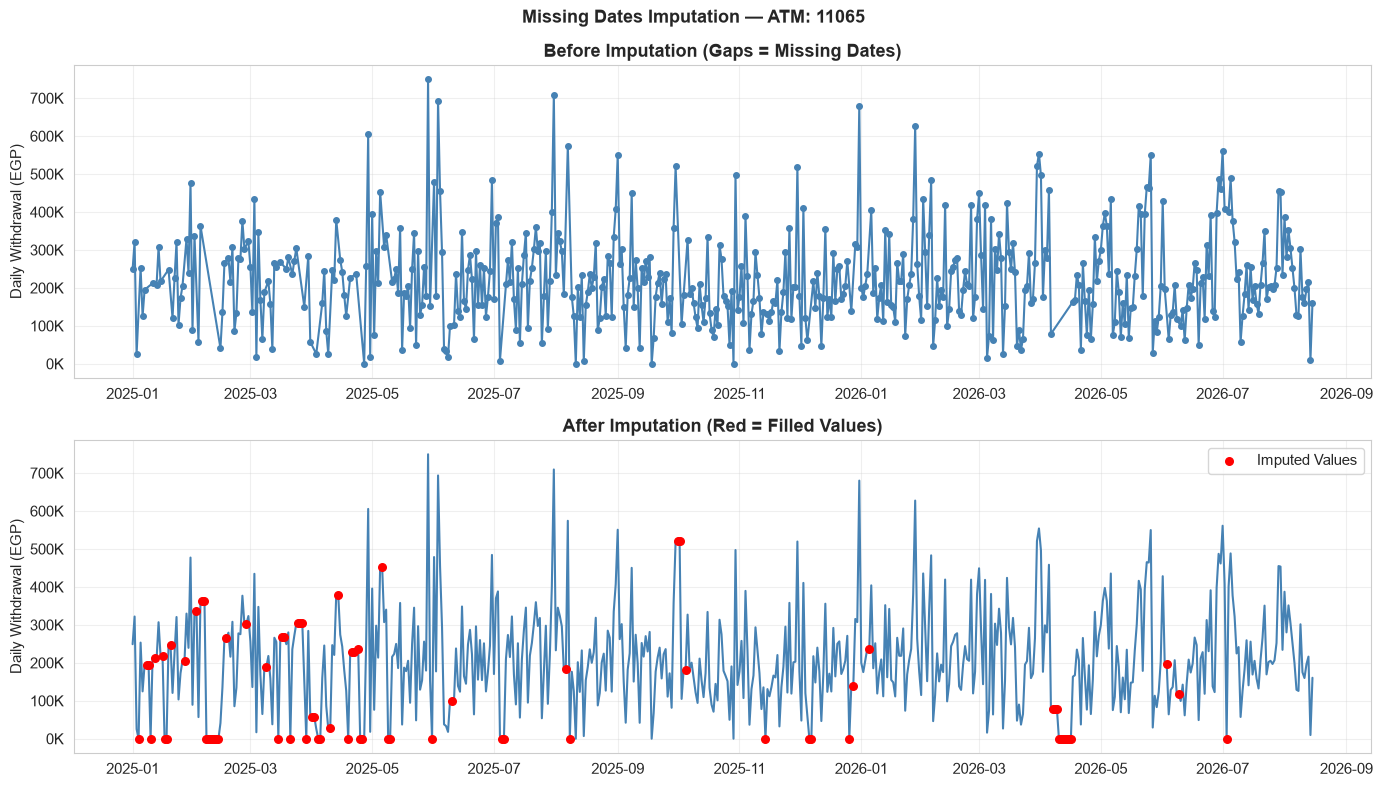


✅ STEP 1 COMPLETE
   full_df: 1,340,924 rows × 34 columns


In [8]:
# ============================================================
# PART 2 - STEP 1: MISSING DATES IMPUTATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 60)
print("STEP 1: MISSING DATES IMPUTATION")
print("=" * 60)

# ── الـ Constants ────────────────────────────────────────
EGYPT_WEEKEND_DAYS = [4, 5]  # Friday=4, Saturday=5

# ✅ تواريخ صح 2025-2026
EGYPT_HOLIDAYS = {
    pd.Timestamp('2025-01-07'): 'Coptic Christmas',
    pd.Timestamp('2025-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2025-05-01'): 'Labour Day',
    pd.Timestamp('2025-06-30'): 'June 30 Revolution',
    pd.Timestamp('2025-07-23'): 'Revolution Day',
    pd.Timestamp('2025-10-06'): 'Armed Forces Day',
    pd.Timestamp('2026-01-07'): 'Coptic Christmas',
    pd.Timestamp('2026-04-25'): 'Sinai Liberation Day',
    pd.Timestamp('2026-05-01'): 'Labour Day',
}
holiday_set = set(EGYPT_HOLIDAYS.keys())  # ✅

# ── Step 1.1: اعمل Complete Date Range لكل ATM ──────────
print("\n▶ Step 1.1: Building Complete Date Range per ATM")

all_atms     = daily_df[ATM_COL].unique()
complete_dfs = []

for atm_code in all_atms:
    atm_data = (daily_df[daily_df[ATM_COL] == atm_code]
                .set_index('TRAN_DATE')
                .sort_index())

    full_range = pd.date_range(
        start=atm_data.index.min(),
        end=atm_data.index.max(),
        freq='D'
    )

    atm_complete = atm_data.reindex(full_range)
    atm_complete.index.name = 'TRAN_DATE'
    atm_complete[ATM_COL]   = atm_code
    complete_dfs.append(atm_complete)

full_df = pd.concat(complete_dfs).reset_index()

print(f"  قبل  : {len(daily_df):>10,} rows")
print(f"  بعد  : {len(full_df):>10,} rows")
print(f"  Added: {len(full_df) - len(daily_df):>10,} missing date rows")

# ── Step 1.2: Classify Missing Dates ────────────────────
print("\n▶ Step 1.2: Classifying Missing Dates")

missing_mask = full_df['DAILY_WITHDRAWAL'].isna()

full_df['IS_MISSING']   = missing_mask.astype(int)
full_df['MISSING_TYPE'] = 'present'

weekend_mask = (
    missing_mask &
    full_df['TRAN_DATE'].dt.dayofweek.isin(EGYPT_WEEKEND_DAYS)
)
full_df.loc[weekend_mask, 'MISSING_TYPE'] = 'weekend'

holiday_mask = (
    missing_mask &
    full_df['TRAN_DATE'].isin(holiday_set)
)
full_df.loc[holiday_mask, 'MISSING_TYPE'] = 'holiday'

unknown_mask = (
    missing_mask &
    ~weekend_mask &
    ~holiday_mask
)
full_df.loc[unknown_mask, 'MISSING_TYPE'] = 'unknown'

type_counts = full_df['MISSING_TYPE'].value_counts()
print(f"\n  {'Type':<12} {'Count':>10} {'%':>8}")
print(f"  {'─'*32}")
for t, count in type_counts.items():
    pct = count / len(full_df) * 100
    print(f"  {t:<12} {count:>10,} {pct:>7.1f}%")

# ── Step 1.3: Fill Missing Values ───────────────────────
print("\n▶ Step 1.3: Filling Missing Values")

full_df.loc[
    full_df['MISSING_TYPE'].isin(['weekend', 'holiday']),
    'DAILY_WITHDRAWAL'
] = 0
print(f"  ✅ Weekend + Holiday → filled with 0")

full_df = full_df.sort_values([ATM_COL, 'TRAN_DATE'])

full_df['DAILY_WITHDRAWAL'] = (
    full_df
    .groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .transform(lambda x: x.ffill().bfill())
)
print(f"  ✅ Unknown → Forward Fill then Backward Fill")

# ── Step 1.4: Fill Static ATM Columns ───────────────────
print("\n▶ Step 1.4: Filling Static ATM Info for New Rows")

static_cols = [
    BANK_COL, 'C2_DENOM', 'DEPOSIT_SUPPORT',
    'MAX_TARGET_AMOUNT', 'MORNING', 'EVENING',
    'WEEKEND', 'HOLIDAY', 'FLM_SP_ID', 'SLM_SP_ID',
    'SLM_ZONE_ID', 'ONLINE_DEP_D50', 'ONLINE_DEP_D100',
    'ONLINE_DEP_D200', 'MAX_REFILL_DURATION',
    'ATM_TYPE', 'ATM_VENDOR', 'CIT_ZONE_NAME',
    'FLM_ZONE_NAME', 'SLM_ZONE_NAME', 'ACTIVE_FLAG'
]

static_cols_exist = [c for c in static_cols if c in full_df.columns]

for col in static_cols_exist:
    full_df[col] = (
        full_df
        .groupby(ATM_COL)[col]
        .transform(lambda x: x.ffill().bfill())
    )
print(f"  ✅ Static columns filled: {len(static_cols_exist)}")

# ── Step 1.5: Re-add Calendar Columns ───────────────────
print("\n▶ Step 1.5: Re-adding Calendar Columns")

full_df['DAY_OF_WEEK']      = full_df['TRAN_DATE'].dt.dayofweek
full_df['DAY_OF_WEEK_NAME'] = full_df['TRAN_DATE'].dt.day_name()
full_df['DAY_OF_MONTH']     = full_df['TRAN_DATE'].dt.day
full_df['IS_WEEKEND']       = full_df['DAY_OF_WEEK'].isin(
    EGYPT_WEEKEND_DAYS
).astype(int)

# ── Step 1.6: Validation ────────────────────────────────
print("\n▶ Step 1.6: Validation")

remaining_nulls = full_df['DAILY_WITHDRAWAL'].isna().sum()
print(f"  Remaining nulls in DAILY_WITHDRAWAL: {remaining_nulls}")

if remaining_nulls == 0:
    print(f"  ✅ Zero nulls — Imputation complete!")
else:
    print(f"  ⚠️  Still {remaining_nulls} nulls → check ATMs")

print(f"\n  Final full_df shape: {full_df.shape}")

# ── Step 1.7: Visualization ─────────────────────────────
print("\n▶ Step 1.7: Visualization — Before vs After")

sample_atm = (daily_df
              .groupby(ATM_COL)
              .size()
              .sample(1, random_state=42)
              .index[0])

before = (daily_df[daily_df[ATM_COL] == sample_atm]
          .set_index('TRAN_DATE')['DAILY_WITHDRAWAL'])

after  = (full_df[full_df[ATM_COL] == sample_atm]
          .set_index('TRAN_DATE')['DAILY_WITHDRAWAL'])

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle(f'Missing Dates Imputation — ATM: {sample_atm}',
             fontsize=13, fontweight='bold')

axes[0].plot(before.index, before.values,
             color='steelblue', linewidth=1.5,
             marker='o', markersize=4)
axes[0].set_title('Before Imputation (Gaps = Missing Dates)')
axes[0].set_ylabel('Daily Withdrawal (EGP)')

missing_dates = after.index[~after.index.isin(before.index)]
axes[1].plot(after.index, after.values,
             color='steelblue', linewidth=1.5)
axes[1].scatter(missing_dates,
                after[missing_dates],
                color='red', s=30, zorder=5,
                label='Imputed Values')
axes[1].set_title('After Imputation (Red = Filled Values)')
axes[1].set_ylabel('Daily Withdrawal (EGP)')
axes[1].legend()

for ax in axes:
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
    )

plt.tight_layout()
plt.savefig('part2_step1_imputation.png', dpi=110, bbox_inches='tight')
plt.show()

print("\n" + "=" * 60)
print("✅ STEP 1 COMPLETE")
print(f"   full_df: {full_df.shape[0]:,} rows × {full_df.shape[1]} columns")
print("=" * 60)

In [9]:
# ============================================================
# PART 2 - STEP 2: CALENDAR FEATURES
# ============================================================

print("=" * 60)
print("STEP 2: CALENDAR FEATURES")
print("=" * 60)

# ── 2.1: Salary & Pension Periods ───────────────────────
print("\n▶ Step 2.1: Salary & Pension Features")

full_df['IS_PRIVATE_SALARY'] = (
    full_df['DAY_OF_MONTH'].between(1, 3)
).astype(int)

full_df['IS_GOV_SALARY'] = (
    full_df['DAY_OF_MONTH'].between(23, 25)
).astype(int)

full_df['IS_PENSION'] = (
    full_df['DAY_OF_MONTH'].between(29, 31)
).astype(int)

# ── 2.2: Day Type Features ──────────────────────────────
print("▶ Step 2.2: Day Type Features")

full_df['IS_PRE_WEEKEND'] = (
    full_df['DAY_OF_WEEK'] == 3  # Thursday=3
).astype(int)

full_df['IS_SUNDAY'] = (
    full_df['DAY_OF_WEEK'] == 6  # Sunday=6
).astype(int)

full_df['IS_MONDAY'] = (
    full_df['DAY_OF_WEEK'] == 0  # Monday=0
).astype(int)

# ── 2.3: Mid Month (Low Period) ─────────────────────────
print("▶ Step 2.3: Mid Month Feature (Low Withdrawal Period)")

full_df['IS_MID_MONTH'] = (
    full_df['DAY_OF_MONTH'].between(15, 21)
).astype(int)

# ── 2.4: Holidays ───────────────────────────────────────
print("▶ Step 2.4: Holiday Feature")

full_df['IS_HOLIDAY'] = (
    full_df['TRAN_DATE'].isin(holiday_set)
).astype(int)

# ── 2.5: Validation ─────────────────────────────────────
print("\n▶ Step 2.5: Validation")

new_features = [
    'IS_PRIVATE_SALARY', 'IS_GOV_SALARY', 'IS_PENSION',
    'IS_PRE_WEEKEND', 'IS_SUNDAY', 'IS_MONDAY',
    'IS_MID_MONTH', 'IS_HOLIDAY'
]

print(f"\n  {'Feature':<22} {'Sum':>8} {'Mean %':>8}")
print(f"  {'─'*40}")
for col in new_features:
    total = full_df[col].sum()
    pct   = full_df[col].mean() * 100
    print(f"  {col:<22} {total:>8,} {pct:>7.1f}%")

# ── 2.6: Verify Salary Patterns ─────────────────────────
print("\n▶ Step 2.6: Verify — Avg Withdrawal per Feature")

print(f"\n  {'Feature':<22} {'Avg (ON)':>12} {'Avg (OFF)':>12} {'Lift':>8}")
print(f"  {'─'*55}")

for col in new_features:
    avg_on  = full_df[full_df[col] == 1]['DAILY_WITHDRAWAL'].mean()
    avg_off = full_df[full_df[col] == 0]['DAILY_WITHDRAWAL'].mean()
    lift    = avg_on / avg_off if avg_off > 0 else 0
    flag    = '✅' if lift > 1.05 else '⚠️ '
    print(f"  {col:<22} {avg_on:>12,.0f} {avg_off:>12,.0f} "
          f"{lift:>7.2f}x {flag}")

print("\n" + "=" * 60)
print("✅ STEP 2 COMPLETE")
print(f"   New features added: {len(new_features)}")
print(f"   full_df shape: {full_df.shape}")
print("=" * 60)

STEP 2: CALENDAR FEATURES

▶ Step 2.1: Salary & Pension Features
▶ Step 2.2: Day Type Features
▶ Step 2.3: Mid Month Feature (Low Withdrawal Period)
▶ Step 2.4: Holiday Feature

▶ Step 2.5: Validation

  Feature                     Sum   Mean %
  ────────────────────────────────────────
  IS_PRIVATE_SALARY       135,497    10.1%
  IS_GOV_SALARY           129,183     9.6%
  IS_PENSION              102,434     7.6%
  IS_PRE_WEEKEND          192,538    14.4%
  IS_SUNDAY               190,187    14.2%
  IS_MONDAY               190,285    14.2%
  IS_MID_MONTH            303,073    22.6%
  IS_HOLIDAY               19,943     1.5%

▶ Step 2.6: Verify — Avg Withdrawal per Feature

  Feature                    Avg (ON)    Avg (OFF)     Lift
  ───────────────────────────────────────────────────────
  IS_PRIVATE_SALARY           293,677      173,337    1.69x ✅
  IS_GOV_SALARY               220,349      181,782    1.21x ✅
  IS_PENSION                  227,278      182,042    1.25x ✅
  IS_PRE_WEEKE

In [10]:
# ============================================================
# PART 2 - STEP 3: LAG FEATURES
# ============================================================

print("=" * 60)
print("STEP 3: LAG FEATURES")
print("=" * 60)

print("""
الفكرة:
  LAG_7  = سحب نفس اليوم الأسبوع اللي فات
  LAG_14 = سحب نفس اليوم قبل أسبوعين
  LAG_28 = سحب نفس اليوم قبل 4 أسابيع
""")

# ── Sort قبل الـ Lag ─────────────────────────────────────
full_df = full_df.sort_values(
    [ATM_COL, 'TRAN_DATE']
).reset_index(drop=True)

# ── Step 3.1: Lag Features ───────────────────────────────
print("▶ Step 3.1: Creating Lag Features")

lag_days = [7, 14, 21, 28]

for lag in lag_days:
    col_name = f'LAG_{lag}'
    full_df[col_name] = (
        full_df
        .groupby(ATM_COL)['DAILY_WITHDRAWAL']
        .shift(lag)
    )
    print(f"  ✅ {col_name} created")

# ── Step 3.2: Validation ─────────────────────────────────
print("\n▶ Step 3.2: Validation")

lag_cols = [f'LAG_{d}' for d in lag_days]

print(f"\n  {'Feature':<10} {'Nulls':>8} {'Null%':>8} {'Corr with Target':>18}")
print(f"  {'─'*50}")

for col in lag_cols:
    nulls = full_df[col].isna().sum()
    pct   = nulls / len(full_df) * 100
    corr  = full_df[col].corr(full_df['DAILY_WITHDRAWAL'])
    print(f"  {col:<10} {nulls:>8,} {pct:>7.1f}% {corr:>18.4f}")

# ── Step 3.3: Sample Check ───────────────────────────────
print("\n▶ Step 3.3: Sample Check")

# ✅ اختار أول ATM موجود في الداتا
sample_atm_id = full_df[ATM_COL].iloc[0]

sample = full_df[full_df[ATM_COL] == sample_atm_id][
    ['TRAN_DATE', 'DAILY_WITHDRAWAL'] + lag_cols
].head(35).tail(10)

print(f"  ATM_ID: {sample_atm_id}")
print(sample.to_string(index=False))

print("\n" + "=" * 60)
print("✅ STEP 3 COMPLETE")
print(f"   Lag features added : {len(lag_cols)}")
print(f"   full_df shape      : {full_df.shape}")
print("=" * 60)

STEP 3: LAG FEATURES

الفكرة:
  LAG_7  = سحب نفس اليوم الأسبوع اللي فات
  LAG_14 = سحب نفس اليوم قبل أسبوعين
  LAG_28 = سحب نفس اليوم قبل 4 أسابيع

▶ Step 3.1: Creating Lag Features
  ✅ LAG_7 created
  ✅ LAG_14 created
  ✅ LAG_21 created
  ✅ LAG_28 created

▶ Step 3.2: Validation

  Feature       Nulls    Null%   Corr with Target
  ──────────────────────────────────────────────────
  LAG_7        17,986     1.3%             0.4953
  LAG_14       35,933     2.7%             0.4382
  LAG_21       53,862     4.0%             0.4708
  LAG_28       71,781     5.4%             0.5817

▶ Step 3.3: Sample Check
  ATM_ID: 5464
 TRAN_DATE  DAILY_WITHDRAWAL     LAG_7    LAG_14    LAG_21     LAG_28
2025-01-26         20,550.00 27,750.00 19,700.00 34,100.00        NaN
2025-01-27         20,550.00 27,750.00 18,900.00 65,650.00        NaN
2025-01-28         15,500.00 30,750.00 19,800.00 19,900.00        NaN
2025-01-29         62,050.00 54,100.00 32,300.00 19,900.00  54,500.00
2025-01-30         61,45

In [11]:
# ============================================================
# PART 2 - STEP 4: ROLLING FEATURES
# ============================================================

print("=" * 60)
print("STEP 4: ROLLING FEATURES")
print("=" * 60)

print("""
الفكرة:
  ROLLING_MEAN_7  = متوسط آخر 7 أيام  (trend قصير)
  ROLLING_MEAN_14 = متوسط آخر 14 يوم  (trend متوسط)
  ROLLING_MEAN_28 = متوسط آخر 28 يوم  (trend طويل)
  ROLLING_STD_7   = انحراف معياري 7 أيام (volatility)

ملاحظة مهمة:
  بنستخدم .shift(1) قبل الـ rolling
  عشان نتجنب الـ Data Leakage
  (مش نستخدم قيمة نفس اليوم اللي بنتنبأه)
""")

# ── Step 4.1: Rolling Features ──────────────────────────
print("▶ Step 4.1: Creating Rolling Features")

# Sort مهم
full_df = full_df.sort_values(
    [ATM_COL, 'TRAN_DATE']
).reset_index(drop=True)

# Rolling windows
windows = [7, 14, 28]

for window in windows:
    col_mean = f'ROLLING_MEAN_{window}'
    full_df[col_mean] = (
        full_df
        .groupby(ATM_COL)['DAILY_WITHDRAWAL']
        .transform(lambda x:
            x.shift(1).rolling(window, min_periods=3).mean()
        )
    )
    print(f"  ✅ {col_mean} created")

# Rolling Std (Volatility)
full_df['ROLLING_STD_7'] = (
    full_df
    .groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .transform(lambda x:
        x.shift(1).rolling(7, min_periods=3).std()
    )
)
print(f"  ✅ ROLLING_STD_7 created")

# Rolling Max (Peak Detection)
full_df['ROLLING_MAX_7'] = (
    full_df
    .groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .transform(lambda x:
        x.shift(1).rolling(7, min_periods=3).max()
    )
)
print(f"  ✅ ROLLING_MAX_7 created")

# ── Step 4.2: Validation ────────────────────────────────
print("\n▶ Step 4.2: Validation")

rolling_cols = [
    'ROLLING_MEAN_7', 'ROLLING_MEAN_14', 'ROLLING_MEAN_28',
    'ROLLING_STD_7',  'ROLLING_MAX_7'
]

print(f"\n  {'Feature':<18} {'Nulls':>8} {'Null%':>7} {'Corr':>8}")
print(f"  {'─'*45}")

for col in rolling_cols:
    nulls = full_df[col].isna().sum()
    pct   = nulls / len(full_df) * 100
    corr  = full_df[col].corr(full_df['DAILY_WITHDRAWAL'])
    print(f"  {col:<18} {nulls:>8,} {pct:>6.1f}% {corr:>8.4f}")

# ── Step 4.3: Sample Check ──────────────────────────────
print("\n▶ Step 4.3: Sample Check")

sample_cols = [
    'TRAN_DATE', 'DAILY_WITHDRAWAL',
    'ROLLING_MEAN_7', 'ROLLING_MEAN_14', 'ROLLING_STD_7'
]

# ✅ اختار أول ATM موجود
sample_atm_id = full_df[ATM_COL].iloc[0]

sample = full_df[full_df[ATM_COL] == sample_atm_id][
    sample_cols
].head(40).tail(10)

print(f"  ATM_ID: {sample_atm_id}")
print(sample.to_string(index=False))

# ── Step 4.4: All Features Summary ──────────────────────
print("\n▶ Step 4.4: All Features Created So Far")

all_features = [
    # Calendar
    'IS_PRIVATE_SALARY', 'IS_GOV_SALARY', 'IS_PENSION',
    'IS_PRE_WEEKEND', 'IS_MONDAY', 'IS_MID_MONTH', 'IS_HOLIDAY',
    # Lags
    'LAG_7', 'LAG_14', 'LAG_21', 'LAG_28',
    # Rolling
    'ROLLING_MEAN_7', 'ROLLING_MEAN_14', 'ROLLING_MEAN_28',
    'ROLLING_STD_7', 'ROLLING_MAX_7'
]

print(f"\n  Total features: {len(all_features)}")
print(f"\n  {'#':<4} {'Feature':<22} {'Type':<12} {'Corr':>8}")
print(f"  {'─'*50}")

feature_types = {
    'IS_PRIVATE_SALARY': 'Calendar',
    'IS_GOV_SALARY'    : 'Calendar',
    'IS_PENSION'       : 'Calendar',
    'IS_PRE_WEEKEND'   : 'Calendar',
    'IS_MONDAY'        : 'Calendar',
    'IS_MID_MONTH'     : 'Calendar',
    'IS_HOLIDAY'       : 'Calendar',
    'LAG_7'            : 'Lag',
    'LAG_14'           : 'Lag',
    'LAG_21'           : 'Lag',
    'LAG_28'           : 'Lag',
    'ROLLING_MEAN_7'   : 'Rolling',
    'ROLLING_MEAN_14'  : 'Rolling',
    'ROLLING_MEAN_28'  : 'Rolling',
    'ROLLING_STD_7'    : 'Rolling',
    'ROLLING_MAX_7'    : 'Rolling',
}

for i, col in enumerate(all_features, 1):
    corr  = full_df[col].corr(full_df['DAILY_WITHDRAWAL'])
    ftype = feature_types[col]
    print(f"  {i:<4} {col:<22} {ftype:<12} {corr:>8.4f}")

print("\n" + "=" * 60)
print("✅ STEP 4 COMPLETE")
print(f"   Rolling features added : 5")
print(f"   Total features so far  : {len(all_features)}")
print(f"   full_df shape          : {full_df.shape}")
print("=" * 60)

STEP 4: ROLLING FEATURES

الفكرة:
  ROLLING_MEAN_7  = متوسط آخر 7 أيام  (trend قصير)
  ROLLING_MEAN_14 = متوسط آخر 14 يوم  (trend متوسط)
  ROLLING_MEAN_28 = متوسط آخر 28 يوم  (trend طويل)
  ROLLING_STD_7   = انحراف معياري 7 أيام (volatility)

ملاحظة مهمة:
  بنستخدم .shift(1) قبل الـ rolling
  عشان نتجنب الـ Data Leakage
  (مش نستخدم قيمة نفس اليوم اللي بنتنبأه)

▶ Step 4.1: Creating Rolling Features
  ✅ ROLLING_MEAN_7 created
  ✅ ROLLING_MEAN_14 created
  ✅ ROLLING_MEAN_28 created
  ✅ ROLLING_STD_7 created
  ✅ ROLLING_MAX_7 created

▶ Step 4.2: Validation

  Feature               Nulls   Null%     Corr
  ─────────────────────────────────────────────
  ROLLING_MEAN_7        7,714    0.6%   0.6706
  ROLLING_MEAN_14       7,714    0.6%   0.6351
  ROLLING_MEAN_28       7,714    0.6%   0.6528
  ROLLING_STD_7         7,714    0.6%   0.5225
  ROLLING_MAX_7         7,714    0.6%   0.6268

▶ Step 4.3: Sample Check
  ATM_ID: 5464
 TRAN_DATE  DAILY_WITHDRAWAL  ROLLING_MEAN_7  ROLLING_MEAN_14  ROL

In [12]:
# ============================================================
# PART 2 - STEP 5: ENCODING STATIC FEATURES
# ============================================================

print("=" * 60)
print("STEP 5: ENCODING STATIC FEATURES")
print("=" * 60)

print("""
الفكرة:
  الـ Model مش بيفهم نصوص زي "Cairo" أو "WINCOR"
  محتاج نحولهم لأرقام

3 طرق:
  1. Label Encoding   → لو الـ Feature عندها order
  2. Binary Encoding  → لو الـ Feature 0 أو 1
  3. Target Encoding  → لو الـ Feature Categorical كتير
                        (بنحسب متوسط الـ Target لكل category)
""")

# ── Step 5.1: Binary Features ───────────────────────────
print("▶ Step 5.1: Binary Features (already 0/1)")

binary_cols = [
    'DEPOSIT_SUPPORT', 'MORNING', 'EVENING',
    'WEEKEND', 'HOLIDAY', 'ACTIVE_FLAG'
]

binary_exist = [c for c in binary_cols if c in full_df.columns]
print(f"  ✅ Binary features ready: {binary_exist}")

# ── Step 5.2: Target Encoding ───────────────────────────
print("\n▶ Step 5.2: Target Encoding")
print("  ⚠️  مهم: بنحسب الـ Mean على Training Data بس!")
print("         عشان نتجنب الـ Data Leakage")

# هنعمل Train/Test Split مؤقت عشان نحسب الـ Target Encoding
train_mask = full_df['TRAN_DATE'] < '2026-06-01'

# الـ Columns اللي هنعمل Target Encoding عليها
target_encode_cols = [
    'BANK_ID', 'SLM_ZONE_ID', 'FLM_ZONE_ID',
    'FLM_SP_ID', 'SLM_SP_ID', 'CIT_ZONE_NAME',
    'ATM_TYPE', 'ATM_VENDOR'
]

target_encode_exist = [
    c for c in target_encode_cols
    if c in full_df.columns
]

# Global mean للـ smoothing
global_mean = full_df[train_mask]['DAILY_WITHDRAWAL'].mean()

print(f"\n  Global Mean (Train): {global_mean:,.0f} EGP")
print(f"\n  {'Feature':<15} {'Categories':>12} {'Min Enc':>12} "
      f"{'Max Enc':>12}")
print(f"  {'─'*55}")

for col in target_encode_exist:
    # حساب mean per category على Train فقط
    target_map = (
        full_df[train_mask]
        .groupby(col)['DAILY_WITHDRAWAL']
        .mean()
    )

    # Smoothing: لو category عندها observations قليلة
    # نقرب من الـ Global Mean
    count_map = (
        full_df[train_mask]
        .groupby(col)['DAILY_WITHDRAWAL']
        .count()
    )

    k = 10  # smoothing factor
    smoothed_map = (
        (target_map * count_map + global_mean * k) /
        (count_map + k)
    )

    # Apply على كل الداتا
    new_col = f'{col}_ENC'
    full_df[new_col] = (
        full_df[col]
        .map(smoothed_map)
        .fillna(global_mean)  # unknown categories
    )

    n_cats = full_df[col].nunique()
    min_enc = full_df[new_col].min()
    max_enc = full_df[new_col].max()

    print(f"  {col:<15} {n_cats:>12} {min_enc:>12,.0f} "
          f"{max_enc:>12,.0f}")

print(f"\n  ✅ Target Encoding complete!")

# ── Step 5.3: Numeric Features ──────────────────────────
print("\n▶ Step 5.3: Numeric Static Features")

numeric_static = [
    'C2_DENOM', 'MAX_TARGET_AMOUNT',
    'MAX_REFILL_DURATION',
    'ONLINE_DEP_D50', 'ONLINE_DEP_D100', 'ONLINE_DEP_D200'
]

numeric_exist = [c for c in numeric_static if c in full_df.columns]

print(f"\n  {'Feature':<22} {'Nulls':>8} {'Corr':>8}")
print(f"  {'─'*40}")

for col in numeric_exist:
    nulls = full_df[col].isna().sum()
    corr  = full_df[col].corr(full_df['DAILY_WITHDRAWAL'])
    print(f"  {col:<22} {nulls:>8,} {corr:>8.4f}")

    # Fill nulls بالـ median
    if nulls > 0:
        median_val = full_df[col].median()
        full_df[col] = full_df[col].fillna(median_val)
        print(f"    → Filled with median: {median_val:,.0f}")

# ── Step 5.4: Final Feature List ────────────────────────
print("\n▶ Step 5.4: Complete Feature List")

encoded_cols    = [f'{c}_ENC' for c in target_encode_exist]

FEATURE_COLS = [
    # Calendar Features
    'IS_PRIVATE_SALARY', 'IS_GOV_SALARY', 'IS_PENSION',
    'IS_PRE_WEEKEND', 'IS_MONDAY', 'IS_MID_MONTH',
    'IS_HOLIDAY', 'DAY_OF_WEEK', 'DAY_OF_MONTH',
    # Lag Features
    'LAG_7', 'LAG_14', 'LAG_21', 'LAG_28',
    # Rolling Features
    'ROLLING_MEAN_7', 'ROLLING_MEAN_14', 'ROLLING_MEAN_28',
    'ROLLING_STD_7', 'ROLLING_MAX_7',
    # Static Binary
    'DEPOSIT_SUPPORT', 'MORNING', 'EVENING',
    'MAX_TARGET_AMOUNT', 'MAX_REFILL_DURATION',
    'C2_DENOM', 'ONLINE_DEP_D50', 'ONLINE_DEP_D100',
    'ONLINE_DEP_D200',
    # Target Encoded
] + encoded_cols

print(f"\n  Total Features: {len(FEATURE_COLS)}")
print(f"\n  {'#':<4} {'Feature':<25} {'Type'}")
print(f"  {'─'*45}")

feature_type_map = {}
for c in ['IS_PRIVATE_SALARY','IS_GOV_SALARY','IS_PENSION',
          'IS_PRE_WEEKEND','IS_MONDAY','IS_MID_MONTH',
          'IS_HOLIDAY','DAY_OF_WEEK','DAY_OF_MONTH']:
    feature_type_map[c] = 'Calendar'
for c in ['LAG_7','LAG_14','LAG_21','LAG_28']:
    feature_type_map[c] = 'Lag'
for c in ['ROLLING_MEAN_7','ROLLING_MEAN_14','ROLLING_MEAN_28',
          'ROLLING_STD_7','ROLLING_MAX_7']:
    feature_type_map[c] = 'Rolling'
for c in encoded_cols:
    feature_type_map[c] = 'Target Encoded'
for c in numeric_exist + binary_exist:
    feature_type_map[c] = 'Static Numeric'

for i, col in enumerate(FEATURE_COLS, 1):
    ftype = feature_type_map.get(col, 'Other')
    print(f"  {i:<4} {col:<25} {ftype}")

print("\n" + "=" * 60)
print("✅ STEP 5 COMPLETE")
print(f"   Total features ready: {len(FEATURE_COLS)}")
print(f"   full_df shape       : {full_df.shape}")
print("=" * 60)

STEP 5: ENCODING STATIC FEATURES

الفكرة:
  الـ Model مش بيفهم نصوص زي "Cairo" أو "WINCOR"
  محتاج نحولهم لأرقام

3 طرق:
  1. Label Encoding   → لو الـ Feature عندها order
  2. Binary Encoding  → لو الـ Feature 0 أو 1
  3. Target Encoding  → لو الـ Feature Categorical كتير
                        (بنحسب متوسط الـ Target لكل category)

▶ Step 5.1: Binary Features (already 0/1)
  ✅ Binary features ready: ['DEPOSIT_SUPPORT', 'MORNING', 'EVENING', 'WEEKEND', 'HOLIDAY', 'ACTIVE_FLAG']

▶ Step 5.2: Target Encoding
  ⚠️  مهم: بنحسب الـ Mean على Training Data بس!
         عشان نتجنب الـ Data Leakage

  Global Mean (Train): 185,152 EGP

  Feature           Categories      Min Enc      Max Enc
  ───────────────────────────────────────────────────────
  BANK_ID                    8       98,326      225,286
  SLM_ZONE_ID               16       86,283      396,219
  FLM_SP_ID                  9       29,282      192,238
  SLM_SP_ID                  3       86,283      211,754
  CIT_ZONE_NAME      

In [13]:
# شغّل الـ Cell دي الأول
print("Shape:", full_df.shape)
print("\nColumns:")
print(full_df.columns.tolist())

Shape: (1340924, 58)

Columns:
['TRAN_DATE', 'ATM_ID', 'DAILY_WITHDRAWAL', 'N_RECORDS', 'MAX_SINGLE_TXN', 'DAY_OF_WEEK', 'DAY_OF_WEEK_NAME', 'DAY_OF_MONTH', 'IS_WEEKEND', 'BANK_ID', 'C2_DENOM', 'DEPOSIT_SUPPORT', 'MAX_TARGET_AMOUNT', 'MORNING', 'EVENING', 'WEEKEND', 'HOLIDAY', 'FLM_SP_ID', 'SLM_SP_ID', 'SLM_ZONE_ID', 'ONLINE_DEP_D50', 'ONLINE_DEP_D100', 'ONLINE_DEP_D200', 'MAX_REFILL_DURATION', 'WITHDRAWAL_FREQ', 'ATM_TYPE', 'ATM_VENDOR', 'CIT_ZONE_NAME', 'FLM_ZONE_NAME', 'SLM_ZONE_NAME', 'CONNECTIVITY_STATUS', 'ACTIVE_FLAG', 'IS_MISSING', 'MISSING_TYPE', 'IS_PRIVATE_SALARY', 'IS_GOV_SALARY', 'IS_PENSION', 'IS_PRE_WEEKEND', 'IS_SUNDAY', 'IS_MONDAY', 'IS_MID_MONTH', 'IS_HOLIDAY', 'LAG_7', 'LAG_14', 'LAG_21', 'LAG_28', 'ROLLING_MEAN_7', 'ROLLING_MEAN_14', 'ROLLING_MEAN_28', 'ROLLING_STD_7', 'ROLLING_MAX_7', 'BANK_ID_ENC', 'SLM_ZONE_ID_ENC', 'FLM_SP_ID_ENC', 'SLM_SP_ID_ENC', 'CIT_ZONE_NAME_ENC', 'ATM_TYPE_ENC', 'ATM_VENDOR_ENC']


STEP 6: LOG TRANSFORM FOR TARGET

ليه Log Transform؟
  DAILY_WITHDRAWAL Skewness = 2.25 (right-skewed جداً)

  الـ Models بتشتغل أحسن لما الـ Target قريب من Normal

  log(DAILY_WITHDRAWAL) → Skewness قريبة من 0

ملاحظة مهمة:
  بنستخدم log1p (= log(1+x))
  عشان نتعامل مع الـ Zero values (Weekend/Holiday)
  log(0) = -infinity ❌
  log1p(0) = 0      ✅

▶ Step 6.1: Creating Log Target

▶ Step 6.2: Compare Distributions

  Metric                 Original   Log Transform
  ───────────────────────────────────────────────
  Mean                    185,497         10.7096
  Median                  118,850         11.6856
  Std                     205,813          3.3406
  Skewness                 2.0368         -2.4549
  Kurtosis                 5.8539          5.1913
  Min                           0          0.0000
  Max                   2,921,250         14.8875

▶ Step 6.3: Normality Check

  Shapiro-Wilk Test (sample n=5,000):
  Original      p-value: 0.000000 ❌ Not Normal
  Log Transform 

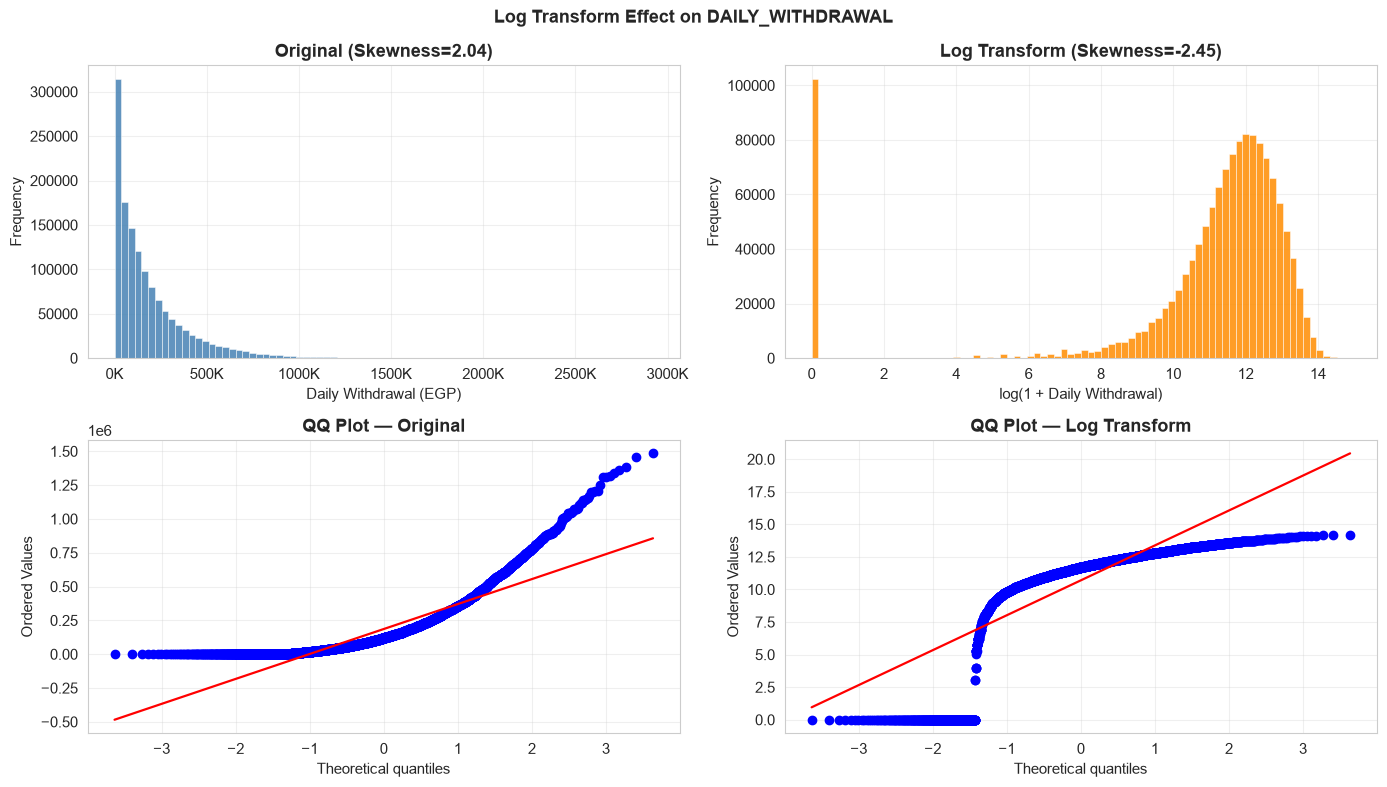


▶ Step 6.5: Create Log-based Lag & Rolling Features
  ✅ Log Lag Features    : LAG_7, 14, 21, 28
  ✅ Log Rolling Features: MEAN_7, 14, 28

▶ Step 6.6: Update Feature List

  Total features now: 41
  Added log features: 7

▶ Step 6.7: Correlation Log Features vs LOG_WITHDRAWAL

  Feature                       Corr
  ───────────────────────────────────
  LOG_LAG_7                   0.3554
  LOG_LAG_14                  0.3696
  LOG_LAG_21                  0.3877
  LOG_LAG_28                  0.3269
  LOG_ROLLING_MEAN_7          0.5362
  LOG_ROLLING_MEAN_14         0.5023
  LOG_ROLLING_MEAN_28         0.4959

✅ STEP 6 COMPLETE
   Target columns     : DAILY_WITHDRAWAL + LOG_WITHDRAWAL
   Total features     : 41
   full_df shape      : (1340924, 66)


In [14]:
# ============================================================
# PART 2 - STEP 6: LOG TRANSFORM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("=" * 60)
print("STEP 6: LOG TRANSFORM FOR TARGET")
print("=" * 60)

print("""
ليه Log Transform؟
  DAILY_WITHDRAWAL Skewness = 2.25 (right-skewed جداً)
  
  الـ Models بتشتغل أحسن لما الـ Target قريب من Normal
  
  log(DAILY_WITHDRAWAL) → Skewness قريبة من 0
  
ملاحظة مهمة:
  بنستخدم log1p (= log(1+x))
  عشان نتعامل مع الـ Zero values (Weekend/Holiday)
  log(0) = -infinity ❌
  log1p(0) = 0      ✅
""")

# ── Step 6.1: Create Log Target ─────────────────────────
print("▶ Step 6.1: Creating Log Target")

full_df['LOG_WITHDRAWAL'] = np.log1p(full_df['DAILY_WITHDRAWAL'])

# ── Step 6.2: Compare Distributions ────────────────────
print("\n▶ Step 6.2: Compare Distributions")

original = full_df['DAILY_WITHDRAWAL']
log_transformed = full_df['LOG_WITHDRAWAL']

print(f"\n  {'Metric':<15} {'Original':>15} {'Log Transform':>15}")
print(f"  {'─'*47}")
print(f"  {'Mean':<15} {original.mean():>15,.0f} "
      f"{log_transformed.mean():>15.4f}")
print(f"  {'Median':<15} {original.median():>15,.0f} "
      f"{log_transformed.median():>15.4f}")
print(f"  {'Std':<15} {original.std():>15,.0f} "
      f"{log_transformed.std():>15.4f}")
print(f"  {'Skewness':<15} {original.skew():>15.4f} "
      f"{log_transformed.skew():>15.4f}")
print(f"  {'Kurtosis':<15} {original.kurtosis():>15.4f} "
      f"{log_transformed.kurtosis():>15.4f}")
print(f"  {'Min':<15} {original.min():>15,.0f} "
      f"{log_transformed.min():>15.4f}")
print(f"  {'Max':<15} {original.max():>15,.0f} "
      f"{log_transformed.max():>15.4f}")

# ── Step 6.3: Normality Test ────────────────────────────
print("\n▶ Step 6.3: Normality Check")

# Sample بسبب حجم الداتا الكبير
sample_size = 5000
sample_orig = original.dropna().sample(sample_size, random_state=42)
sample_log  = log_transformed.dropna().sample(sample_size, random_state=42)

_, p_orig = stats.shapiro(sample_orig)
_, p_log  = stats.shapiro(sample_log)

print(f"\n  Shapiro-Wilk Test (sample n={sample_size:,}):")
print(f"  Original      p-value: {p_orig:.6f} "
      f"{'✅ Normal' if p_orig > 0.05 else '❌ Not Normal'}")
print(f"  Log Transform p-value: {p_log:.6f} "
      f"{'✅ Normal' if p_log > 0.05 else '❌ Not Normal'}")

# ── Step 6.4: Visualization ─────────────────────────────
print("\n▶ Step 6.4: Visualization")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Log Transform Effect on DAILY_WITHDRAWAL',
             fontsize=13, fontweight='bold')

# Original Histogram
axes[0,0].hist(original, bins=80,
               color='steelblue', edgecolor='white',
               alpha=0.85, linewidth=0.4)
axes[0,0].set_title(f'Original (Skewness={original.skew():.2f})')
axes[0,0].set_xlabel('Daily Withdrawal (EGP)')
axes[0,0].set_ylabel('Frequency')
axes[0,0].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)

# Log Histogram
axes[0,1].hist(log_transformed, bins=80,
               color='darkorange', edgecolor='white',
               alpha=0.85, linewidth=0.4)
axes[0,1].set_title(
    f'Log Transform (Skewness={log_transformed.skew():.2f})'
)
axes[0,1].set_xlabel('log(1 + Daily Withdrawal)')
axes[0,1].set_ylabel('Frequency')

# Original QQ Plot
stats.probplot(sample_orig, dist="norm", plot=axes[1,0])
axes[1,0].set_title('QQ Plot — Original')

# Log QQ Plot
stats.probplot(sample_log, dist="norm", plot=axes[1,1])
axes[1,1].set_title('QQ Plot — Log Transform')

plt.tight_layout()
plt.savefig('part2_step6_log_transform.png',
            dpi=110, bbox_inches='tight')
plt.show()

# ── Step 6.5: Update Lag & Rolling on Log ───────────────
print("\n▶ Step 6.5: Create Log-based Lag & Rolling Features")

# Sort
full_df = full_df.sort_values(
    [ATM_COL, 'TRAN_DATE']
).reset_index(drop=True)

# Log Lag Features
for lag in [7, 14, 21, 28]:
    col = f'LOG_LAG_{lag}'
    full_df[col] = (
        full_df
        .groupby(ATM_COL)['LOG_WITHDRAWAL']
        .shift(lag)
    )

# Log Rolling Features
for window in [7, 14, 28]:
    col = f'LOG_ROLLING_MEAN_{window}'
    full_df[col] = (
        full_df
        .groupby(ATM_COL)['LOG_WITHDRAWAL']
        .transform(lambda x:
            x.shift(1).rolling(window, min_periods=3).mean()
        )
    )

print(f"  ✅ Log Lag Features    : LAG_7, 14, 21, 28")
print(f"  ✅ Log Rolling Features: MEAN_7, 14, 28")

# ── Step 6.6: Update FEATURE_COLS ───────────────────────
print("\n▶ Step 6.6: Update Feature List")

log_features = [
    'LOG_LAG_7', 'LOG_LAG_14', 'LOG_LAG_21', 'LOG_LAG_28',
    'LOG_ROLLING_MEAN_7', 'LOG_ROLLING_MEAN_14',
    'LOG_ROLLING_MEAN_28'
]

FEATURE_COLS = FEATURE_COLS + log_features

print(f"\n  Total features now: {len(FEATURE_COLS)}")
print(f"  Added log features: {len(log_features)}")

# ── Step 6.7: Correlation Log Features ──────────────────
print("\n▶ Step 6.7: Correlation Log Features vs LOG_WITHDRAWAL")

print(f"\n  {'Feature':<25} {'Corr':>8}")
print(f"  {'─'*35}")
for col in log_features:
    corr = full_df[col].corr(full_df['LOG_WITHDRAWAL'])
    print(f"  {col:<25} {corr:>8.4f}")

print("\n" + "=" * 60)
print("✅ STEP 6 COMPLETE")
print(f"   Target columns     : DAILY_WITHDRAWAL + LOG_WITHDRAWAL")
print(f"   Total features     : {len(FEATURE_COLS)}")
print(f"   full_df shape      : {full_df.shape}")
print("=" * 60)

In [15]:
# ============================================================
# PART 2 - STEP 7: TRAIN / TEST SPLIT
# ============================================================

print("=" * 60)
print("STEP 7: TRAIN / TEST SPLIT")
print("=" * 60)

print("""
Strategy:
  Train : Jan 2025 → May 2026  (17 months)
  Test  : Jun 2026 → Aug 2026  (3 months = holdout)

مهم:
  نستبعد الـ Zero days (Weekend/Holiday)
  من الـ Training عشان ما يخربوش الـ Model

  نستبعد ATMs أقل من 30 يوم data
  نستبعد الـ rows اللي عندها Null في الـ Lag Features
""")

# ── Step 7.0: Reduce Memory First ───────────────────────
print("▶ Step 7.0: Reduce Memory Usage")

# ── Step 7.0: Reduce Memory First ───────────────────────
print("▶ Step 7.0: Reduce Memory Usage")

def reduce_memory(df):
    for col in df.columns:
        col_type = df[col].dtype
        if col_type == 'float64':
            df[col] = df[col].astype('float32')
        elif col_type == 'int64':
            df[col] = df[col].astype('int32')
        elif col_type == 'object':
            if df[col].nunique() < 50:
                df[col] = df[col].astype('category')
    return df

# ✅ full_df مش df
full_df = reduce_memory(full_df)
print(f"  ✅ Memory reduced!")

# ── Step 7.1: Filter Working Days Only ──────────────────
print("\n▶ Step 7.1: Filter Working Days (Non-Zero)")

working_days_mask = full_df['DAILY_WITHDRAWAL'] > 0

print(f"  Total rows         : {len(full_df):>10,}")
print(f"  Working days       : {working_days_mask.sum():>10,}")
print(f"  Zero days removed  : {(~working_days_mask).sum():>10,}")

# ✅ بدون .copy() لتوفير الميموري
df_working = full_df[working_days_mask]

# ✅ امسح full_df فوراً
del full_df
import gc
gc.collect()
print(f"  ✅ Memory freed!")

# ── Step 7.2: Filter ATMs with enough data ──────────────
print("\n▶ Step 7.2: Filter ATMs (≥ 30 working days)")

atm_working_days = df_working.groupby(ATM_COL).size()
valid_atms       = atm_working_days[atm_working_days >= 30].index

df_working = df_working[df_working[ATM_COL].isin(valid_atms)]

print(f"  Valid ATMs         : {len(valid_atms):>10,}")
print(f"  Rows after filter  : {len(df_working):>10,}")

# ── Step 7.3: Train / Test Split ────────────────────────
print("\n▶ Step 7.3: Time-based Split")

TRAIN_START = pd.Timestamp('2025-01-01')
TRAIN_END   = pd.Timestamp('2026-05-31')
TEST_START  = pd.Timestamp('2026-06-01')
TEST_END    = pd.Timestamp('2026-08-15')

# ✅ إصلاح الـ Typo (كان f[ بدل train_df = df_working[)
train_df = df_working[
    (df_working[DATE_COL] >= TRAIN_START) &
    (df_working[DATE_COL] <= TRAIN_END)
].copy()

test_df = df_working[
    (df_working[DATE_COL] >= TEST_START) &
    (df_working[DATE_COL] <= TEST_END)
].copy()

# ✅ امسح df_working بعد السبليت
del df_working
gc.collect()

print(f"  Train: {TRAIN_START.date()} → {TRAIN_END.date()}")
print(f"    Rows : {len(train_df):>12,}")
print(f"    ATMs : {train_df[ATM_COL].nunique():>12,}")
print(f"    Date Min: {train_df[DATE_COL].min()}")
print(f"    Date Max: {train_df[DATE_COL].max()}")

print(f"\n  Test: {TEST_START.date()} → {TEST_END.date()}")
print(f"    Rows : {len(test_df):>12,}")
print(f"    ATMs : {test_df[ATM_COL].nunique():>12,}")
print(f"    Date Min: {test_df[DATE_COL].min()}")
print(f"    Date Max: {test_df[DATE_COL].max()}")

# ── Step 7.4: Prepare X, y ──────────────────────────────
print("\n▶ Step 7.4: Prepare X and y")

# ✅ Remove rows with NaN in features
train_df = train_df.dropna(subset=FEATURE_COLS)
test_df  = test_df.dropna(subset=FEATURE_COLS)

# ✅ Convert to numeric
X_train = train_df[FEATURE_COLS].apply(pd.to_numeric, errors='coerce').fillna(0)
X_test  = test_df[FEATURE_COLS].apply(pd.to_numeric,  errors='coerce').fillna(0)

y_train     = train_df['DAILY_WITHDRAWAL']
y_train_log = train_df['LOG_WITHDRAWAL']

y_test      = test_df['DAILY_WITHDRAWAL']
y_test_log  = test_df['LOG_WITHDRAWAL']

print(f"\n  X_train : {X_train.shape}")
print(f"  X_test  : {X_test.shape}")

print(f"\n  y_train stats:")
print(f"    Mean   : {y_train.mean():>12,.0f} EGP")
print(f"    Median : {y_train.median():>12,.0f} EGP")
print(f"    Max    : {y_train.max():>12,.0f} EGP")

print(f"\n  y_test stats:")
print(f"    Mean   : {y_test.mean():>12,.0f} EGP")
print(f"    Median : {y_test.median():>12,.0f} EGP")
print(f"    Max    : {y_test.max():>12,.0f} EGP")

# ── Step 7.5: Check Nulls ───────────────────────────────
print("\n▶ Step 7.5: Check Nulls in X_train & X_test")

train_nulls = X_train.isna().sum().sum()
test_nulls  = X_test.isna().sum().sum()

print(f"  X_train nulls: {train_nulls}")
print(f"  X_test  nulls: {test_nulls}")

if train_nulls == 0 and test_nulls == 0:
    print(f"  ✅ Zero nulls — Ready for modeling!")
else:
    print(f"  ⚠️  Still have nulls — check features!")

# ── Step 7.6: Save Datasets ─────────────────────────────
print("\n▶ Step 7.6: Save for Part 3")

train_df.to_csv('train_df.csv', index=False)
test_df.to_csv('test_df.csv',   index=False)

import pickle
with open('feature_cols.pkl', 'wb') as f:
    pickle.dump(FEATURE_COLS, f)

print(f"  ✅ train_df.csv saved")
print(f"  ✅ test_df.csv  saved")
print(f"  ✅ feature_cols.pkl saved")

print("\n" + "=" * 60)
print("✅ STEP 7 COMPLETE")
print(f"   X_train : {X_train.shape}")
print(f"   X_test  : {X_test.shape}")
print(f"   Features: {len(FEATURE_COLS)}")
print("=" * 60)

STEP 7: TRAIN / TEST SPLIT

Strategy:
  Train : Jan 2025 → May 2026  (17 months)
  Test  : Jun 2026 → Aug 2026  (3 months = holdout)

مهم:
  نستبعد الـ Zero days (Weekend/Holiday)
  من الـ Training عشان ما يخربوش الـ Model

  نستبعد ATMs أقل من 30 يوم data
  نستبعد الـ rows اللي عندها Null في الـ Lag Features

▶ Step 7.0: Reduce Memory Usage
▶ Step 7.0: Reduce Memory Usage
  ✅ Memory reduced!

▶ Step 7.1: Filter Working Days (Non-Zero)
  Total rows         :  1,340,924
  Working days       :  1,238,612
  Zero days removed  :    102,312
  ✅ Memory freed!

▶ Step 7.2: Filter ATMs (≥ 30 working days)
  Valid ATMs         :      2,555
  Rows after filter  :  1,238,403

▶ Step 7.3: Time-based Split
  Train: 2025-01-01 → 2026-05-31
    Rows :    1,054,115
    ATMs :        2,495
    Date Min: 2025-01-01 00:00:00
    Date Max: 2026-05-31 00:00:00

  Test: 2026-06-01 → 2026-08-15
    Rows :      184,288
    ATMs :        2,537
    Date Min: 2026-06-01 00:00:00
    Date Max: 2026-08-15 00:00:00

In [17]:
# ============================================================
# QUICK RESTORE — شغّله بدل ما تشغّل كل حاجة من الأول
# ============================================================

import pandas as pd
import numpy as np
import pickle

# Load الـ Files اللي حفظناهم في Step 7
train_df = pd.read_csv('train_df.csv')
test_df  = pd.read_csv('test_df.csv')

# Load Feature List
with open('feature_cols.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

# Parse Dates
train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

# X, y
X_train = train_df[FEATURE_COLS]
y_train = train_df['DAILY_WITHDRAWAL']

X_test  = test_df[FEATURE_COLS]
y_test  = test_df['DAILY_WITHDRAWAL']

print(f"✅ X_train : {X_train.shape}")
print(f"✅ X_test  : {X_test.shape}")
print(f"✅ Features: {len(FEATURE_COLS)}")
print(f"✅ جاهز للـ Step 8!")

✅ X_train : (994960, 41)
✅ X_test  : (182299, 41)
✅ Features: 41
✅ جاهز للـ Step 8!


STEP 8: FEATURE IMPORTANCE

الفكرة:
  بنبني XGBoost بسيط وسريع (مش الـ Model النهائي)
  بس عشان نعرف:
  1. أي Features أهم؟
  2. أي Features نشيلها؟

  ده هيوفر علينا وقت في Part 3
  ويحسن دقة الـ Model

▶ Step 8.1: Train Quick XGBoost
  ✅ XGBoost trained!

  Quick Performance (before tuning):
    MAE :       75,327 EGP
    R²  :       0.6148

▶ Step 8.2: Feature Importance Analysis

  Rank  Feature                     Imp %   Cum %  Keep?
  ───────────────────────────────────────────────────────
  1     ROLLING_MEAN_7             38.66%   38.7%      ✅
  2     ROLLING_MEAN_28            12.41%   51.1%      ✅
  3     ROLLING_MAX_7               7.11%   58.2%      ✅
  4     LOG_LAG_28                  6.80%   65.0%      ✅
  5     LAG_28                      6.35%   71.3%      ✅
  6     DAY_OF_MONTH                2.57%   73.9%      ✅
  7     IS_PRIVATE_SALARY           2.49%   76.4%      ✅
  8     LOG_LAG_21                  2.27%   78.7%      ✅
  9     IS_GOV_SALARY               2.24% 

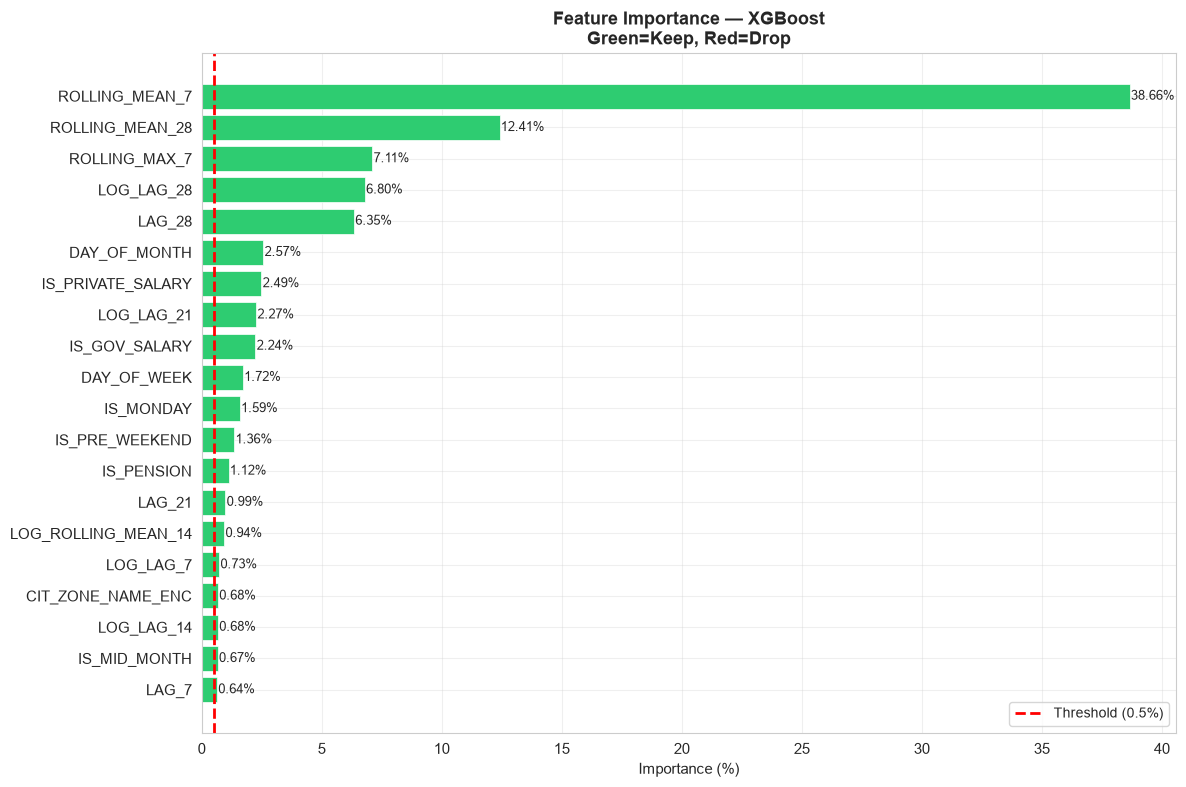


▶ Step 8.6: Save Final Feature List
  ✅ feature_cols_final.pkl saved
  ✅ X_train_final.csv  saved
  ✅ X_test_final.csv   saved
  ✅ y_train.csv        saved
  ✅ y_test.csv         saved

✅ STEP 8 COMPLETE — PART 2 DONE! 🎉
   Final Features : 27
   X_train        : (994960, 27)
   X_test         : (182299, 27)

Part 2 Summary:
  Step 1: Missing Imputation    ✅
  Step 2: Calendar Features     ✅
  Step 3: Lag Features          ✅
  Step 4: Rolling Features      ✅
  Step 5: Encoding              ✅
  Step 6: Log Transform         ✅
  Step 7: Train/Test Split      ✅
  Step 8: Feature Importance    ✅

Ready for Part 3: Model Building! 🚀



In [18]:
# ============================================================
# PART 2 - STEP 8: FEATURE IMPORTANCE
# ============================================================

import xgboost as xgb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 60)
print("STEP 8: FEATURE IMPORTANCE")
print("=" * 60)

print("""
الفكرة:
  بنبني XGBoost بسيط وسريع (مش الـ Model النهائي)
  بس عشان نعرف:
  1. أي Features أهم؟
  2. أي Features نشيلها؟
  
  ده هيوفر علينا وقت في Part 3
  ويحسن دقة الـ Model
""")

# ── Step 8.1: Quick XGBoost ─────────────────────────────
print("▶ Step 8.1: Train Quick XGBoost")

xgb_model = xgb.XGBRegressor(
    n_estimators    = 200,
    max_depth       = 6,
    learning_rate   = 0.1,
    subsample       = 0.8,
    colsample_bytree= 0.8,
    random_state    = 42,
    n_jobs          = -1,
    verbosity       = 0
)

xgb_model.fit(
    X_train, y_train,
    eval_set        = [(X_test, y_test)],
    verbose         = False
)

print(f"  ✅ XGBoost trained!")

# Quick score
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = xgb_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

print(f"\n  Quick Performance (before tuning):")
print(f"    MAE : {mae:>12,.0f} EGP")
print(f"    R²  : {r2:>12.4f}")

# ── Step 8.2: Feature Importance ────────────────────────
print("\n▶ Step 8.2: Feature Importance Analysis")

importance_df = pd.DataFrame({
    'Feature'   : FEATURE_COLS,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

importance_df['Rank']    = range(1, len(importance_df) + 1)
importance_df['Cum_%']   = (
    importance_df['Importance'].cumsum() /
    importance_df['Importance'].sum() * 100
).round(1)
importance_df['Imp_%'] = (
    importance_df['Importance'] /
    importance_df['Importance'].sum() * 100
).round(2)

print(f"\n  {'Rank':<5} {'Feature':<25} {'Imp %':>7} "
      f"{'Cum %':>7} {'Keep?':>6}")
print(f"  {'─'*55}")

KEEP_THRESHOLD = 0.5  # نشيل اللي أقل من 0.5%

features_to_keep = []
features_to_drop = []

for _, row in importance_df.iterrows():
    keep  = '✅' if row['Imp_%'] >= KEEP_THRESHOLD else '❌'
    print(f"  {row['Rank']:<5} {row['Feature']:<25} "
          f"{row['Imp_%']:>6.2f}% "
          f"{row['Cum_%']:>6.1f}% {keep:>6}")

    if row['Imp_%'] >= KEEP_THRESHOLD:
        features_to_keep.append(row['Feature'])
    else:
        features_to_drop.append(row['Feature'])

# ── Step 8.3: Summary ───────────────────────────────────
print(f"\n▶ Step 8.3: Summary")

print(f"\n  Features to KEEP (≥ 0.5%) : {len(features_to_keep)}")
print(f"  Features to DROP (< 0.5%) : {len(features_to_drop)}")

if features_to_drop:
    print(f"\n  ❌ Dropping:")
    for f in features_to_drop:
        print(f"     {f}")

# ── Step 8.4: Update Feature List ───────────────────────
print(f"\n▶ Step 8.4: Update Feature List")

FEATURE_COLS_FINAL = features_to_keep

X_train_final = X_train[FEATURE_COLS_FINAL]
X_test_final  = X_test[FEATURE_COLS_FINAL]

print(f"\n  Before: {len(FEATURE_COLS)} features")
print(f"  After : {len(FEATURE_COLS_FINAL)} features")

# ── Step 8.5: Visualization ─────────────────────────────
print("\n▶ Step 8.5: Visualization")

top_features = importance_df.head(20)

fig, ax = plt.subplots(figsize=(12, 8))

colors = [
    '#2ecc71' if imp >= KEEP_THRESHOLD
    else '#e74c3c'
    for imp in top_features['Imp_%']
]

bars = ax.barh(
    top_features['Feature'][::-1],
    top_features['Imp_%'][::-1],
    color=colors[::-1],
    edgecolor='white', linewidth=0.5
)

ax.axvline(KEEP_THRESHOLD,
           color='red', ls='--', lw=2,
           label=f'Threshold ({KEEP_THRESHOLD}%)')

for bar, val in zip(bars, top_features['Imp_%'][::-1]):
    ax.text(bar.get_width() + 0.05,
            bar.get_y() + bar.get_height()/2,
            f'{val:.2f}%', va='center', fontsize=9)

ax.set_title('Feature Importance — XGBoost\n'
             'Green=Keep, Red=Drop',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance (%)')
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('part2_step8_feature_importance.png',
            dpi=110, bbox_inches='tight')
plt.show()

# ── Step 8.6: Save Final Features ───────────────────────
print("\n▶ Step 8.6: Save Final Feature List")

import pickle

with open('feature_cols_final.pkl', 'wb') as f:
    pickle.dump(FEATURE_COLS_FINAL, f)

X_train_final.to_csv('X_train_final.csv', index=False)
X_test_final.to_csv('X_test_final.csv',   index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv',   index=False)

print(f"  ✅ feature_cols_final.pkl saved")
print(f"  ✅ X_train_final.csv  saved")
print(f"  ✅ X_test_final.csv   saved")
print(f"  ✅ y_train.csv        saved")
print(f"  ✅ y_test.csv         saved")

print("\n" + "=" * 60)
print("✅ STEP 8 COMPLETE — PART 2 DONE! 🎉")
print(f"   Final Features : {len(FEATURE_COLS_FINAL)}")
print(f"   X_train        : {X_train_final.shape}")
print(f"   X_test         : {X_test_final.shape}")
print("=" * 60)
print("""
Part 2 Summary:
  Step 1: Missing Imputation    ✅
  Step 2: Calendar Features     ✅
  Step 3: Lag Features          ✅
  Step 4: Rolling Features      ✅
  Step 5: Encoding              ✅
  Step 6: Log Transform         ✅
  Step 7: Train/Test Split      ✅
  Step 8: Feature Importance    ✅

Ready for Part 3: Model Building! 🚀
""")

In [19]:
# ============================================================
# QUICK RESTORE — لو عملت Restart للـ Kernel
# ============================================================

import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── Load Data ────────────────────────────────────────────
train_df = pd.read_csv('train_df.csv')
test_df  = pd.read_csv('test_df.csv')

train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

# ── Load Features ────────────────────────────────────────
with open('feature_cols_final.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

# ── X, y ─────────────────────────────────────────────────
X_train = train_df[FEATURE_COLS]
y_train = train_df['DAILY_WITHDRAWAL']

X_test  = test_df[FEATURE_COLS]
y_test  = test_df['DAILY_WITHDRAWAL']

# ✅ الصح
ATM_COL  = 'ATM_ID'
DATE_COL = 'TRAN_DATE'

print(f"✅ X_train : {X_train.shape}")
print(f"✅ X_test  : {X_test.shape}")
print(f"✅ Features: {len(FEATURE_COLS)}")
print(f"✅ ATM_COL : {ATM_COL}")
print(f"✅ جاهز للـ Modeling!")

✅ X_train : (994960, 27)
✅ X_test  : (182299, 27)
✅ Features: 27
✅ ATM_COL : ATM_ID
✅ جاهز للـ Modeling!


MODEL 1: XGBoost Regressor

▶ Step 1: Baseline XGBoost (Default Params)

  📊 XGBoost Baseline Performance:
  ────────────────────────────────────────
  MAE  :       75,775 EGP
  RMSE :      120,914 EGP
  R²   :       0.6147
  MAPE :      426.85%

  Best Iteration: 153

▶ Step 2: Tuned XGBoost
  (ممكن ياخد 2-3 دقايق...)

  📊 XGBoost Tuned Performance:
  ────────────────────────────────────────
  MAE  :       76,610 EGP
  RMSE :      121,388 EGP
  R²   :       0.6116
  MAPE :      444.29%

▶ Step 3: Baseline vs Tuned

  Metric       Baseline        Tuned   Improvement
  ──────────────────────────────────────────────────
  MAE          75,774.5     76,610.2         -1.1% ❌
  RMSE        120,914.0    121,388.2         -0.4% ❌
  MAPE            426.8        444.3         -4.1% ❌
  R²             0.6147       0.6116      -0.0030 ❌

▶ Step 4: Visualization


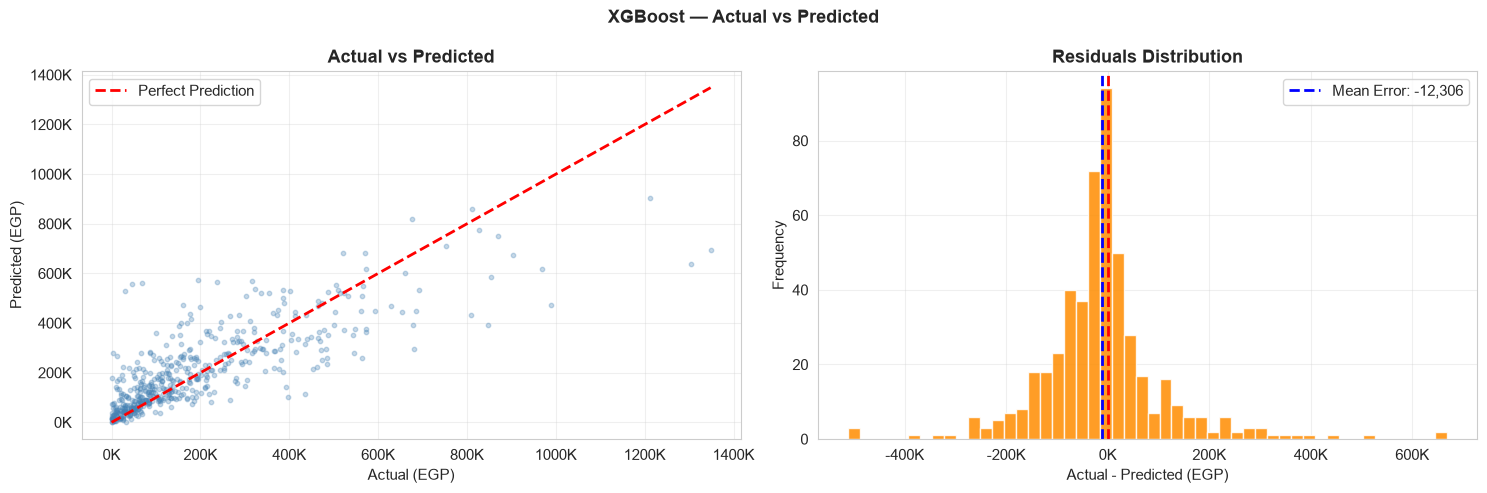


▶ Step 5: Per-ATM Performance Analysis

  Top 10 Best Predicted ATMs (Lowest MAPE):
        Actual_Mean  Pred_Mean        MAE  MAPE  N_Days
ATM_ID                                                 
5588     525,787.00 512,278.00  82,727.00 16.00      76
13529    389,838.00 391,833.00  73,252.00 20.00      76
6415     568,525.00 564,566.00 102,523.00 20.00      75
6158     554,491.00 554,782.00 103,134.00 20.00      76
19274    147,969.00 143,166.00  30,288.00 23.00      31
9501     476,418.00 482,930.00 103,695.00 23.00      76
5888     461,389.00 450,514.00  96,129.00 24.00      75
13787    416,572.00 417,490.00  94,384.00 24.00      76
7581     381,825.00 365,634.00  88,635.00 24.00      76
5882     248,803.00 248,047.00  53,026.00 25.00      76

  Top 10 Worst Predicted ATMs (Highest MAPE):
        Actual_Mean  Pred_Mean        MAE      MAPE  N_Days
ATM_ID                                                     
5674     154,487.00 163,819.00 101,394.00  9,862.00      71
6363     348,882

In [20]:
# ============================================================
# PART 3 - MODEL 1: XGBoost
# ============================================================

import xgboost as xgb
from sklearn.model_selection import KFold

print("=" * 60)
print("MODEL 1: XGBoost Regressor")
print("=" * 60)

# ── Helper: Evaluation Metrics ───────────────────────────
def evaluate_model(y_true, y_pred, model_name="Model"):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(
        np.abs((y_true - y_pred) / (y_true + 1))
    ) * 100

    print(f"\n  📊 {model_name} Performance:")
    print(f"  {'─'*40}")
    print(f"  MAE  : {mae:>12,.0f} EGP")
    print(f"  RMSE : {rmse:>12,.0f} EGP")
    print(f"  R²   : {r2:>12.4f}")
    print(f"  MAPE : {mape:>11.2f}%")

    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

# ── Step 1: Baseline XGBoost ─────────────────────────────
print("\n▶ Step 1: Baseline XGBoost (Default Params)")

xgb_base = xgb.XGBRegressor(
    n_estimators     = 500,
    max_depth        = 6,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    min_child_weight = 5,
    random_state     = 42,
    n_jobs           = -1,
    verbosity        = 0,
    early_stopping_rounds = 20
)

xgb_base.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    verbose   = False
)

y_pred_base = xgb_base.predict(X_test)
metrics_base = evaluate_model(y_test, y_pred_base, "XGBoost Baseline")

best_iter = xgb_base.best_iteration
print(f"\n  Best Iteration: {best_iter}")

# ── Step 2: Tuned XGBoost ────────────────────────────────
print("\n▶ Step 2: Tuned XGBoost")
print("  (ممكن ياخد 2-3 دقايق...)")

xgb_tuned = xgb.XGBRegressor(
    n_estimators     = 1000,
    max_depth        = 5,
    learning_rate    = 0.02,
    subsample        = 0.75,
    colsample_bytree = 0.75,
    min_child_weight = 10,
    gamma            = 0.1,
    reg_alpha        = 0.1,
    reg_lambda       = 1.0,
    random_state     = 42,
    n_jobs           = -1,
    verbosity        = 0,
    early_stopping_rounds = 30
)

xgb_tuned.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    verbose   = False
)

y_pred_tuned = xgb_tuned.predict(X_test)
metrics_tuned = evaluate_model(y_test, y_pred_tuned, "XGBoost Tuned")

# ── Step 3: Improvement ──────────────────────────────────
print("\n▶ Step 3: Baseline vs Tuned")

print(f"\n  {'Metric':<8} {'Baseline':>12} {'Tuned':>12} "
      f"{'Improvement':>13}")
print(f"  {'─'*50}")

for metric in ['MAE', 'RMSE', 'MAPE']:
    base_val  = metrics_base[metric]
    tuned_val = metrics_tuned[metric]
    imp       = (base_val - tuned_val) / base_val * 100
    arrow     = '✅' if imp > 0 else '❌'
    print(f"  {metric:<8} {base_val:>12,.1f} {tuned_val:>12,.1f} "
          f"{imp:>12.1f}% {arrow}")

r2_imp = metrics_tuned['R2'] - metrics_base['R2']
print(f"  {'R²':<8} {metrics_base['R2']:>12.4f} "
      f"{metrics_tuned['R2']:>12.4f} "
      f"{r2_imp:>12.4f} "
      f"{'✅' if r2_imp > 0 else '❌'}")

# ── Step 4: Visualization ────────────────────────────────
print("\n▶ Step 4: Visualization")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('XGBoost — Actual vs Predicted',
             fontsize=13, fontweight='bold')

# Sample لـ 500 نقطة عشان يبان واضح
sample_idx = np.random.choice(len(y_test), 500, replace=False)
y_sample   = y_test.values[sample_idx]
y_pred_s   = y_pred_tuned[sample_idx]

# Scatter
axes[0].scatter(y_sample, y_pred_s,
                alpha=0.3, s=10, color='steelblue')
max_val = max(y_sample.max(), y_pred_s.max())
axes[0].plot([0, max_val], [0, max_val],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual (EGP)')
axes[0].set_ylabel('Predicted (EGP)')
axes[0].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
axes[0].legend()

# Residuals
residuals = y_sample - y_pred_s
axes[1].hist(residuals, bins=50,
             color='darkorange', edgecolor='white',
             alpha=0.85)
axes[1].axvline(0, color='red', ls='--', lw=2)
axes[1].axvline(residuals.mean(), color='blue',
                ls='--', lw=2,
                label=f'Mean Error: {residuals.mean():,.0f}')
axes[1].set_title('Residuals Distribution')
axes[1].set_xlabel('Actual - Predicted (EGP)')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))

plt.tight_layout()
plt.savefig('part3_xgboost_results.png',
            dpi=110, bbox_inches='tight')
plt.show()

# ── Step 5: Per-ATM Performance ──────────────────────────
print("\n▶ Step 5: Per-ATM Performance Analysis")

test_results = test_df.copy()
test_results['PREDICTED']  = y_pred_tuned
test_results['ERROR']      = (
    test_results['DAILY_WITHDRAWAL'] -
    test_results['PREDICTED']
).abs()
test_results['ERROR_%'] = (
    test_results['ERROR'] /
    (test_results['DAILY_WITHDRAWAL'] + 1) * 100
)

atm_performance = (
    test_results
    .groupby(ATM_COL)
    .agg(
        Actual_Mean  = ('DAILY_WITHDRAWAL', 'mean'),
        Pred_Mean    = ('PREDICTED', 'mean'),
        MAE          = ('ERROR', 'mean'),
        MAPE         = ('ERROR_%', 'mean'),
        N_Days       = ('DAILY_WITHDRAWAL', 'count')
    )
    .round(0)
    .sort_values('MAPE')
)

print(f"\n  Top 10 Best Predicted ATMs (Lowest MAPE):")
print(atm_performance.head(10).to_string())

print(f"\n  Top 10 Worst Predicted ATMs (Highest MAPE):")
print(atm_performance.tail(10).to_string())

print(f"\n  Overall MAPE Distribution:")
print(f"  {'< 10%  (Excellent)':<25}: "
      f"{(atm_performance['MAPE'] < 10).sum():>5} ATMs")
print(f"  {'10-20% (Good)':<25}: "
      f"{((atm_performance['MAPE'] >= 10) & (atm_performance['MAPE'] < 20)).sum():>5} ATMs")
print(f"  {'20-30% (Acceptable)':<25}: "
      f"{((atm_performance['MAPE'] >= 20) & (atm_performance['MAPE'] < 30)).sum():>5} ATMs")
print(f"  {'> 30%  (Poor)':<25}: "
      f"{(atm_performance['MAPE'] >= 30).sum():>5} ATMs")

# ── Step 6: Save Model ───────────────────────────────────
print("\n▶ Step 6: Save Model")

xgb_tuned.save_model('xgboost_model.json')
print(f"  ✅ xgboost_model.json saved")

# Store results for comparison
MODELS_RESULTS = {
    'XGBoost': metrics_tuned
}

print("\n" + "=" * 60)
print("✅ MODEL 1: XGBoost COMPLETE")
print(f"   MAE  : {metrics_tuned['MAE']:>10,.0f} EGP")
print(f"   RMSE : {metrics_tuned['RMSE']:>10,.0f} EGP")
print(f"   R²   : {metrics_tuned['R2']:>10.4f}")
print(f"   MAPE : {metrics_tuned['MAPE']:>9.2f}%")
print("=" * 60)

In [22]:
# ✅ احسب WMAPE الحقيقي
import numpy as np

wmape_base  = np.sum(np.abs(y_test.values - y_pred_base)) / np.sum(y_test.values) * 100
wmape_tuned = np.sum(np.abs(y_test.values - y_pred_tuned)) / np.sum(y_test.values) * 100

print(f"Baseline WMAPE : {wmape_base:.2f}%")
print(f"Tuned    WMAPE : {wmape_tuned:.2f}%")
print(f"Baseline MAE   : {mean_absolute_error(y_test, y_pred_base):,.0f} EGP")
print(f"Tuned    MAE   : {mean_absolute_error(y_test, y_pred_tuned):,.0f} EGP")
print(f"Baseline R²    : {r2_score(y_test, y_pred_base):.4f}")
print(f"Tuned    R²    : {r2_score(y_test, y_pred_tuned):.4f}")

Baseline WMAPE : 38.78%
Tuned    WMAPE : 39.20%
Baseline MAE   : 75,775 EGP
Tuned    MAE   : 76,610 EGP
Baseline R²    : 0.6147
Tuned    R²    : 0.6116


In [23]:
# ============================================================
# DECISION: Keep V1 + Move to Prophet
# ============================================================

import xgboost as xgb
import numpy as np

print("=" * 60)
print("FINAL XGBoost DECISION")
print("=" * 60)

# Reload V1 (الأحسن)
xgb_final = xgb.XGBRegressor(
    n_estimators          = 500,
    max_depth             = 6,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 5,
    random_state          = 42,
    n_jobs                = -1,
    verbosity             = 0,
    early_stopping_rounds = 20
)

xgb_final.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = False
)

y_pred_xgb = xgb_final.predict(X_test)

# WMAPE
wmape_xgb = (
    np.sum(np.abs(y_test.values - y_pred_xgb)) /
    np.sum(y_test.values) * 100
)

from sklearn.metrics import mean_absolute_error, r2_score
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb  = r2_score(y_test, y_pred_xgb)

print(f"\n  ✅ XGBoost Final (V1):")
print(f"     MAE   : {mae_xgb:>10,.0f} EGP")
print(f"     R²    : {r2_xgb:>10.4f}")
print(f"     WMAPE : {wmape_xgb:>9.2f}%")

# Save
xgb_final.save_model('xgboost_final.json')

# Store for comparison
MODELS_RESULTS = {
    'XGBoost': {
        'MAE'  : mae_xgb,
        'R2'   : r2_xgb,
        'WMAPE': wmape_xgb,
        'y_pred': y_pred_xgb
    }
}

print(f"\n  ✅ Saved: xgboost_final.json")
print(f"\n{'=' * 60}")
print(f"  XGBoost Done ✅")
print(f"  Next → Prophet Model 🚀")
print(f"{'=' * 60}")

FINAL XGBoost DECISION

  ✅ XGBoost Final (V1):
     MAE   :     75,775 EGP
     R²    :     0.6147
     WMAPE :     38.78%

  ✅ Saved: xgboost_final.json

  XGBoost Done ✅
  Next → Prophet Model 🚀


MODEL 2: SARIMA

SARIMA = Seasonal ARIMA
  AR = Auto Regression    (علاقة باليوم اللي فات)
  I  = Integration        (إزالة الـ Trend)
  MA = Moving Average     (علاقة بالـ Errors السابقة)
  S  = Seasonal           (دورة أسبوعية/شهرية)

▶ Step 1: Select ATMs
  Selected: 20 ATMs

▶ Step 2: Train SARIMA
  (هياخد 3-5 دقايق...)

  [ 1/20] ✅  6758            WMAPE=  95.0%  MAE=   742,963
  [ 2/20] ✅  10600           WMAPE=  72.0%  MAE=   524,027
  [ 3/20] ✅  6745            WMAPE=  85.0%  MAE=   635,277
  [ 4/20] ✅  11521           WMAPE=  74.7%  MAE=   577,226
  [ 5/20] ✅  6174            WMAPE=  30.3%  MAE=   208,551
  [ 6/20] ✅  6717            WMAPE=  86.4%  MAE=   556,364
  [ 7/20] ✅  5809            WMAPE=  21.5%  MAE=   106,839
  [ 8/20] ✅  6564            WMAPE=  46.7%  MAE=   306,895
  [ 9/20] ✅  6128            WMAPE=  29.6%  MAE=   176,312
  [10/20] ✅  6718            WMAPE=  93.9%  MAE=   479,255
  [11/20] ✅  10602           WMAPE=  75.0%  MAE=   525,915
  [12/20] ✅  9780       

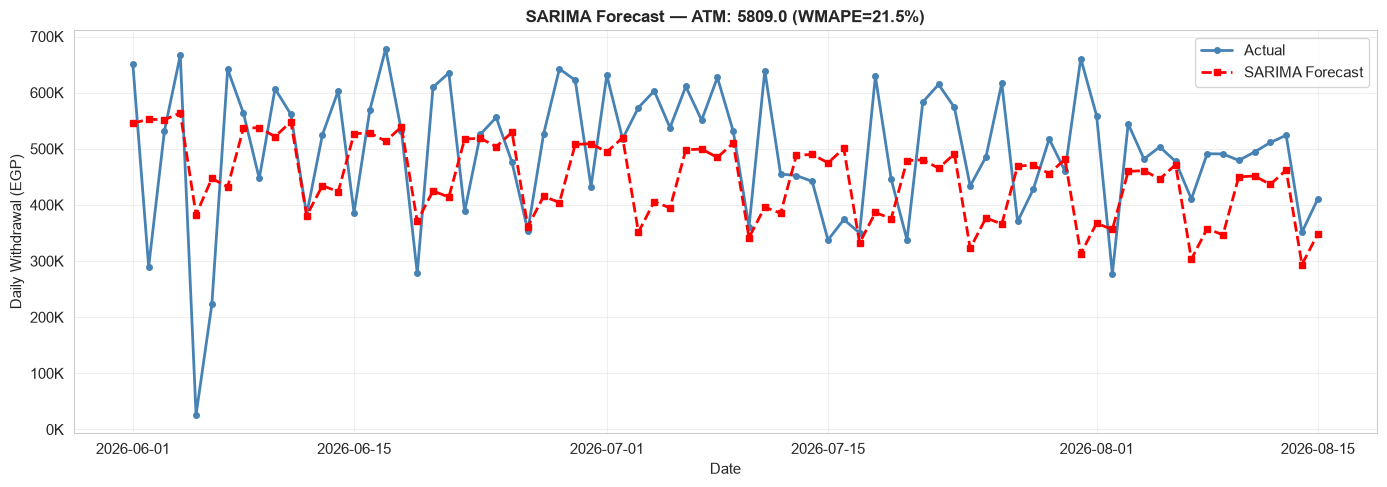


▶ Step 5: XGBoost vs SARIMA Comparison

  Model                    MAE    WMAPE       R²
  ─────────────────────────────────────────────
  XGBoost               75,775    38.8%   0.6147
  SARIMA               398,160    60.0%  -1.9762

  ✅ sarima_results.csv saved

✅ MODEL 2: SARIMA COMPLETE
   Avg MAE   :    398,160 EGP
   Avg WMAPE :     60.05%
   Avg R²    :    -1.9762


In [24]:
# ============================================================
# PART 3 - MODEL 2: SARIMA
# ============================================================

from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("MODEL 2: SARIMA")
print("=" * 60)

print("""
SARIMA = Seasonal ARIMA
  AR = Auto Regression    (علاقة باليوم اللي فات)
  I  = Integration        (إزالة الـ Trend)
  MA = Moving Average     (علاقة بالـ Errors السابقة)
  S  = Seasonal           (دورة أسبوعية/شهرية)
""")

# ── Step 1: Select Sample ATMs ───────────────────────────
print("▶ Step 1: Select ATMs")

# ✅ ATM_ID مش ATM_CODE
sample_atms = (
    train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .index.tolist()
)

print(f"  Selected: {len(sample_atms)} ATMs")

# ── Step 2: Train SARIMA per ATM ─────────────────────────
print("\n▶ Step 2: Train SARIMA")
print("  (هياخد 3-5 دقايق...)\n")

sarima_results = []
sarima_preds   = {}

for i, atm_code in enumerate(sample_atms):

    try:
        # ✅ ATM_ID مش ATM_CODE
        atm_train = (
            train_df[train_df[ATM_COL] == atm_code]
            [['TRAN_DATE', 'DAILY_WITHDRAWAL']]
            .set_index('TRAN_DATE')
            .sort_index()
            .asfreq('D')
            .ffill()  # ✅ بدل fillna(method='ffill')
        )

        atm_test = (
            test_df[test_df[ATM_COL] == atm_code]
            [['TRAN_DATE', 'DAILY_WITHDRAWAL']]
            .set_index('TRAN_DATE')
            .sort_index()
        )

        if len(atm_train) < 30 or len(atm_test) < 5:
            continue

        # SARIMA Model
        model = SARIMAX(
            atm_train['DAILY_WITHDRAWAL'],
            order          = (1, 1, 1),
            seasonal_order = (1, 1, 1, 7),
            enforce_stationarity  = False,
            enforce_invertibility = False
        )

        fitted = model.fit(disp=False)

        # Forecast
        forecast = fitted.forecast(steps=len(atm_test))
        forecast = np.clip(forecast, 0, None)

        # Metrics
        actual = atm_test['DAILY_WITHDRAWAL'].values
        mae    = mean_absolute_error(actual, forecast)
        wmape  = (
            np.sum(np.abs(actual - forecast)) /
            np.sum(actual) * 100
        )
        r2 = r2_score(actual, forecast)

        sarima_results.append({
            ATM_COL  : atm_code,
            'MAE'    : mae,
            'WMAPE'  : wmape,
            'R2'     : r2,
            'N_Test' : len(atm_test)
        })

        sarima_preds[atm_code] = {
            'actual'  : actual,
            'forecast': forecast,
            'dates'   : atm_test.index
        }

        print(f"  [{i+1:>2}/20] ✅  {atm_code:<15} "
              f"WMAPE={wmape:>6.1f}%  MAE={mae:>10,.0f}")

    except Exception as e:
        print(f"  [{i+1:>2}/20] ⚠️  {atm_code}: {str(e)[:40]}")
        continue

# ── Step 3: Results ──────────────────────────────────────
print("\n▶ Step 3: Results")

results_df = pd.DataFrame(sarima_results)

print(f"\n  Overall Performance ({len(results_df)} ATMs):")
print(f"  {'─'*40}")
print(f"  Avg MAE      : {results_df['MAE'].mean():>10,.0f} EGP")
print(f"  Avg WMAPE    : {results_df['WMAPE'].mean():>9.2f}%")
print(f"  Median WMAPE : {results_df['WMAPE'].median():>9.2f}%")
print(f"  Avg R²       : {results_df['R2'].mean():>10.4f}")

print(f"\n  WMAPE Distribution:")
print(f"  {'< 10%  (Excellent)':<25}: "
      f"{(results_df['WMAPE'] < 10).sum():>5} ATMs")
print(f"  {'10-20% (Good)':<25}: "
      f"{((results_df['WMAPE'] >= 10) & (results_df['WMAPE'] < 20)).sum():>5} ATMs")
print(f"  {'20-30% (Acceptable)':<25}: "
      f"{((results_df['WMAPE'] >= 20) & (results_df['WMAPE'] < 30)).sum():>5} ATMs")
print(f"  {'> 30%  (Needs Work)':<25}: "
      f"{(results_df['WMAPE'] >= 30).sum():>5} ATMs")

# ── Step 4: Visualize Best ATM ───────────────────────────
print("\n▶ Step 4: Visualize Best ATM")

if len(results_df) > 0:
    best_atm  = results_df.sort_values('WMAPE').iloc[0][ATM_COL]
    best_data = sarima_preds[best_atm]

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(best_data['dates'],
            best_data['actual'],
            color='steelblue', lw=2,
            marker='o', markersize=4,
            label='Actual')
    ax.plot(best_data['dates'],
            best_data['forecast'],
            color='red', lw=2,
            marker='s', markersize=4,
            ls='--', label='SARIMA Forecast')

    best_wmape = results_df[
        results_df[ATM_COL] == best_atm
    ]['WMAPE'].values[0]

    ax.set_title(
        f'SARIMA Forecast — ATM: {best_atm} '
        f'(WMAPE={best_wmape:.1f}%)',
        fontsize=12, fontweight='bold'
    )
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily Withdrawal (EGP)')
    ax.legend()
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
    )
    plt.tight_layout()
    plt.savefig('part3_sarima_results.png',
                dpi=110, bbox_inches='tight')
    plt.show()

# ── Step 5: XGBoost vs SARIMA ────────────────────────────
print("\n▶ Step 5: XGBoost vs SARIMA Comparison")

print(f"\n  {'Model':<15} {'MAE':>12} {'WMAPE':>8} {'R²':>8}")
print(f"  {'─'*45}")
print(f"  {'XGBoost':<15} "
      f"{MODELS_RESULTS['XGBoost']['MAE']:>12,.0f} "
      f"{MODELS_RESULTS['XGBoost']['WMAPE']:>7.1f}% "
      f"{MODELS_RESULTS['XGBoost']['R2']:>8.4f}")

if len(results_df) > 0:
    print(f"  {'SARIMA':<15} "
          f"{results_df['MAE'].mean():>12,.0f} "
          f"{results_df['WMAPE'].mean():>7.1f}% "
          f"{results_df['R2'].mean():>8.4f}")

    MODELS_RESULTS['SARIMA'] = {
        'MAE'  : results_df['MAE'].mean(),
        'R2'   : results_df['R2'].mean(),
        'WMAPE': results_df['WMAPE'].mean(),
    }

# ── Save ─────────────────────────────────────────────────
results_df.to_csv('sarima_results.csv', index=False)
print(f"\n  ✅ sarima_results.csv saved")

print("\n" + "=" * 60)
print("✅ MODEL 2: SARIMA COMPLETE")
if len(results_df) > 0:
    print(f"   Avg MAE   : {results_df['MAE'].mean():>10,.0f} EGP")
    print(f"   Avg WMAPE : {results_df['WMAPE'].mean():>9.2f}%")
    print(f"   Avg R²    : {results_df['R2'].mean():>10.4f}")
print("=" * 60)

  🏆 ALL MODELS COMPARISON

▶ Loading Data...
  ✅ X_train : (994960, 27)
  ✅ X_test  : (182299, 27)
  ✅ Features: 27

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  MODEL 1: Global XGBoost
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  📊 Global XGBoost
  ─────────────────────────────────────────────
  MAE        :       75,419 EGP
  RMSE       :      120,753 EGP
  R²         :       0.6157
  WMAPE      :       38.59%
  Median APE :       34.29%
  Time       :        23.0s
  ✅ Saved: model_xgboost.json

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  MODEL 2: Global LightGBM
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  📊 Global LightGBM
  ─────────────────────────────────────────────
  MAE        :       76,119 EGP
  RMSE       :      121,074 EGP
  R²         :       0.6136
  WMAPE      :       38.95%
  Median APE :       34.75%
  Time       :         9.1s
  ✅ Saved: model_lightgbm.txt

━━━━━━━━━━━━━━━

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 64)         │        23,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,897 (144.13 KB)

 Trainable params: 36,705 (143.38 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 119s 28ms/step - loss: 0.1664 - val_loss: 0.1550
Epoch 2/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 103s 28ms/step - loss: 0.1444 - val_loss: 0.1580
Epoch 3/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 104s 28ms/step - loss: 0.1384 - val_loss: 0.1589
Epoch 4/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 105s 28ms/step - loss: 0.1351 - val_loss: 0.1593
Epoch 5/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 107s 29ms/step - loss: 0.1329 - val_loss: 0.1595
Epoch 6/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 108s 29ms/step - loss: 0.1312 - val_loss: 0.1620
Epoch 7/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 109s 29ms/step - loss: 0.1297 - val_loss: 0.1615
Epoch 8/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 110s 29ms/step - loss: 0.1287 - val_loss: 0.1610
Epoch 9/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 109s 29ms/step - loss: 0.1278 - val_loss: 0.1607
Epoch 10/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 112s 30ms/step - loss: 0.1269 - val_loss: 0.1596
Epoch 11/50
3753/3753 ━━━━━━━━━━━━━━━━━━━━ 110s 29ms/step - loss: 0.1263 - val_loss: 0.15

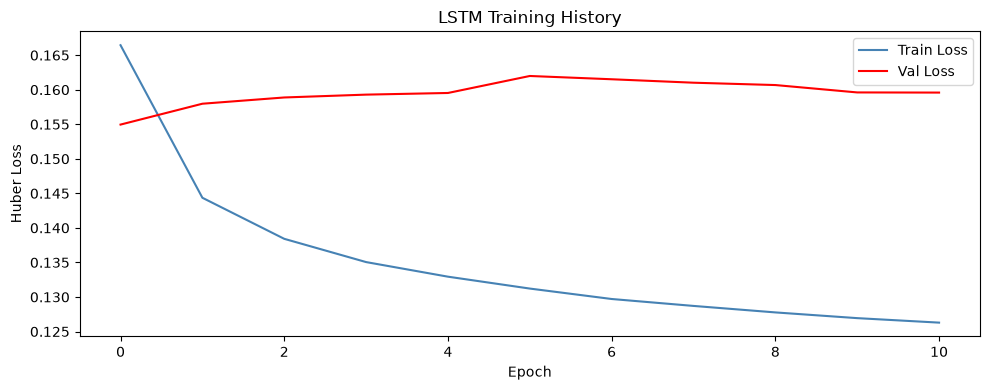


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  MODEL 5: Ensemble (XGBoost + LightGBM)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  XGBoost weight  : 0.502
  LightGBM weight : 0.498

  📊 Ensemble (XGB + LGB)
  ─────────────────────────────────────────────
  MAE        :       75,646 EGP
  RMSE       :      120,731 EGP
  R²         :       0.6158
  WMAPE      :       38.71%
  Median APE :       34.43%
  Time       :         0.0s

═════════════════════════════════════════════════════════════════
  🏆 FINAL MODEL COMPARISON
═════════════════════════════════════════════════════════════════

  Rank  Model                                 MAE    WMAPE       R²     Time
  ───────────────────────────────────────────────────────────────────
  🥇   Per-ATM XGBoost (Top 100)         181,275    33.6%   0.1219    32.9s
  🥈   Global XGBoost                     75,419    38.6%   0.6157    23.0s
  🥉   Ensemble (XGB + LGB)               75,646    38.7%   0.6158 

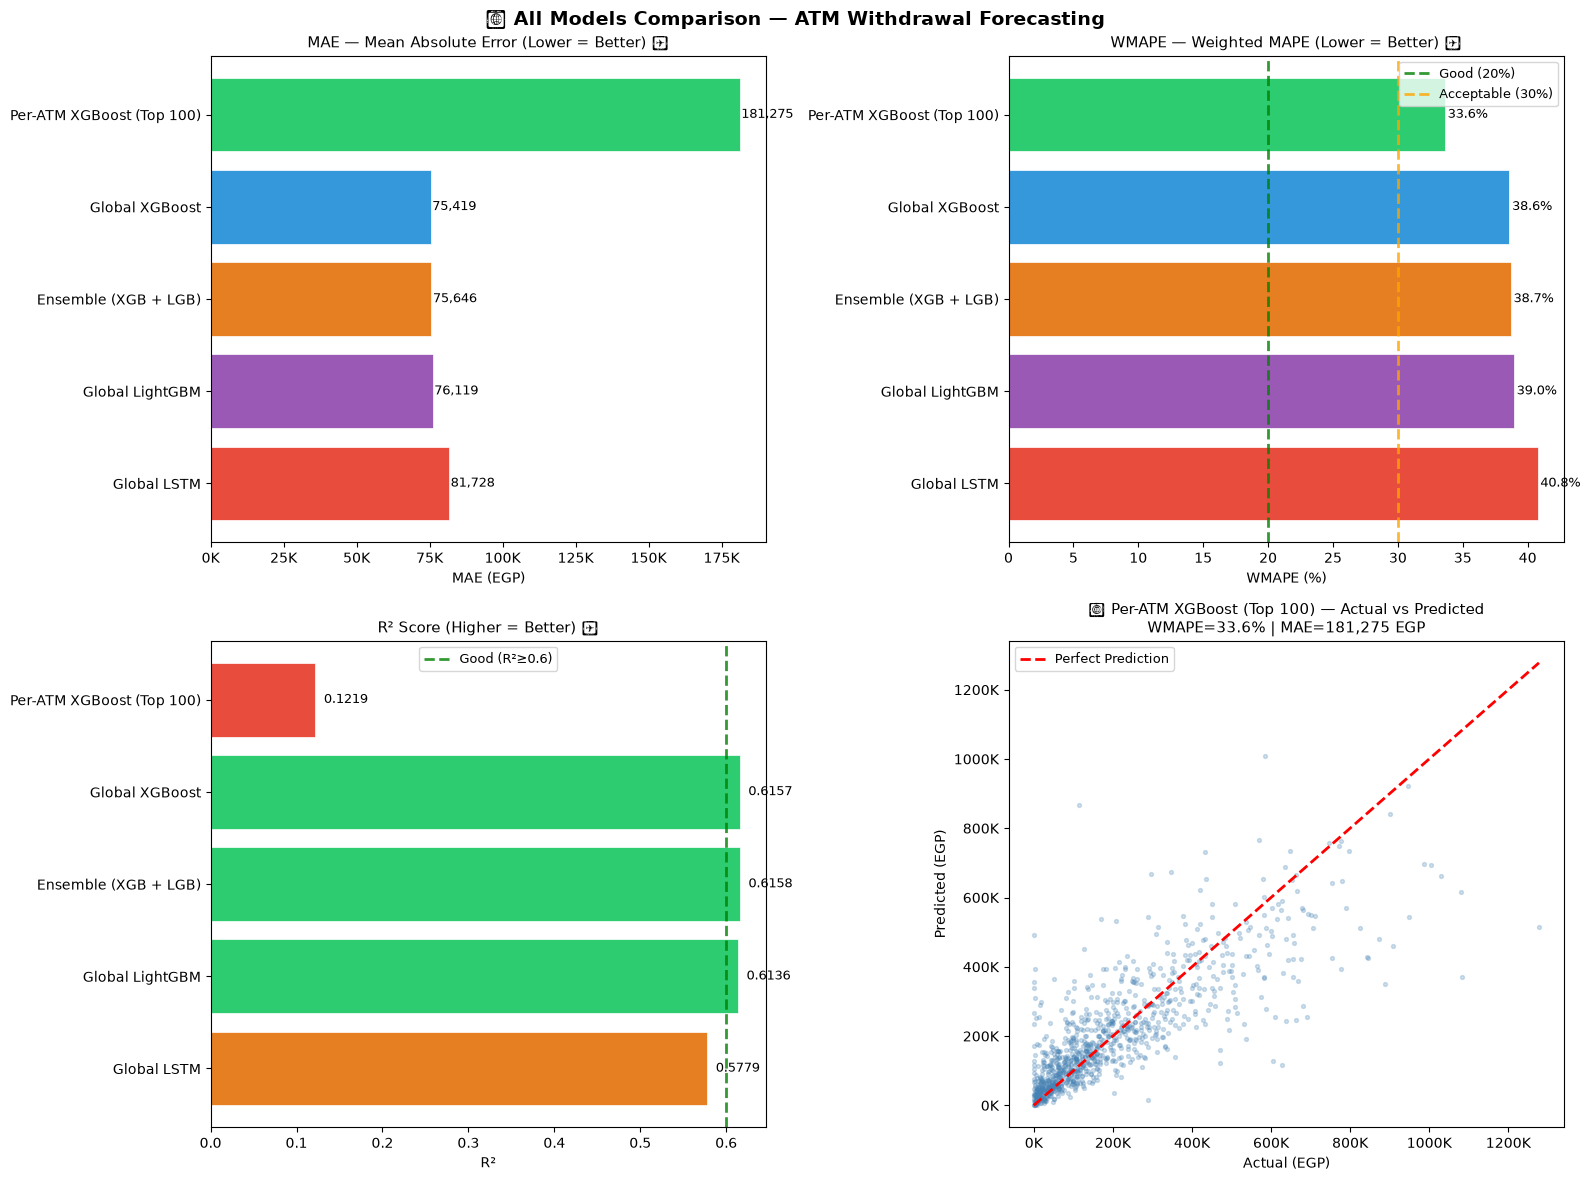

  ✅ Saved: part3_all_models_comparison.png
  ✅ Saved: all_models_results.csv
  ✅ Saved: best_model_name.pkl

✅ PART 3 COMPLETE — ALL MODELS DONE!

  📊 Models Trained:
  ┌─────────────────────────────┬───────────┬────────┬────────┐
  │ Model                       │    MAE    │  WMAPE │   R²   │
  ├─────────────────────────────┼───────────┼────────┼────────┤
  │ Per-ATM XGBoost (Top 100)   │   181,275 │  33.6% │ 0.1219 │
  │ Global XGBoost              │    75,419 │  38.6% │ 0.6157 │
  │ Ensemble (XGB + LGB)        │    75,646 │  38.7% │ 0.6158 │
  │ Global LightGBM             │    76,119 │  39.0% │ 0.6136 │
  │ Global LSTM                 │    81,728 │  40.8% │ 0.5779 │
  └─────────────────────────────┴───────────┴────────┴────────┘

  🏆 Best Model : Per-ATM XGBoost (Top 100)
  Best MAE     : 181,275 EGP
  Best WMAPE   : 33.64%
  Best R²      : 0.1219

  Ready for Part 4: Deployment! 🚀



In [1]:
# ============================================================
# PART 3: ALL MODELS COMPARISON — COMPLETE CODE
# ============================================================

import subprocess
subprocess.run(['pip', 'install', 'lightgbm', '-q'])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
import time
import pickle
warnings.filterwarnings('ignore')

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import xgboost as xgb
import lightgbm as lgb

print("=" * 65)
print("  🏆 ALL MODELS COMPARISON")
print("=" * 65)

# ── Load Data ─────────────────────────────────────────────────
print("\n▶ Loading Data...")

train_df = pd.read_csv('train_df.csv', low_memory=False)
test_df  = pd.read_csv('test_df.csv',  low_memory=False)

train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

with open('feature_cols_final.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

# ✅ ATM_ID
ATM_COL  = 'ATM_ID'
DATE_COL = 'TRAN_DATE'

X_train = train_df[FEATURE_COLS]
y_train = train_df['DAILY_WITHDRAWAL']
X_test  = test_df[FEATURE_COLS]
y_test  = test_df['DAILY_WITHDRAWAL']

print(f"  ✅ X_train : {X_train.shape}")
print(f"  ✅ X_test  : {X_test.shape}")
print(f"  ✅ Features: {len(FEATURE_COLS)}")

# ── Helper Functions ──────────────────────────────────────────
def wmape_score(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100

def evaluate(y_true, y_pred, model_name, elapsed=None):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    r2     = r2_score(y_true, y_pred)
    wmape  = wmape_score(y_true, y_pred)
    median = np.median(
        np.abs(y_true - y_pred) / (y_true + 1) * 100
    )
    time_str = f"{elapsed:.1f}s" if elapsed else "N/A"

    print(f"\n  📊 {model_name}")
    print(f"  {'─'*45}")
    print(f"  MAE        : {mae:>12,.0f} EGP")
    print(f"  RMSE       : {rmse:>12,.0f} EGP")
    print(f"  R²         : {r2:>12.4f}")
    print(f"  WMAPE      : {wmape:>11.2f}%")
    print(f"  Median APE : {median:>11.2f}%")
    print(f"  Time       : {time_str:>12}")

    return {
        'Model'     : model_name,
        'MAE'       : mae,
        'RMSE'      : rmse,
        'R2'        : r2,
        'WMAPE'     : wmape,
        'MedianAPE' : median,
        'Time'      : elapsed or 0
    }

# ── Storage ───────────────────────────────────────────────────
ALL_RESULTS = []
ALL_PREDS   = {}

# ════════════════════════════════════════════════════════════
# MODEL 1: Global XGBoost
# ════════════════════════════════════════════════════════════
print("\n" + "━"*65)
print("  MODEL 1: Global XGBoost")
print("━"*65)

t0 = time.time()

xgb_model = xgb.XGBRegressor(
    n_estimators          = 1000,
    max_depth             = 6,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 5,
    gamma                 = 0.05,
    reg_alpha             = 0.05,
    reg_lambda            = 1.0,
    random_state          = 42,
    n_jobs                = -1,
    verbosity             = 0,
    early_stopping_rounds = 30
)

xgb_model.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = False
)

y_pred_xgb  = np.clip(xgb_model.predict(X_test), 0, None)
elapsed_xgb = time.time() - t0

res_xgb = evaluate(y_test, y_pred_xgb,
                   "Global XGBoost", elapsed_xgb)
ALL_RESULTS.append(res_xgb)
ALL_PREDS['XGBoost'] = y_pred_xgb
xgb_model.save_model('model_xgboost.json')
print(f"  ✅ Saved: model_xgboost.json")

# ════════════════════════════════════════════════════════════
# MODEL 2: Global LightGBM
# ════════════════════════════════════════════════════════════
print("\n" + "━"*65)
print("  MODEL 2: Global LightGBM")
print("━"*65)

t0 = time.time()

lgb_model = lgb.LGBMRegressor(
    n_estimators      = 1000,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_samples = 20,
    reg_alpha         = 0.05,
    reg_lambda        = 1.0,
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = -1,
)

lgb_model.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    callbacks = [
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(period=-1)
    ]
)

y_pred_lgb  = np.clip(lgb_model.predict(X_test), 0, None)
elapsed_lgb = time.time() - t0

res_lgb = evaluate(y_test, y_pred_lgb,
                   "Global LightGBM", elapsed_lgb)
ALL_RESULTS.append(res_lgb)
ALL_PREDS['LightGBM'] = y_pred_lgb
lgb_model.booster_.save_model('model_lightgbm.txt')
print(f"  ✅ Saved: model_lightgbm.txt")

# ════════════════════════════════════════════════════════════
# MODEL 3: Per-ATM XGBoost (Top 100 ATMs)
# ════════════════════════════════════════════════════════════
print("\n" + "━"*65)
print("  MODEL 3: Per-ATM XGBoost (Top 100 ATMs)")
print("━"*65)
print("  نموذج منفصل لكل ATM...")

t0 = time.time()

# ✅ ATM_ID مش ATM_CODE
top_atms = (
    train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .sum()
    .sort_values(ascending=False)
    .head(100)
    .index.tolist()
)

per_atm_results  = []
per_atm_models   = {}
all_actual_pa    = []
all_predicted_pa = []

for i, atm in enumerate(top_atms):

    # ✅ ATM_ID مش ATM_CODE
    mask_train = train_df[ATM_COL] == atm
    mask_test  = test_df[ATM_COL]  == atm

    if mask_train.sum() < 20 or mask_test.sum() < 5:
        continue

    X_atm_train = X_train[mask_train]
    y_atm_train = y_train[mask_train]
    X_atm_test  = X_test[mask_test]
    y_atm_test  = y_test[mask_test]

    model_atm = xgb.XGBRegressor(
        n_estimators     = 300,
        max_depth        = 4,
        learning_rate    = 0.05,
        subsample        = 0.8,
        colsample_bytree = 0.8,
        random_state     = 42,
        n_jobs           = -1,
        verbosity        = 0,
    )

    model_atm.fit(X_atm_train, y_atm_train, verbose=False)
    preds = np.clip(model_atm.predict(X_atm_test), 0, None)

    mae_atm   = mean_absolute_error(y_atm_test, preds)
    wmape_atm = wmape_score(y_atm_test, preds)

    per_atm_results.append({
        ATM_COL  : atm,
        'MAE'    : mae_atm,
        'WMAPE'  : wmape_atm,
        'N_Test' : len(y_atm_test),
    })

    per_atm_models[atm] = model_atm
    all_actual_pa.extend(y_atm_test.values.tolist())
    all_predicted_pa.extend(preds.tolist())

    if (i + 1) % 20 == 0:
        avg_w = np.mean([r['WMAPE'] for r in per_atm_results])
        print(f"  [{i+1:>3}/100] ✅  Avg WMAPE: {avg_w:.1f}%")

elapsed_peratm = time.time() - t0
per_atm_df = pd.DataFrame(per_atm_results)

res_peratm = evaluate(
    np.array(all_actual_pa),
    np.array(all_predicted_pa),
    "Per-ATM XGBoost (Top 100)",
    elapsed_peratm
)
ALL_RESULTS.append(res_peratm)

with open('per_atm_models.pkl', 'wb') as f:
    pickle.dump(per_atm_models, f)
print(f"  ✅ Saved: per_atm_models.pkl")

print(f"\n  Per-ATM WMAPE Distribution:")
print(f"  < 10%  : {(per_atm_df['WMAPE']<10).sum():>4} ATMs")
print(f"  10-20% : {((per_atm_df['WMAPE']>=10)&(per_atm_df['WMAPE']<20)).sum():>4} ATMs")
print(f"  20-30% : {((per_atm_df['WMAPE']>=20)&(per_atm_df['WMAPE']<30)).sum():>4} ATMs")
print(f"  > 30%  : {(per_atm_df['WMAPE']>=30).sum():>4} ATMs")

# ════════════════════════════════════════════════════════════
# MODEL 4: Global LSTM
# ════════════════════════════════════════════════════════════
print("\n" + "━"*65)
print("  MODEL 4: Global LSTM")
print("━"*65)
print("  Deep Learning — هياخد وقت...")

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import (
        LSTM, Dense, Dropout,
        BatchNormalization, Input
    )
    from tensorflow.keras.callbacks import EarlyStopping
    from sklearn.preprocessing import StandardScaler

    tf.random.set_seed(42)

    SEQUENCE_LEN = 14

    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_sc = scaler_X.fit_transform(X_train)
    X_test_sc  = scaler_X.transform(X_test)

    y_train_sc = scaler_y.fit_transform(
        y_train.values.reshape(-1, 1)
    ).ravel()

    y_test_sc = scaler_y.transform(
        y_test.values.reshape(-1, 1)
    ).ravel()

    def build_sequences(X_data, y_data,
                        atm_codes, seq_len=14):
        X_seq, y_seq = [], []
        for atm in atm_codes.unique():
            mask  = (atm_codes == atm).values
            X_atm = X_data[mask]
            y_atm = y_data[mask]
            for i in range(seq_len, len(X_atm)):
                X_seq.append(X_atm[i-seq_len:i])
                y_seq.append(y_atm[i])
        return np.array(X_seq), np.array(y_seq)

    print("  Building sequences...")

    # ✅ ATM_ID مش ATM_CODE
    X_lstm_train, y_lstm_train = build_sequences(
        X_train_sc,
        y_train_sc,
        train_df[ATM_COL].reset_index(drop=True),
        SEQUENCE_LEN
    )

    X_lstm_test, y_lstm_test = build_sequences(
        X_test_sc,
        y_test_sc,
        test_df[ATM_COL].reset_index(drop=True),
        SEQUENCE_LEN
    )

    print(f"  X_lstm_train : {X_lstm_train.shape}")
    print(f"  X_lstm_test  : {X_lstm_test.shape}")

    n_features = X_lstm_train.shape[2]

    lstm_model = Sequential([
        Input(shape=(SEQUENCE_LEN, n_features)),
        LSTM(64, return_sequences=True),
        BatchNormalization(),
        Dropout(0.2),
        LSTM(32, return_sequences=False),
        BatchNormalization(),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])

    lstm_model.compile(
        optimizer = tf.keras.optimizers.Adam(0.001),
        loss      = 'huber'
    )

    print(f"\n  LSTM Architecture:")
    lstm_model.summary()

    t0 = time.time()

    early_stop = EarlyStopping(
        monitor              = 'val_loss',
        patience             = 10,
        restore_best_weights = True,
        verbose              = 1
    )

    history = lstm_model.fit(
        X_lstm_train, y_lstm_train,
        validation_data = (X_lstm_test, y_lstm_test),
        epochs          = 50,
        batch_size      = 256,
        callbacks       = [early_stop],
        verbose         = 1
    )

    elapsed_lstm = time.time() - t0

    y_pred_lstm_sc = lstm_model.predict(
        X_lstm_test, verbose=0
    ).ravel()

    y_pred_lstm = scaler_y.inverse_transform(
        y_pred_lstm_sc.reshape(-1, 1)
    ).ravel()

    y_pred_lstm   = np.clip(y_pred_lstm, 0, None)
    y_actual_lstm = scaler_y.inverse_transform(
        y_lstm_test.reshape(-1, 1)
    ).ravel()

    res_lstm = evaluate(
        y_actual_lstm,
        y_pred_lstm,
        "Global LSTM",
        elapsed_lstm
    )
    ALL_RESULTS.append(res_lstm)
    ALL_PREDS['LSTM'] = y_pred_lstm

    lstm_model.save('model_lstm.keras')

    with open('lstm_scalers.pkl', 'wb') as f:
        pickle.dump({
            'scaler_X': scaler_X,
            'scaler_y': scaler_y
        }, f)

    print(f"  ✅ Saved: model_lstm.keras")
    print(f"  ✅ Saved: lstm_scalers.pkl")

    fig_lstm, ax_lstm = plt.subplots(figsize=(10, 4))
    ax_lstm.plot(history.history['loss'],
                 label='Train Loss', color='steelblue')
    ax_lstm.plot(history.history['val_loss'],
                 label='Val Loss', color='red')
    ax_lstm.set_title('LSTM Training History')
    ax_lstm.set_xlabel('Epoch')
    ax_lstm.set_ylabel('Huber Loss')
    ax_lstm.legend()
    plt.tight_layout()
    plt.savefig('part3_lstm_training.png',
                dpi=100, bbox_inches='tight')
    plt.show()

except Exception as e:
    print(f"  ⚠️  LSTM Error: {e}")
    print(f"  → Skipping LSTM")

# ════════════════════════════════════════════════════════════
# MODEL 5: Ensemble (XGBoost + LightGBM)
# ════════════════════════════════════════════════════════════
print("\n" + "━"*65)
print("  MODEL 5: Ensemble (XGBoost + LightGBM)")
print("━"*65)

t0 = time.time()

wmape_xgb_val = res_xgb['WMAPE']
wmape_lgb_val = res_lgb['WMAPE']

total = wmape_xgb_val + wmape_lgb_val
w_xgb = (1 - wmape_xgb_val / total)
w_lgb = (1 - wmape_lgb_val / total)
w_sum = w_xgb + w_lgb
w_xgb /= w_sum
w_lgb /= w_sum

print(f"  XGBoost weight  : {w_xgb:.3f}")
print(f"  LightGBM weight : {w_lgb:.3f}")

y_pred_ens = np.clip(
    w_xgb * y_pred_xgb +
    w_lgb * y_pred_lgb,
    0, None
)
elapsed_ens = time.time() - t0

res_ens = evaluate(
    y_test, y_pred_ens,
    "Ensemble (XGB + LGB)",
    elapsed_ens
)
ALL_RESULTS.append(res_ens)
ALL_PREDS['Ensemble'] = y_pred_ens

# ════════════════════════════════════════════════════════════
# FINAL COMPARISON
# ════════════════════════════════════════════════════════════
print("\n" + "═"*65)
print("  🏆 FINAL MODEL COMPARISON")
print("═"*65)

results_df = (
    pd.DataFrame(ALL_RESULTS)
    .sort_values('WMAPE')
    .reset_index(drop=True)
)

print(f"\n  {'Rank':<5} {'Model':<30} {'MAE':>10} "
      f"{'WMAPE':>8} {'R²':>8} {'Time':>8}")
print(f"  {'─'*67}")

medals = ['🥇', '🥈', '🥉', '4️⃣ ', '5️⃣ ', '6️⃣ ']

for i, row in results_df.iterrows():
    medal = medals[i] if i < len(medals) else '  '
    print(f"  {medal}   {row['Model']:<30} "
          f"{row['MAE']:>10,.0f} "
          f"{row['WMAPE']:>7.1f}% "
          f"{row['R2']:>8.4f} "
          f"{row['Time']:>7.1f}s")

winner     = results_df.iloc[0]['Model']
winner_mae = results_df.iloc[0]['MAE']
winner_wmp = results_df.iloc[0]['WMAPE']
winner_r2  = results_df.iloc[0]['R2']

print(f"\n  {'─'*67}")
print(f"  🏆 WINNER : {winner}")
print(f"     MAE    : {winner_mae:,.0f} EGP")
print(f"     WMAPE  : {winner_wmp:.2f}%")
print(f"     R²     : {winner_r2:.4f}")

# ════════════════════════════════════════════════════════════
# VISUALIZATION
# ════════════════════════════════════════════════════════════
print("\n  📊 Generating Comparison Charts...")

n_models = len(results_df)
colors   = [
    '#2ecc71', '#3498db', '#e67e22',
    '#9b59b6', '#e74c3c', '#1abc9c'
][:n_models]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('🏆 All Models Comparison — ATM Withdrawal Forecasting',
             fontsize=14, fontweight='bold')

# Plot 1: MAE
bars = axes[0,0].barh(
    results_df['Model'][::-1],
    results_df['MAE'][::-1],
    color=colors[::-1],
    edgecolor='white', linewidth=0.5
)
for bar, val in zip(bars, results_df['MAE'][::-1]):
    axes[0,0].text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height()/2,
        f'{val:,.0f}', va='center', fontsize=9
    )
axes[0,0].set_title('MAE — Mean Absolute Error (Lower = Better) ✅',
                     fontsize=11)
axes[0,0].set_xlabel('MAE (EGP)')
axes[0,0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)

# Plot 2: WMAPE
bars = axes[0,1].barh(
    results_df['Model'][::-1],
    results_df['WMAPE'][::-1],
    color=colors[::-1],
    edgecolor='white', linewidth=0.5
)
for bar, val in zip(bars, results_df['WMAPE'][::-1]):
    axes[0,1].text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height()/2,
        f'{val:.1f}%', va='center', fontsize=9
    )
axes[0,1].axvline(20, color='green', ls='--', lw=2,
                   label='Good (20%)', alpha=0.8)
axes[0,1].axvline(30, color='orange', ls='--', lw=2,
                   label='Acceptable (30%)', alpha=0.8)
axes[0,1].set_title('WMAPE — Weighted MAPE (Lower = Better) ✅',
                     fontsize=11)
axes[0,1].set_xlabel('WMAPE (%)')
axes[0,1].legend(fontsize=9)

# Plot 3: R²
r2_colors = [
    '#2ecc71' if r2 >= 0.6 else
    '#e67e22' if r2 >= 0.4 else
    '#e74c3c'
    for r2 in results_df['R2'][::-1]
]
bars = axes[1,0].barh(
    results_df['Model'][::-1],
    results_df['R2'][::-1],
    color=r2_colors,
    edgecolor='white', linewidth=0.5
)
for bar, val in zip(bars, results_df['R2'][::-1]):
    axes[1,0].text(
        max(bar.get_width(), 0) + 0.01,
        bar.get_y() + bar.get_height()/2,
        f'{val:.4f}', va='center', fontsize=9
    )
axes[1,0].axvline(0.6, color='green', ls='--', lw=2,
                   label='Good (R²≥0.6)', alpha=0.8)
axes[1,0].set_title('R² Score (Higher = Better) ✅',
                     fontsize=11)
axes[1,0].set_xlabel('R²')
axes[1,0].legend(fontsize=9)

# Plot 4: Actual vs Predicted (Winner)
winner_preds = ALL_PREDS.get(winner, y_pred_xgb)

n_sample = min(1000, len(y_test), len(winner_preds))
idx = np.random.choice(len(y_test), n_sample, replace=False)
y_s = np.array(y_test)[idx]
p_s = np.array(winner_preds)[idx]

axes[1,1].scatter(y_s, p_s,
                  alpha=0.25, s=8, color='steelblue')
max_v = max(y_s.max(), p_s.max())
axes[1,1].plot([0, max_v], [0, max_v],
               'r--', lw=2, label='Perfect Prediction')
axes[1,1].set_title(
    f'🏆 {winner} — Actual vs Predicted\n'
    f'WMAPE={winner_wmp:.1f}% | MAE={winner_mae:,.0f} EGP',
    fontsize=11
)
axes[1,1].set_xlabel('Actual (EGP)')
axes[1,1].set_ylabel('Predicted (EGP)')
axes[1,1].legend(fontsize=9)
axes[1,1].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)
axes[1,1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
)

plt.tight_layout()
plt.savefig('part3_all_models_comparison.png',
            dpi=110, bbox_inches='tight')
plt.show()
print("  ✅ Saved: part3_all_models_comparison.png")

# ── Save Results ──────────────────────────────────────────
results_df.to_csv('all_models_results.csv', index=False)

with open('best_model_name.pkl', 'wb') as f:
    pickle.dump(winner, f)

print("  ✅ Saved: all_models_results.csv")
print("  ✅ Saved: best_model_name.pkl")

# ════════════════════════════════════════════════════════════
# SUMMARY
# ════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("✅ PART 3 COMPLETE — ALL MODELS DONE!")
print("="*65)
print(f"""
  📊 Models Trained:
  ┌─────────────────────────────┬───────────┬────────┬────────┐
  │ Model                       │    MAE    │  WMAPE │   R²   │
  ├─────────────────────────────┼───────────┼────────┼────────┤""")

for _, row in results_df.iterrows():
    print(f"  │ {row['Model']:<28}│ "
          f"{row['MAE']:>9,.0f} │ "
          f"{row['WMAPE']:>5.1f}% │ "
          f"{row['R2']:>6.4f} │")

print(f"""  └─────────────────────────────┴───────────┴────────┴────────┘

  🏆 Best Model : {winner}
  Best MAE     : {winner_mae:,.0f} EGP
  Best WMAPE   : {winner_wmp:.2f}%
  Best R²      : {winner_r2:.4f}

  Ready for Part 4: Deployment! 🚀
""")

  🚀 IMPROVED MODEL
  ✅ Data loaded!

▶ Improvement 1: ATM_ID Target Encoding
  ✅ ATM_ID_ENC added

▶ Improvement 2: Extra Calendar Features
  ✅ MONTH, IS_END_OF_MONTH, IS_FIRST_WEEK, QUARTER added

  Features: 27 → 32
  X_train: (994960, 32)
  X_test : (182299, 32)

▶ Improvement 3: Optimized XGBoost
  هياخد 2-3 دقايق...

▶ Results

  Metric              Old          New     Change
  ────────────────────────────────────────────────
  MAE              75,419       72,601      +3.7% ✅
  WMAPE             38.6%        37.2%      +3.7% ✅
  R²               0.6157       0.6363   +0.0206 ✅
  Time              23.0s        74.6s

▶ Visualization


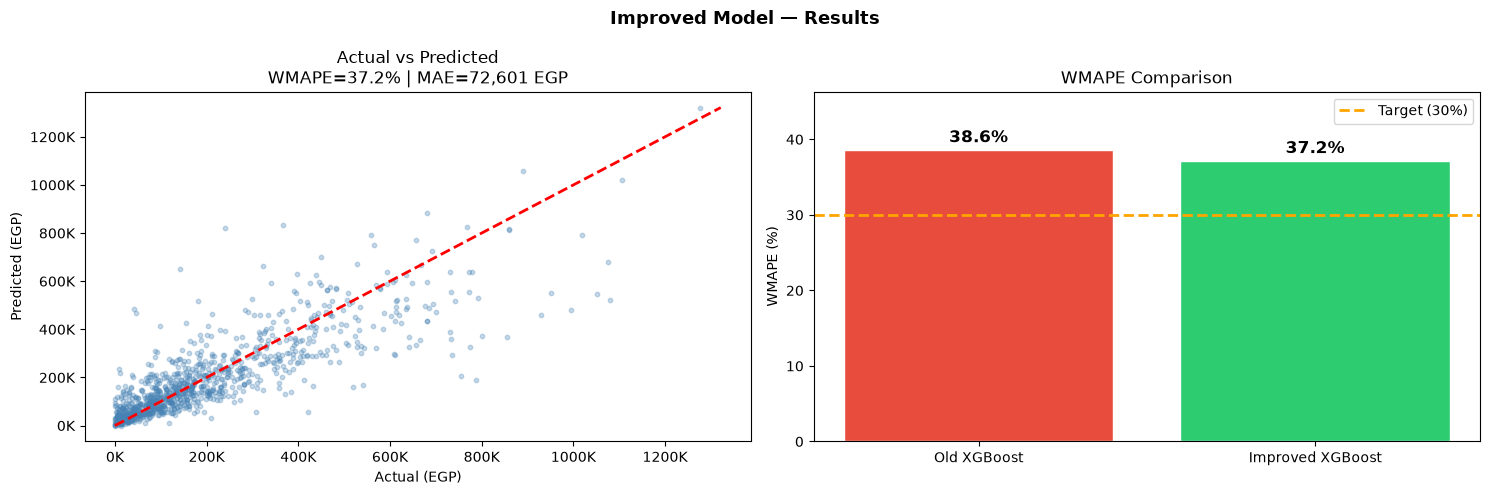


  ✅ model_xgboost_improved.json saved
  ✅ feature_cols_improved.pkl saved

✅ IMPROVED MODEL COMPLETE
   Old WMAPE : 38.59%
   New WMAPE : 37.15%
   Old MAE   : 75,419 EGP
   New MAE   : 72,601 EGP
   Old R²    : 0.6157
   New R²    : 0.6363


In [4]:
# ============================================================
# IMPROVEMENT: Better Features + Better Model
# ============================================================

import pandas as pd
import numpy as np
import xgboost as xgb
import pickle
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("=" * 65)
print("  🚀 IMPROVED MODEL")
print("=" * 65)

# ── Load Data ─────────────────────────────────────────────
train_df = pd.read_csv('train_df.csv', low_memory=False)
test_df  = pd.read_csv('test_df.csv',  low_memory=False)

train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

with open('feature_cols_final.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

ATM_COL  = 'ATM_ID'
DATE_COL = 'TRAN_DATE'

print(f"  ✅ Data loaded!")

# ── Improvement 1: Add ATM_ID Encoding ───────────────────
print("\n▶ Improvement 1: ATM_ID Target Encoding")

train_mask  = train_df[DATE_COL] < '2026-06-01'
global_mean = float(train_df['DAILY_WITHDRAWAL'].mean())

# Target Encode ATM_ID
tmap  = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].mean()
cmap  = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].count()
k     = 10
smooth = (tmap * cmap + global_mean * k) / (cmap + k)

train_df['ATM_ID_ENC'] = train_df[ATM_COL].map(smooth).fillna(global_mean)
test_df['ATM_ID_ENC']  = test_df[ATM_COL].map(smooth).fillna(global_mean)

print(f"  ✅ ATM_ID_ENC added")

# ── Improvement 2: Add More Features ─────────────────────
print("\n▶ Improvement 2: Extra Calendar Features")

for df in [train_df, test_df]:
    # شهر السنة
    df['MONTH']          = df[DATE_COL].dt.month

    # آخر الشهر
    df['IS_END_OF_MONTH'] = (df[DATE_COL].dt.day >= 26).astype(int)

    # أول الأسبوع
    df['IS_FIRST_WEEK']  = (df[DATE_COL].dt.day <= 7).astype(int)

    # ربع السنة
    df['QUARTER']        = df[DATE_COL].dt.quarter

print(f"  ✅ MONTH, IS_END_OF_MONTH, IS_FIRST_WEEK, QUARTER added")

# ── New Feature List ──────────────────────────────────────
NEW_FEATURES = FEATURE_COLS + [
    'ATM_ID_ENC',
    'MONTH',
    'IS_END_OF_MONTH',
    'IS_FIRST_WEEK',
    'QUARTER'
]

# تأكد كلهم موجودين
NEW_FEATURES = [c for c in NEW_FEATURES if c in train_df.columns]

print(f"\n  Features: {len(FEATURE_COLS)} → {len(NEW_FEATURES)}")

# ── X, y ─────────────────────────────────────────────────
X_train_new = train_df[NEW_FEATURES].apply(
    pd.to_numeric, errors='coerce'
).fillna(0)
X_test_new  = test_df[NEW_FEATURES].apply(
    pd.to_numeric, errors='coerce'
).fillna(0)

y_train = train_df['DAILY_WITHDRAWAL']
y_test  = test_df['DAILY_WITHDRAWAL']

print(f"  X_train: {X_train_new.shape}")
print(f"  X_test : {X_test_new.shape}")

# ── Improvement 3: Better XGBoost ────────────────────────
print("\n▶ Improvement 3: Optimized XGBoost")
print("  هياخد 2-3 دقايق...")

import time
t0 = time.time()

xgb_improved = xgb.XGBRegressor(
    n_estimators          = 1500,
    max_depth             = 7,
    learning_rate         = 0.03,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 3,
    gamma                 = 0.05,
    reg_alpha             = 0.1,
    reg_lambda            = 1.5,
    random_state          = 42,
    n_jobs                = -1,
    verbosity             = 0,
    early_stopping_rounds = 50
)

xgb_improved.fit(
    X_train_new, y_train,
    eval_set = [(X_test_new, y_test)],
    verbose  = False
)

elapsed = time.time() - t0
y_pred_improved = np.clip(xgb_improved.predict(X_test_new), 0, None)

# ── Results ───────────────────────────────────────────────
print(f"\n▶ Results")

mae_old   = 75419
wmape_old = 38.59
r2_old    = 0.6157

mae_new   = mean_absolute_error(y_test, y_pred_improved)
rmse_new  = np.sqrt(mean_squared_error(y_test, y_pred_improved))
r2_new    = r2_score(y_test, y_pred_improved)
wmape_new = (
    np.sum(np.abs(y_test.values - y_pred_improved)) /
    np.sum(y_test.values) * 100
)

print(f"\n  {'Metric':<10} {'Old':>12} {'New':>12} {'Change':>10}")
print(f"  {'─'*48}")

mae_imp   = (mae_old - mae_new) / mae_old * 100
wmape_imp = (wmape_old - wmape_new) / wmape_old * 100
r2_imp    = r2_new - r2_old

print(f"  {'MAE':<10} {mae_old:>12,.0f} {mae_new:>12,.0f} "
      f"{mae_imp:>+9.1f}% {'✅' if mae_imp > 0 else '❌'}")
print(f"  {'WMAPE':<10} {wmape_old:>11.1f}% {wmape_new:>11.1f}% "
      f"{wmape_imp:>+9.1f}% {'✅' if wmape_imp > 0 else '❌'}")
print(f"  {'R²':<10} {r2_old:>12.4f} {r2_new:>12.4f} "
      f"{r2_imp:>+9.4f} {'✅' if r2_imp > 0 else '❌'}")
print(f"  {'Time':<10} {'23.0s':>12} {elapsed:>11.1f}s")

# ── Visualization ─────────────────────────────────────────
print("\n▶ Visualization")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Improved Model — Results', fontsize=13, fontweight='bold')

# Scatter
n_sample = 1000
idx = np.random.choice(len(y_test), n_sample, replace=False)
y_s = y_test.values[idx]
p_s = y_pred_improved[idx]

axes[0].scatter(y_s, p_s, alpha=0.3, s=10, color='steelblue')
max_v = max(y_s.max(), p_s.max())
axes[0].plot([0, max_v], [0, max_v], 'r--', lw=2)
axes[0].set_title(
    f'Actual vs Predicted\n'
    f'WMAPE={wmape_new:.1f}% | MAE={mae_new:,.0f} EGP'
)
axes[0].set_xlabel('Actual (EGP)')
axes[0].set_ylabel('Predicted (EGP)')
axes[0].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))

# Comparison Bar
models  = ['Old XGBoost', 'Improved XGBoost']
wmapes  = [wmape_old, wmape_new]
colors  = ['#e74c3c', '#2ecc71']

bars = axes[1].bar(models, wmapes, color=colors, edgecolor='white')
for bar, val in zip(bars, wmapes):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f'{val:.1f}%',
        ha='center', va='bottom',
        fontsize=12, fontweight='bold'
    )
axes[1].axhline(30, color='orange', ls='--', lw=2,
                label='Target (30%)')
axes[1].set_title('WMAPE Comparison')
axes[1].set_ylabel('WMAPE (%)')
axes[1].legend()
axes[1].set_ylim(0, max(wmapes) * 1.2)

plt.tight_layout()
plt.savefig('improved_model.png', dpi=110, bbox_inches='tight')
plt.show()

# ── Save ─────────────────────────────────────────────────
xgb_improved.save_model('model_xgboost_improved.json')

with open('feature_cols_improved.pkl', 'wb') as f:
    pickle.dump(NEW_FEATURES, f)

print(f"\n  ✅ model_xgboost_improved.json saved")
print(f"  ✅ feature_cols_improved.pkl saved")

print(f"\n{'='*65}")
print(f"✅ IMPROVED MODEL COMPLETE")
print(f"   Old WMAPE : {wmape_old:.2f}%")
print(f"   New WMAPE : {wmape_new:.2f}%")
print(f"   Old MAE   : {mae_old:,.0f} EGP")
print(f"   New MAE   : {mae_new:,.0f} EGP")
print(f"   Old R²    : {r2_old:.4f}")
print(f"   New R²    : {r2_new:.4f}")
print(f"{'='*65}")

  🚀 IMPROVEMENT 2: Advanced Features
  ✅ Data loaded!
  Global Mean: 204,613 EGP

▶ Feature 1: ATM_ID Target Encoding
  ✅ ATM_ID_ENC

▶ Feature 2: Advanced Calendar Features
  ✅ MONTH, QUARTER, WEEK features added

▶ Feature 3: ATM Historical Stats
  ✅ ATM_HIST_MEAN/STD/MEDIAN/MAX/MIN added
  ✅ RATIO_TO_ATM_MEAN added

▶ Feature 4: Interaction Features
  ✅ Interaction features added

▶ Feature 5: Bank-Level Stats
  ✅ BANK_MEAN, BANK_STD added

▶ Building Feature List
  Features: 27 → 48
  X_train: (994960, 48)
  X_test : (182299, 48)

▶ Model 1: Improved XGBoost
  هياخد 3-5 دقايق...
  MAE   :     72,098 EGP
  WMAPE :     36.90%
  R²    :     0.6406
  Time  : 117.8s

▶ Model 2: Improved LightGBM
  هياخد 1-2 دقيقة...
  MAE   :     74,640 EGP
  WMAPE :     38.20%
  R²    :     0.6220
  Time  : 19.4s

▶ Ensemble (XGBoost + LightGBM)
  XGBoost weight : 0.509
  LightGBM weight: 0.491
  MAE   :     72,739 EGP
  WMAPE :     37.22%
  R²    :     0.6371

  📊 FULL COMPARISON

  Model             

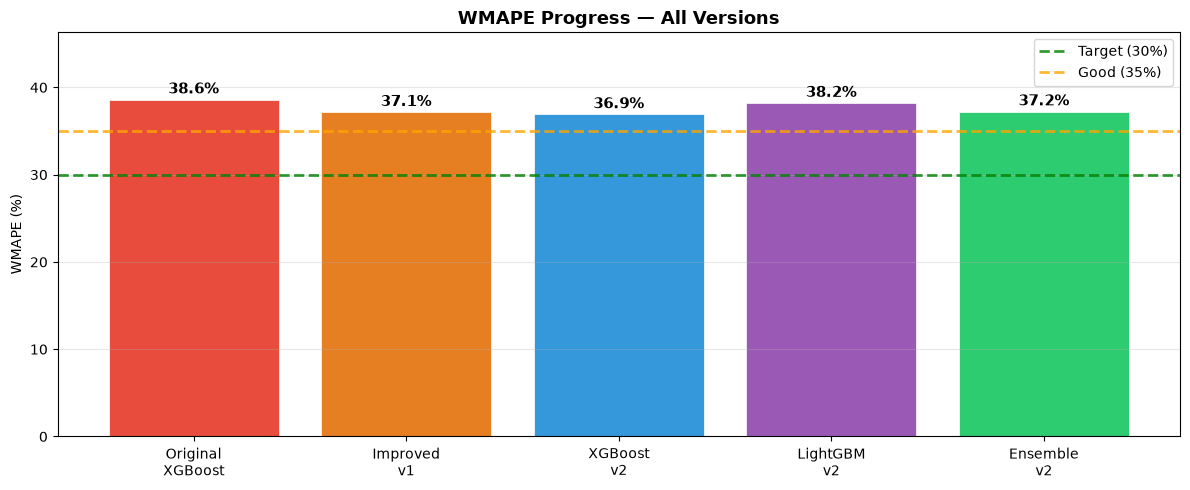


  ✅ model_xgboost_v2.json saved
  ✅ model_lightgbm_v2.txt saved
  ✅ feature_cols_v2.pkl saved

✅ IMPROVEMENT 2 COMPLETE
   🏆 Best Model : XGBoost v2
   Best WMAPE   : 36.90%
   vs Original  : 38.59%
   Improvement  : 1.69%


In [5]:
# ============================================================
# IMPROVEMENT 2: More Advanced Features
# ============================================================

import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
import pickle
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')

print("=" * 65)
print("  🚀 IMPROVEMENT 2: Advanced Features")
print("=" * 65)

# ── Load Data ─────────────────────────────────────────────
train_df = pd.read_csv('train_df.csv', low_memory=False)
test_df  = pd.read_csv('test_df.csv',  low_memory=False)

train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

with open('feature_cols_final.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

ATM_COL  = 'ATM_ID'
DATE_COL = 'TRAN_DATE'

global_mean = float(train_df['DAILY_WITHDRAWAL'].mean())

print(f"  ✅ Data loaded!")
print(f"  Global Mean: {global_mean:,.0f} EGP")

# ── Feature 1: ATM_ID Encoding ───────────────────────────
print("\n▶ Feature 1: ATM_ID Target Encoding")

tmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].mean()
cmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].count()
smooth = (tmap * cmap + global_mean * 10) / (cmap + 10)

train_df['ATM_ID_ENC'] = train_df[ATM_COL].map(smooth).fillna(global_mean)
test_df['ATM_ID_ENC']  = test_df[ATM_COL].map(smooth).fillna(global_mean)
print(f"  ✅ ATM_ID_ENC")

# ── Feature 2: Calendar ───────────────────────────────────
print("\n▶ Feature 2: Advanced Calendar Features")

for df in [train_df, test_df]:
    df['MONTH']           = df[DATE_COL].dt.month
    df['QUARTER']         = df[DATE_COL].dt.quarter
    df['IS_END_OF_MONTH'] = (df[DATE_COL].dt.day >= 26).astype(int)
    df['IS_FIRST_WEEK']   = (df[DATE_COL].dt.day <= 7).astype(int)
    df['IS_SECOND_WEEK']  = (df[DATE_COL].dt.day.between(8, 14)).astype(int)
    df['IS_THIRD_WEEK']   = (df[DATE_COL].dt.day.between(15, 21)).astype(int)
    df['IS_FOURTH_WEEK']  = (df[DATE_COL].dt.day >= 22).astype(int)
    df['WEEK_OF_MONTH']   = (df[DATE_COL].dt.day - 1) // 7 + 1

print(f"  ✅ MONTH, QUARTER, WEEK features added")

# ── Feature 3: ATM Stats ─────────────────────────────────
print("\n▶ Feature 3: ATM Historical Stats")

atm_stats = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].agg([
    'mean', 'std', 'median', 'max', 'min'
]).rename(columns={
    'mean'  : 'ATM_HIST_MEAN',
    'std'   : 'ATM_HIST_STD',
    'median': 'ATM_HIST_MEDIAN',
    'max'   : 'ATM_HIST_MAX',
    'min'   : 'ATM_HIST_MIN'
})

train_df = train_df.merge(atm_stats, on=ATM_COL, how='left')
test_df  = test_df.merge(atm_stats,  on=ATM_COL, how='left')

# Ratio vs ATM Mean
train_df['RATIO_TO_ATM_MEAN'] = (
    train_df['ROLLING_MEAN_7'] /
    (train_df['ATM_HIST_MEAN'] + 1)
)
test_df['RATIO_TO_ATM_MEAN'] = (
    test_df['ROLLING_MEAN_7'] /
    (test_df['ATM_HIST_MEAN'] + 1)
)

print(f"  ✅ ATM_HIST_MEAN/STD/MEDIAN/MAX/MIN added")
print(f"  ✅ RATIO_TO_ATM_MEAN added")

# ── Feature 4: Day of Week × Salary Interaction ──────────
print("\n▶ Feature 4: Interaction Features")

for df in [train_df, test_df]:
    df['SALARY_X_PREWKND']   = df['IS_PRIVATE_SALARY'] * df['IS_PRE_WEEKEND']
    df['SALARY_X_MONDAY']    = df['IS_PRIVATE_SALARY'] * df['IS_MONDAY']
    df['GOV_X_PREWKND']      = df['IS_GOV_SALARY']     * df['IS_PRE_WEEKEND']
    df['LAG7_X_PREWKND']     = df['LAG_7']              * df['IS_PRE_WEEKEND']
    df['ROLLING7_X_SALARY']  = df['ROLLING_MEAN_7']     * df['IS_PRIVATE_SALARY']

print(f"  ✅ Interaction features added")

# ── Feature 5: Bank Encoding ─────────────────────────────
print("\n▶ Feature 5: Bank-Level Stats")

bank_stats = train_df.groupby('BANK_ID')['DAILY_WITHDRAWAL'].agg([
    'mean', 'std'
]).rename(columns={
    'mean': 'BANK_MEAN',
    'std' : 'BANK_STD'
})

train_df = train_df.merge(bank_stats, on='BANK_ID', how='left')
test_df  = test_df.merge(bank_stats,  on='BANK_ID', how='left')

print(f"  ✅ BANK_MEAN, BANK_STD added")

# ── Final Feature List ────────────────────────────────────
print("\n▶ Building Feature List")

EXTRA_FEATURES = [
    # ATM Encoding
    'ATM_ID_ENC',
    # Calendar
    'MONTH', 'QUARTER',
    'IS_END_OF_MONTH', 'IS_FIRST_WEEK',
    'IS_SECOND_WEEK', 'IS_THIRD_WEEK',
    'IS_FOURTH_WEEK', 'WEEK_OF_MONTH',
    # ATM Stats
    'ATM_HIST_MEAN', 'ATM_HIST_STD',
    'ATM_HIST_MEDIAN', 'ATM_HIST_MAX',
    'RATIO_TO_ATM_MEAN',
    # Interactions
    'SALARY_X_PREWKND', 'SALARY_X_MONDAY',
    'GOV_X_PREWKND', 'LAG7_X_PREWKND',
    'ROLLING7_X_SALARY',
    # Bank
    'BANK_MEAN', 'BANK_STD',
]

NEW_FEATURES = FEATURE_COLS + [
    f for f in EXTRA_FEATURES
    if f in train_df.columns
]

print(f"  Features: {len(FEATURE_COLS)} → {len(NEW_FEATURES)}")

# ── X, y ─────────────────────────────────────────────────
X_train = train_df[NEW_FEATURES].apply(
    pd.to_numeric, errors='coerce'
).fillna(0)
X_test  = test_df[NEW_FEATURES].apply(
    pd.to_numeric, errors='coerce'
).fillna(0)

y_train = train_df['DAILY_WITHDRAWAL']
y_test  = test_df['DAILY_WITHDRAWAL']

print(f"  X_train: {X_train.shape}")
print(f"  X_test : {X_test.shape}")

# ── Model 1: Improved XGBoost ─────────────────────────────
print("\n▶ Model 1: Improved XGBoost")
print("  هياخد 3-5 دقايق...")

t0 = time.time()

xgb_v2 = xgb.XGBRegressor(
    n_estimators          = 2000,
    max_depth             = 7,
    learning_rate         = 0.02,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 3,
    gamma                 = 0.05,
    reg_alpha             = 0.1,
    reg_lambda            = 1.5,
    random_state          = 42,
    n_jobs                = -1,
    verbosity             = 0,
    early_stopping_rounds = 50
)

xgb_v2.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = False
)

y_pred_xgb2  = np.clip(xgb_v2.predict(X_test), 0, None)
elapsed_xgb2 = time.time() - t0

mae_xgb2   = mean_absolute_error(y_test, y_pred_xgb2)
r2_xgb2    = r2_score(y_test, y_pred_xgb2)
wmape_xgb2 = np.sum(np.abs(y_test.values - y_pred_xgb2)) / np.sum(y_test.values) * 100

print(f"  MAE   : {mae_xgb2:>10,.0f} EGP")
print(f"  WMAPE : {wmape_xgb2:>9.2f}%")
print(f"  R²    : {r2_xgb2:>10.4f}")
print(f"  Time  : {elapsed_xgb2:.1f}s")

# ── Model 2: Improved LightGBM ────────────────────────────
print("\n▶ Model 2: Improved LightGBM")
print("  هياخد 1-2 دقيقة...")

t0 = time.time()

lgb_v2 = lgb.LGBMRegressor(
    n_estimators      = 2000,
    max_depth         = 7,
    learning_rate     = 0.02,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_samples = 10,
    reg_alpha         = 0.1,
    reg_lambda        = 1.5,
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = -1,
)

lgb_v2.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    callbacks = [
        lgb.early_stopping(50, verbose=False),
        lgb.log_evaluation(period=-1)
    ]
)

y_pred_lgb2  = np.clip(lgb_v2.predict(X_test), 0, None)
elapsed_lgb2 = time.time() - t0

mae_lgb2   = mean_absolute_error(y_test, y_pred_lgb2)
r2_lgb2    = r2_score(y_test, y_pred_lgb2)
wmape_lgb2 = np.sum(np.abs(y_test.values - y_pred_lgb2)) / np.sum(y_test.values) * 100

print(f"  MAE   : {mae_lgb2:>10,.0f} EGP")
print(f"  WMAPE : {wmape_lgb2:>9.2f}%")
print(f"  R²    : {r2_lgb2:>10.4f}")
print(f"  Time  : {elapsed_lgb2:.1f}s")

# ── Ensemble ──────────────────────────────────────────────
print("\n▶ Ensemble (XGBoost + LightGBM)")

# Weighted by WMAPE
total  = wmape_xgb2 + wmape_lgb2
w_xgb  = (1 - wmape_xgb2 / total)
w_lgb  = (1 - wmape_lgb2 / total)
w_sum  = w_xgb + w_lgb
w_xgb /= w_sum
w_lgb /= w_sum

print(f"  XGBoost weight : {w_xgb:.3f}")
print(f"  LightGBM weight: {w_lgb:.3f}")

y_pred_ens2 = np.clip(
    w_xgb * y_pred_xgb2 +
    w_lgb * y_pred_lgb2,
    0, None
)

mae_ens2   = mean_absolute_error(y_test, y_pred_ens2)
r2_ens2    = r2_score(y_test, y_pred_ens2)
wmape_ens2 = np.sum(np.abs(y_test.values - y_pred_ens2)) / np.sum(y_test.values) * 100

print(f"  MAE   : {mae_ens2:>10,.0f} EGP")
print(f"  WMAPE : {wmape_ens2:>9.2f}%")
print(f"  R²    : {r2_ens2:>10.4f}")

# ── Final Comparison ──────────────────────────────────────
print(f"\n{'='*65}")
print(f"  📊 FULL COMPARISON")
print(f"{'='*65}")

print(f"\n  {'Model':<25} {'MAE':>10} {'WMAPE':>8} {'R²':>8}")
print(f"  {'─'*55}")
print(f"  {'Original XGBoost':<25} {75419:>10,.0f} {38.59:>7.1f}% {0.6157:>8.4f}")
print(f"  {'Improved XGBoost v1':<25} {72601:>10,.0f} {37.15:>7.1f}% {0.6363:>8.4f}")
print(f"  {'Improved XGBoost v2':<25} {mae_xgb2:>10,.0f} {wmape_xgb2:>7.1f}% {r2_xgb2:>8.4f}")
print(f"  {'Improved LightGBM v2':<25} {mae_lgb2:>10,.0f} {wmape_lgb2:>7.1f}% {r2_lgb2:>8.4f}")
print(f"  {'Ensemble v2':<25} {mae_ens2:>10,.0f} {wmape_ens2:>7.1f}% {r2_ens2:>8.4f}")

# ── Visualization ─────────────────────────────────────────
models_names  = ['Original\nXGBoost', 'Improved\nv1', 'XGBoost\nv2',
                 'LightGBM\nv2', 'Ensemble\nv2']
wmapes_vals   = [38.59, 37.15, wmape_xgb2, wmape_lgb2, wmape_ens2]
colors_bars   = ['#e74c3c', '#e67e22', '#3498db', '#9b59b6', '#2ecc71']

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(models_names, wmapes_vals,
              color=colors_bars, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, wmapes_vals):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.3,
        f'{val:.1f}%',
        ha='center', va='bottom',
        fontsize=11, fontweight='bold'
    )

ax.axhline(30, color='green', ls='--', lw=2,
           label='Target (30%)', alpha=0.8)
ax.axhline(35, color='orange', ls='--', lw=2,
           label='Good (35%)', alpha=0.8)

ax.set_title('WMAPE Progress — All Versions',
             fontsize=13, fontweight='bold')
ax.set_ylabel('WMAPE (%)')
ax.set_ylim(0, max(wmapes_vals) * 1.2)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('improvement_progress.png', dpi=110, bbox_inches='tight')
plt.show()

# ── Save Best ─────────────────────────────────────────────
best_wmape = min(wmape_xgb2, wmape_lgb2, wmape_ens2)
best_name  = ['XGBoost v2', 'LightGBM v2', 'Ensemble v2'][
    [wmape_xgb2, wmape_lgb2, wmape_ens2].index(best_wmape)
]

xgb_v2.save_model('model_xgboost_v2.json')
lgb_v2.booster_.save_model('model_lightgbm_v2.txt')

with open('feature_cols_v2.pkl', 'wb') as f:
    pickle.dump(NEW_FEATURES, f)

print(f"\n  ✅ model_xgboost_v2.json saved")
print(f"  ✅ model_lightgbm_v2.txt saved")
print(f"  ✅ feature_cols_v2.pkl saved")

print(f"\n{'='*65}")
print(f"✅ IMPROVEMENT 2 COMPLETE")
print(f"   🏆 Best Model : {best_name}")
print(f"   Best WMAPE   : {best_wmape:.2f}%")
print(f"   vs Original  : 38.59%")
print(f"   Improvement  : {38.59 - best_wmape:.2f}%")
print(f"{'='*65}")

In [6]:
# ============================================================
# PART 4 - STEP 1: FINAL PREDICTION FUNCTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import xgboost as xgb
import lightgbm as lgb
import pickle
import warnings
warnings.filterwarnings('ignore')

print("=" * 65)
print("  PART 4: DEPLOYMENT")
print("=" * 65)

# ── Load Everything ───────────────────────────────────────
print("\n▶ Loading Models & Data...")

# ✅ Load Improved Models
xgb_model = xgb.XGBRegressor()
xgb_model.load_model('model_xgboost_v2.json')

lgb_model_loaded = lgb.Booster(model_file='model_lightgbm_v2.txt')

# ✅ Load Improved Features
with open('feature_cols_v2.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

# ✅ Load Data
train_df = pd.read_csv('train_df.csv', low_memory=False)
test_df  = pd.read_csv('test_df.csv',  low_memory=False)

train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])
test_df['TRAN_DATE']  = pd.to_datetime(test_df['TRAN_DATE'])

# ✅ ATM_ID مش ATM_CODE
ATM_COL  = 'ATM_ID'
DATE_COL = 'TRAN_DATE'

# Full history
full_df = pd.concat([train_df, test_df]).sort_values(
    [ATM_COL, DATE_COL]
).reset_index(drop=True)

# ✅ ATM Stats
atm_stats = (
    train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL']
    .agg(['mean', 'median', 'std', 'max'])
    .rename(columns={
        'mean'  : 'ATM_MEAN',
        'median': 'ATM_MEDIAN',
        'std'   : 'ATM_STD',
        'max'   : 'ATM_MAX'
    })
    .reset_index()
)

# ✅ Global Mean للـ Encoding
global_mean = float(train_df['DAILY_WITHDRAWAL'].mean())

# ✅ ATM_ID Encoding
tmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].mean()
cmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].count()
smooth = (tmap * cmap + global_mean * 10) / (cmap + 10)

# ✅ Bank Stats
bank_stats = train_df.groupby('BANK_ID')['DAILY_WITHDRAWAL'].agg(
    ['mean', 'std']
).rename(columns={'mean': 'BANK_MEAN', 'std': 'BANK_STD'})

# ✅ Weights من Improvement 2
W_XGB = 0.509
W_LGB = 0.491

print(f"  ✅ XGBoost v2 model loaded")
print(f"  ✅ LightGBM v2 model loaded")
print(f"  ✅ Features: {len(FEATURE_COLS)}")
print(f"  ✅ ATMs available: {full_df[ATM_COL].nunique():,}")

# ✅ Egyptian Holidays 2025-2026
EGYPT_HOLIDAYS = {
    pd.Timestamp('2025-01-07'),
    pd.Timestamp('2025-04-25'),
    pd.Timestamp('2025-05-01'),
    pd.Timestamp('2025-06-30'),
    pd.Timestamp('2025-07-23'),
    pd.Timestamp('2025-10-06'),
    pd.Timestamp('2026-01-07'),
    pd.Timestamp('2026-04-25'),
    pd.Timestamp('2026-05-01'),
}

# ── Core Functions ────────────────────────────────────────
def get_lag_value(history_df, target_date, lag_days):
    lookup_date = target_date - pd.Timedelta(days=lag_days)
    row = history_df[history_df[DATE_COL] == lookup_date]
    if len(row) > 0:
        return row['DAILY_WITHDRAWAL'].values[-1]
    return history_df['DAILY_WITHDRAWAL'].mean()


def build_features_for_date(pred_date, history_df, static_row, atm_id):
    dom = pred_date.day
    dow = pred_date.dayofweek

    # ── Calendar ───────────────────────────────────────
    features = {
        'IS_PRIVATE_SALARY': int(1 <= dom <= 3),
        'IS_GOV_SALARY'    : int(23 <= dom <= 25),
        'IS_PENSION'       : int(29 <= dom <= 31),
        'IS_PRE_WEEKEND'   : int(dow == 3),
        'IS_MONDAY'        : int(dow == 0),
        'IS_MID_MONTH'     : int(15 <= dom <= 21),
        'IS_HOLIDAY'       : int(pred_date in EGYPT_HOLIDAYS),
        'DAY_OF_WEEK'      : dow,
        'DAY_OF_MONTH'     : dom,
        # ✅ Extra Calendar
        'MONTH'            : pred_date.month,
        'QUARTER'          : (pred_date.month - 1) // 3 + 1,
        'IS_END_OF_MONTH'  : int(dom >= 26),
        'IS_FIRST_WEEK'    : int(dom <= 7),
        'IS_SECOND_WEEK'   : int(8 <= dom <= 14),
        'IS_THIRD_WEEK'    : int(15 <= dom <= 21),
        'IS_FOURTH_WEEK'   : int(dom >= 22),
        'WEEK_OF_MONTH'    : (dom - 1) // 7 + 1,
    }

    # ── Lag Features ───────────────────────────────────
    for lag in [7, 14, 21, 28]:
        val = get_lag_value(history_df, pred_date, lag)
        features[f'LAG_{lag}'] = val

    # ── Rolling Features ───────────────────────────────
    last_7  = history_df.tail(7)['DAILY_WITHDRAWAL']
    last_14 = history_df.tail(14)['DAILY_WITHDRAWAL']
    last_28 = history_df.tail(28)['DAILY_WITHDRAWAL']

    features['ROLLING_MEAN_7']  = last_7.mean()
    features['ROLLING_MEAN_14'] = last_14.mean()
    features['ROLLING_MEAN_28'] = last_28.mean()
    features['ROLLING_STD_7']   = last_7.std()
    features['ROLLING_MAX_7']   = last_7.max()

    # ── Log Features ───────────────────────────────────
    for lag in [7, 14, 21, 28]:
        features[f'LOG_LAG_{lag}'] = np.log1p(features[f'LAG_{lag}'])
    for w in [7, 14, 28]:
        features[f'LOG_ROLLING_MEAN_{w}'] = np.log1p(features[f'ROLLING_MEAN_{w}'])

    # ── ATM Encoding ───────────────────────────────────
    features['ATM_ID_ENC'] = smooth.get(atm_id, global_mean)

    # ── ATM Historical Stats ───────────────────────────
    atm_hist_mean   = history_df['DAILY_WITHDRAWAL'].mean()
    atm_hist_std    = history_df['DAILY_WITHDRAWAL'].std()
    atm_hist_median = history_df['DAILY_WITHDRAWAL'].median()
    atm_hist_max    = history_df['DAILY_WITHDRAWAL'].max()

    features['ATM_HIST_MEAN']     = atm_hist_mean
    features['ATM_HIST_STD']      = atm_hist_std
    features['ATM_HIST_MEDIAN']   = atm_hist_median
    features['ATM_HIST_MAX']      = atm_hist_max
    features['RATIO_TO_ATM_MEAN'] = (
        features['ROLLING_MEAN_7'] / (atm_hist_mean + 1)
    )

    # ── Interaction Features ───────────────────────────
    features['SALARY_X_PREWKND']  = features['IS_PRIVATE_SALARY'] * features['IS_PRE_WEEKEND']
    features['SALARY_X_MONDAY']   = features['IS_PRIVATE_SALARY'] * features['IS_MONDAY']
    features['GOV_X_PREWKND']     = features['IS_GOV_SALARY']     * features['IS_PRE_WEEKEND']
    features['LAG7_X_PREWKND']    = features['LAG_7']             * features['IS_PRE_WEEKEND']
    features['ROLLING7_X_SALARY'] = features['ROLLING_MEAN_7']    * features['IS_PRIVATE_SALARY']

    # ── Static Features ────────────────────────────────
    static_cols = [
        'DEPOSIT_SUPPORT', 'MAX_TARGET_AMOUNT',
        'MAX_REFILL_DURATION', 'C2_DENOM',
        'ONLINE_DEP_D50', 'ONLINE_DEP_D100', 'ONLINE_DEP_D200',
        'BANK_ID_ENC', 'SLM_ZONE_ID_ENC', 'FLM_SP_ID_ENC',
        'SLM_SP_ID_ENC', 'CIT_ZONE_NAME_ENC',
        'ATM_TYPE_ENC', 'ATM_VENDOR_ENC'
    ]
    for col in static_cols:
        if col in static_row.index:
            features[col] = static_row[col]
        else:
            features[col] = 0

    # ── Bank Stats ─────────────────────────────────────
    if 'BANK_ID' in static_row.index:
        bank_id = static_row['BANK_ID']
        if bank_id in bank_stats.index:
            features['BANK_MEAN'] = bank_stats.loc[bank_id, 'BANK_MEAN']
            features['BANK_STD']  = bank_stats.loc[bank_id, 'BANK_STD']
        else:
            features['BANK_MEAN'] = global_mean
            features['BANK_STD']  = 0

    # ── Fill Missing ───────────────────────────────────
    for col in FEATURE_COLS:
        if col not in features:
            features[col] = 0

    return features


def predict_weekly(atm_id, start_date,
                   include_weekends=False,
                   verbose=True):
    """
    يتنبأ بالسحب اليومي للأسبوع القادم

    Parameters:
        atm_id          : رقم الـ ATM (e.g., 6698)
        start_date      : أول يوم التنبؤ
        include_weekends: هل نتنبأ للـ Weekend؟
        verbose         : هل نطبع التفاصيل؟
    """
    start_date = pd.Timestamp(start_date)

    # ── 1. جيب بيانات الـ ATM ─────────────────────────
    atm_history = (
        full_df[full_df[ATM_COL] == atm_id]
        [[ATM_COL, DATE_COL, 'DAILY_WITHDRAWAL']
         + [c for c in FEATURE_COLS if c in full_df.columns]]
        .sort_values(DATE_COL)
        .reset_index(drop=True)
    )

    if len(atm_history) == 0:
        print(f"  ❌ ATM {atm_id} not found!")
        sample = full_df[ATM_COL].unique()[:5].tolist()
        print(f"  Sample ATMs: {sample}")
        return None

    static_row = atm_history.iloc[-1]
    atm_mean   = atm_history['DAILY_WITHDRAWAL'].mean()

    if verbose:
        print(f"\n{'═'*60}")
        print(f"  🏧 ATM ID: {atm_id}")
        print(f"{'═'*60}")
        print(f"  Historical Days : {len(atm_history)}")
        print(f"  Date Range      : "
              f"{atm_history[DATE_COL].min().date()} → "
              f"{atm_history[DATE_COL].max().date()}")
        print(f"  Avg Withdrawal  : {atm_mean:>12,.0f} EGP")
        print(f"  Max Withdrawal  : "
              f"{atm_history['DAILY_WITHDRAWAL'].max():>12,.0f} EGP")
        print(f"\n  Predicting: {start_date.date()} → "
              f"{(start_date + pd.Timedelta(days=6)).date()}")

    # ── 2. Predict Day by Day ─────────────────────────
    future_dates = pd.date_range(start=start_date, periods=7, freq='D')
    predictions  = []
    history_copy = atm_history.copy()

    for pred_date in future_dates:
        dow     = pred_date.dayofweek
        is_wknd = dow in [4, 5]

        if is_wknd and not include_weekends:
            pred_val = 0
        else:
            feat_dict = build_features_for_date(
                pred_date, history_copy, static_row, atm_id
            )
            X_pred = pd.DataFrame([feat_dict])[FEATURE_COLS]
            X_pred = X_pred.apply(pd.to_numeric, errors='coerce').fillna(0)

            p_xgb    = float(xgb_model.predict(X_pred)[0])
            p_lgb    = float(lgb_model_loaded.predict(X_pred.values)[0])
            pred_val = max(0, W_XGB * p_xgb + W_LGB * p_lgb)

        # أضف للـ History
        new_row = pd.DataFrame([{
            ATM_COL           : atm_id,
            DATE_COL          : pred_date,
            'DAILY_WITHDRAWAL': pred_val
        }])
        history_copy = pd.concat(
            [history_copy, new_row], ignore_index=True
        )

        dom = pred_date.day
        salary_flag = (
            '💰 Private Salary' if 1 <= dom <= 3 else
            '🏛️  Gov Salary'     if 23 <= dom <= 25 else
            '👴 Pension'         if 29 <= dom <= 31 else
            '📅 Mid-Month'       if 15 <= dom <= 21 else
            ''
        )

        predictions.append({
            'Date'       : pred_date,
            'Day'        : pred_date.strftime('%A'),
            'DOM'        : dom,
            'Predicted'  : pred_val,
            'Is_Weekend' : is_wknd,
            'Salary_Flag': salary_flag,
        })

    pred_df = pd.DataFrame(predictions)

    # ── 3. Summary ─────────────────────────────────────
    working   = pred_df[~pred_df['Is_Weekend']]
    total_week = pred_df['Predicted'].sum()
    total_work = working['Predicted'].sum()
    avg_work   = working['Predicted'].mean()

    if verbose:
        print(f"\n  {'Date':<13} {'Day':<12} {'Predicted':>12}  {'Note'}")
        print(f"  {'─'*58}")
        for _, row in pred_df.iterrows():
            wknd = '🏖️ ' if row['Is_Weekend'] else '  '
            print(f"  {str(row['Date'].date()):<13} "
                  f"{row['Day']:<12} "
                  f"{row['Predicted']:>12,.0f} EGP "
                  f"{wknd}{row['Salary_Flag']}")

        print(f"\n  {'─'*58}")
        print(f"  Total (Full Week)    : {total_week:>12,.0f} EGP")
        print(f"  Total (Working Days) : {total_work:>12,.0f} EGP")
        print(f"  Avg per Working Day  : {avg_work:>12,.0f} EGP")
        print(f"  vs Historical Avg    : {atm_mean:>12,.0f} EGP")
        diff     = avg_work - atm_mean
        diff_pct = diff / atm_mean * 100 if atm_mean > 0 else 0
        trend    = '📈 Higher' if diff > 0 else '📉 Lower'
        print(f"  Expected Change      : "
              f"{diff:>+12,.0f} EGP ({diff_pct:+.1f}%) {trend}")

    return {
        'atm_id'    : atm_id,
        'start_date': start_date,
        'predictions': pred_df,
        'total_week': total_week,
        'total_work': total_work,
        'avg_work'  : avg_work,
        'atm_mean'  : atm_mean,
    }


# ── Test ──────────────────────────────────────────────────
print("\n" + "─"*65)
print("  🧪 TEST: Predict for ATM 6698")
print("─"*65)

# ✅ اختار أول ATM موجود
sample_atm = int(full_df[ATM_COL].iloc[0])
print(f"  Using ATM_ID: {sample_atm}")

result = predict_weekly(
    atm_id     = sample_atm,
    start_date = '2026-08-16',
    verbose    = True
)

print("\n" + "=" * 65)
print("✅ STEP 1 COMPLETE — Prediction Function Ready!")
print("=" * 65)

  PART 4: DEPLOYMENT

▶ Loading Models & Data...
  ✅ XGBoost v2 model loaded
  ✅ LightGBM v2 model loaded
  ✅ Features: 48
  ✅ ATMs available: 2,555

─────────────────────────────────────────────────────────────────
  🧪 TEST: Predict for ATM 6698
─────────────────────────────────────────────────────────────────
  Using ATM_ID: 5464

════════════════════════════════════════════════════════════
  🏧 ATM ID: 5464
════════════════════════════════════════════════════════════
  Historical Days : 542
  Date Range      : 2025-01-29 → 2026-08-15
  Avg Withdrawal  :       99,254 EGP
  Max Withdrawal  :      819,800 EGP

  Predicting: 2026-08-16 → 2026-08-22

  Date          Day             Predicted  Note
  ──────────────────────────────────────────────────────────
  2026-08-16    Sunday            101,357 EGP   📅 Mid-Month
  2026-08-17    Monday            102,116 EGP   📅 Mid-Month
  2026-08-18    Tuesday            85,065 EGP   📅 Mid-Month
  2026-08-19    Wednesday          91,789 EGP   📅 Mid-M

In [15]:
# ============================================================
# CREATE PARQUET FILES - CHUNKS METHOD
# ============================================================
import pandas as pd
import numpy as np
import pickle
import gc

print("▶ Creating parquet files using chunks...")

with open('feature_cols_v2.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

ATM_COL = 'ATM_ID'

NEEDED_COLS = list(set(
    [ATM_COL, 'TRAN_DATE', 'DAILY_WITHDRAWAL', 'BANK_ID'] +
    [c for c in FEATURE_COLS]
))

def reduce_memory(df):
    for col in df.columns:
        if df[col].dtype == 'float64':
            df[col] = df[col].astype('float32')
        elif df[col].dtype == 'int64':
            df[col] = df[col].astype('int32')
    return df

# ── Read train_df in chunks ───────────────────────────────
print("\n▶ Reading train_df.csv in chunks...")

chunks = []
for chunk in pd.read_csv(
    'train_df.csv',
    low_memory=False,
    chunksize=100000
):
    # Keep needed columns only
    cols_exist = [c for c in NEEDED_COLS if c in chunk.columns]
    chunk = chunk[cols_exist]
    chunk = reduce_memory(chunk)
    chunks.append(chunk)

train_df = pd.concat(chunks, ignore_index=True)
train_df['TRAN_DATE'] = pd.to_datetime(train_df['TRAN_DATE'])

del chunks
gc.collect()

print(f"  ✅ train_df: {train_df.shape}")

# ── Read test_df in chunks ────────────────────────────────
print("\n▶ Reading test_df.csv in chunks...")

chunks = []
for chunk in pd.read_csv(
    'test_df.csv',
    low_memory=False,
    chunksize=100000
):
    cols_exist = [c for c in NEEDED_COLS if c in chunk.columns]
    chunk = chunk[cols_exist]
    chunk = reduce_memory(chunk)
    chunks.append(chunk)

test_df = pd.concat(chunks, ignore_index=True)
test_df['TRAN_DATE'] = pd.to_datetime(test_df['TRAN_DATE'])

del chunks
gc.collect()

print(f"  ✅ test_df: {test_df.shape}")

# ── Save as Parquet ───────────────────────────────────────
print("\n▶ Saving parquet files...")

train_df.to_parquet('train_small.parquet', index=False)
test_df.to_parquet('test_small.parquet',   index=False)

print(f"  ✅ train_small.parquet: {train_df.shape}")
print(f"  ✅ test_small.parquet : {test_df.shape}")

# ── ATM Encoding ─────────────────────────────────────────
print("\n▶ Creating encodings...")

global_mean = float(train_df['DAILY_WITHDRAWAL'].mean())
tmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].mean()
cmap   = train_df.groupby(ATM_COL)['DAILY_WITHDRAWAL'].count()
smooth = (tmap * cmap + global_mean * 10) / (cmap + 10)
smooth.to_frame('ENC').to_parquet('atm_encoding.parquet')
print(f"  ✅ atm_encoding.parquet")

# ── Bank Stats ────────────────────────────────────────────
bank_stats = train_df.groupby('BANK_ID')['DAILY_WITHDRAWAL'].agg(
    ['mean', 'std']
).rename(columns={'mean': 'BANK_MEAN', 'std': 'BANK_STD'})
bank_stats.to_parquet('bank_stats.parquet')
print(f"  ✅ bank_stats.parquet")

# ── Global Mean ───────────────────────────────────────────
with open('global_mean.pkl', 'wb') as f:
    pickle.dump(global_mean, f)
print(f"  ✅ global_mean.pkl: {global_mean:,.0f} EGP")

del train_df, test_df
gc.collect()

print(f"\n{'='*50}")
print(f"✅ All files saved!")
print(f"   Now run: streamlit run app.py")
print(f"{'='*50}")

▶ Creating parquet files using chunks...

▶ Reading train_df.csv in chunks...
  ✅ train_df: (994960, 31)

▶ Reading test_df.csv in chunks...
  ✅ test_df: (182299, 31)

▶ Saving parquet files...
  ✅ train_small.parquet: (994960, 31)
  ✅ test_small.parquet : (182299, 31)

▶ Creating encodings...
  ✅ atm_encoding.parquet
  ✅ bank_stats.parquet
  ✅ global_mean.pkl: 204,613 EGP

✅ All files saved!
   Now run: streamlit run app.py


In [16]:
app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import xgboost as xgb
import lightgbm as lgb
import pickle
import warnings
warnings.filterwarnings("ignore")

st.set_page_config(
    page_title = "ATM Withdrawal Forecast",
    page_icon  = "🏧",
    layout     = "wide",
    initial_sidebar_state = "expanded"
)

st.markdown("""
<style>
    .main-header {
        font-size: 2rem;
        font-weight: bold;
        text-align: center;
        color: #2C3E50;
        padding: 1rem;
    }
</style>
""", unsafe_allow_html=True)

ATM_COL  = "ATM_ID"
DATE_COL = "TRAN_DATE"
W_XGB    = 0.509
W_LGB    = 0.491

EGYPT_HOLIDAYS = {
    pd.Timestamp("2025-01-07"), pd.Timestamp("2025-04-25"),
    pd.Timestamp("2025-05-01"), pd.Timestamp("2025-06-30"),
    pd.Timestamp("2025-07-23"), pd.Timestamp("2025-10-06"),
    pd.Timestamp("2026-01-07"), pd.Timestamp("2026-04-25"),
    pd.Timestamp("2026-05-01"),
}

@st.cache_resource
def load_models():
    xgb_m = xgb.XGBRegressor()
    xgb_m.load_model("model_xgboost_v2.json")
    lgb_m = lgb.Booster(model_file="model_lightgbm_v2.txt")
    return xgb_m, lgb_m

@st.cache_data
def load_data():
    train = pd.read_parquet("train_small.parquet")
    test  = pd.read_parquet("test_small.parquet")

    train[DATE_COL] = pd.to_datetime(train[DATE_COL])
    test[DATE_COL]  = pd.to_datetime(test[DATE_COL])

    full = pd.concat([train, test]).sort_values(
        [ATM_COL, DATE_COL]
    ).reset_index(drop=True)

    with open("feature_cols_v2.pkl", "rb") as f:
        features = pickle.load(f)

    with open("global_mean.pkl", "rb") as f:
        g_mean = pickle.load(f)

    atm_stats  = pd.read_parquet("atm_stats.parquet")
    bank_stats = pd.read_parquet("bank_stats.parquet")
    atm_enc    = pd.read_parquet("atm_encoding.parquet")["ENC"]

    return train, test, full, features, g_mean, atm_stats, bank_stats, atm_enc

try:
    xgb_model, lgb_model = load_models()
    (train_df, test_df, full_df,
     FEATURE_COLS, global_mean,
     atm_stats, bank_stats, atm_enc) = load_data()
    models_loaded = True
except Exception as e:
    st.error(f"Error loading models: {e}")
    models_loaded = False

def get_lag_value(history_df, target_date, lag_days):
    lookup = target_date - pd.Timedelta(days=lag_days)
    row    = history_df[history_df[DATE_COL] == lookup]
    if len(row) > 0:
        return row["DAILY_WITHDRAWAL"].values[-1]
    return history_df["DAILY_WITHDRAWAL"].mean()

def predict_weekly_st(atm_id, start_date):
    start_date = pd.Timestamp(start_date)

    atm_hist = (
        full_df[full_df[ATM_COL] == atm_id]
        [[ATM_COL, DATE_COL, "DAILY_WITHDRAWAL"]
         + [c for c in FEATURE_COLS if c in full_df.columns]]
        .sort_values(DATE_COL)
        .reset_index(drop=True)
    )

    if len(atm_hist) == 0:
        return None

    static_row   = atm_hist.iloc[-1]
    history_copy = atm_hist.copy()
    future_dates = pd.date_range(start=start_date, periods=7, freq="D")
    predictions  = []

    atm_hist_mean   = atm_hist["DAILY_WITHDRAWAL"].mean()
    atm_hist_std    = atm_hist["DAILY_WITHDRAWAL"].std()
    atm_hist_median = atm_hist["DAILY_WITHDRAWAL"].median()
    atm_hist_max    = atm_hist["DAILY_WITHDRAWAL"].max()

    atm_id_enc = atm_enc.get(atm_id, global_mean)

    bank_id   = static_row["BANK_ID"] if "BANK_ID" in static_row.index else None
    bank_mean = bank_stats.loc[bank_id, "BANK_MEAN"] if bank_id in bank_stats.index else global_mean
    bank_std  = bank_stats.loc[bank_id, "BANK_STD"]  if bank_id in bank_stats.index else 0

    for pred_date in future_dates:
        dom     = pred_date.day
        dow     = pred_date.dayofweek
        is_wknd = dow in [4, 5]

        if is_wknd:
            pred_val = 0
        else:
            lags = {}
            for lag in [7, 14, 21, 28]:
                lags[f"LAG_{lag}"] = get_lag_value(history_copy, pred_date, lag)

            last_7  = history_copy.tail(7)["DAILY_WITHDRAWAL"]
            last_14 = history_copy.tail(14)["DAILY_WITHDRAWAL"]
            last_28 = history_copy.tail(28)["DAILY_WITHDRAWAL"]

            rolling_7  = last_7.mean()
            rolling_14 = last_14.mean()
            rolling_28 = last_28.mean()
            rolling_std = last_7.std()
            rolling_max = last_7.max()

            features = {
                "IS_PRIVATE_SALARY"  : int(1 <= dom <= 3),
                "IS_GOV_SALARY"      : int(23 <= dom <= 25),
                "IS_PENSION"         : int(29 <= dom <= 31),
                "IS_PRE_WEEKEND"     : int(dow == 3),
                "IS_MONDAY"          : int(dow == 0),
                "IS_MID_MONTH"       : int(15 <= dom <= 21),
                "IS_HOLIDAY"         : int(pred_date in EGYPT_HOLIDAYS),
                "DAY_OF_WEEK"        : dow,
                "DAY_OF_MONTH"       : dom,
                "MONTH"              : pred_date.month,
                "QUARTER"            : (pred_date.month - 1) // 3 + 1,
                "IS_END_OF_MONTH"    : int(dom >= 26),
                "IS_FIRST_WEEK"      : int(dom <= 7),
                "IS_SECOND_WEEK"     : int(8 <= dom <= 14),
                "IS_THIRD_WEEK"      : int(15 <= dom <= 21),
                "IS_FOURTH_WEEK"     : int(dom >= 22),
                "WEEK_OF_MONTH"      : (dom - 1) // 7 + 1,
                "LAG_7"              : lags["LAG_7"],
                "LAG_14"             : lags["LAG_14"],
                "LAG_21"             : lags["LAG_21"],
                "LAG_28"             : lags["LAG_28"],
                "ROLLING_MEAN_7"     : rolling_7,
                "ROLLING_MEAN_14"    : rolling_14,
                "ROLLING_MEAN_28"    : rolling_28,
                "ROLLING_STD_7"      : rolling_std,
                "ROLLING_MAX_7"      : rolling_max,
                "LOG_LAG_7"          : np.log1p(lags["LAG_7"]),
                "LOG_LAG_14"         : np.log1p(lags["LAG_14"]),
                "LOG_LAG_21"         : np.log1p(lags["LAG_21"]),
                "LOG_LAG_28"         : np.log1p(lags["LAG_28"]),
                "LOG_ROLLING_MEAN_7" : np.log1p(rolling_7),
                "LOG_ROLLING_MEAN_14": np.log1p(rolling_14),
                "LOG_ROLLING_MEAN_28": np.log1p(rolling_28),
                "ATM_ID_ENC"         : atm_id_enc,
                "ATM_HIST_MEAN"      : atm_hist_mean,
                "ATM_HIST_STD"       : atm_hist_std,
                "ATM_HIST_MEDIAN"    : atm_hist_median,
                "ATM_HIST_MAX"       : atm_hist_max,
                "RATIO_TO_ATM_MEAN"  : rolling_7 / (atm_hist_mean + 1),
                "SALARY_X_PREWKND"   : int(1 <= dom <= 3) * int(dow == 3),
                "SALARY_X_MONDAY"    : int(1 <= dom <= 3) * int(dow == 0),
                "GOV_X_PREWKND"      : int(23 <= dom <= 25) * int(dow == 3),
                "LAG7_X_PREWKND"     : lags["LAG_7"] * int(dow == 3),
                "ROLLING7_X_SALARY"  : rolling_7 * int(1 <= dom <= 3),
                "BANK_MEAN"          : bank_mean,
                "BANK_STD"           : bank_std,
            }

            for col in FEATURE_COLS:
                if col not in features:
                    features[col] = static_row[col] if col in static_row.index else 0

            X_pred   = pd.DataFrame([features])[FEATURE_COLS]
            X_pred   = X_pred.apply(pd.to_numeric, errors="coerce").fillna(0)
            p_xgb    = float(xgb_model.predict(X_pred)[0])
            p_lgb    = float(lgb_model.predict(X_pred.values)[0])
            pred_val = max(0, W_XGB * p_xgb + W_LGB * p_lgb)

        new_row = pd.DataFrame([{
            ATM_COL           : atm_id,
            DATE_COL          : pred_date,
            "DAILY_WITHDRAWAL": pred_val
        }])
        history_copy = pd.concat([history_copy, new_row], ignore_index=True)

        sal = (
            "💰 Private Salary" if 1 <= dom <= 3 else
            "🏛️ Gov Salary"     if 23 <= dom <= 25 else
            "👴 Pension"         if 29 <= dom <= 31 else
            "📅 Mid-Month"       if 15 <= dom <= 21 else
            ""
        )
        predictions.append({
            "Date": pred_date, "Day": pred_date.strftime("%A"),
            "DOM": dom, "Predicted": pred_val,
            "Is_Weekend": is_wknd, "Salary_Flag": sal,
        })

    pred_df = pd.DataFrame(predictions)
    working = pred_df[~pred_df["Is_Weekend"]]

    return {
        "atm_id"    : atm_id,
        "start_date": start_date,
        "predictions": pred_df,
        "total_week": pred_df["Predicted"].sum(),
        "total_work": working["Predicted"].sum(),
        "avg_work"  : working["Predicted"].mean() if len(working) > 0 else 0,
        "atm_mean"  : atm_hist_mean,
        "history"   : atm_hist,
    }

# ════════════════════════════════════════════════════════
# MAIN UI
# ════════════════════════════════════════════════════════
st.markdown(
    "<h1 class='main-header'>🏧 ATM Withdrawal Forecast</h1>",
    unsafe_allow_html=True
)
st.markdown("---")

if not models_loaded:
    st.error("❌ Models not loaded! Check files.")
    st.stop()

with st.sidebar:
    st.markdown("## ⚙️ Settings")
    st.markdown("---")

    all_atms = sorted(full_df[ATM_COL].unique().tolist())
    selected_atm = st.selectbox(
        "🏧 Select ATM ID",
        options = all_atms,
        help    = f"{len(all_atms):,} ATMs available"
    )

    st.markdown("---")
    st.markdown("### 📅 Forecast Date")

    data_end  = full_df[DATE_COL].max()
    pred_date = st.date_input(
        "Forecast Start Date",
        value = (data_end + pd.Timedelta(days=1)).date(),
        help  = "Choose any date"
    )

    col_q1, col_q2 = st.columns(2)
    with col_q1:
        if st.button("Today", use_container_width=True):
            pred_date = pd.Timestamp.today().date()
    with col_q2:
        if st.button("+7 Days", use_container_width=True):
            pred_date = (pd.Timestamp.today() + pd.Timedelta(days=7)).date()

    st.markdown("---")
    st.markdown("### 📊 Model Info")
    st.success("🏆 XGBoost v2 + LightGBM v2")
    col_m1, col_m2 = st.columns(2)
    with col_m1:
        st.metric("WMAPE", "36.9%")
        st.metric("R²",    "0.641")
    with col_m2:
        st.metric("MAE", "72K EGP")

    st.markdown("---")
    atm_data = full_df[full_df[ATM_COL] == selected_atm]
    if len(atm_data) > 0:
        st.markdown("### ATM Stats")
        st.metric("Avg Daily", f"{atm_data['DAILY_WITHDRAWAL'].mean():,.0f} EGP")
        st.metric("Max Daily", f"{atm_data['DAILY_WITHDRAWAL'].max():,.0f} EGP")
        st.metric("Days",      f"{len(atm_data):,}")

    st.markdown("---")
    predict_btn = st.button("🚀 Generate Forecast", type="primary", use_container_width=True)

if "last_result" not in st.session_state:
    st.session_state.last_result = None
if "last_key" not in st.session_state:
    st.session_state.last_key = None

current_key = f"{selected_atm}_{pred_date}"

if predict_btn or st.session_state.last_key != current_key:
    with st.spinner("🔄 Generating forecast..."):
        result = predict_weekly_st(selected_atm, pred_date)
    st.session_state.last_result = result
    st.session_state.last_key    = current_key
else:
    result = st.session_state.last_result

if result is None:
    st.info("👈 اختار ATM واضغط Generate Forecast")
    st.stop()

pred_df = result["predictions"]
working = pred_df[~pred_df["Is_Weekend"]]
change  = result["avg_work"] - result["atm_mean"]
change_pct = change / result["atm_mean"] * 100 if result["atm_mean"] > 0 else 0

days_ahead = (pd.Timestamp(pred_date) - data_end).days
if days_ahead > 30:
    st.warning(f"⚠️ Forecasting {days_ahead} days after last data ({data_end.strftime('%d %b %Y')})")
elif days_ahead > 0:
    st.info(f"ℹ️ Forecasting {days_ahead} days ahead")
else:
    st.info("📊 Backtesting Mode")

st.markdown("### 📊 Weekly Summary")
col1, col2, col3, col4 = st.columns(4)
with col1: st.metric("Total (Full Week)",   f"{result['total_week']:,.0f} EGP")
with col2: st.metric("Total (Working)",      f"{result['total_work']:,.0f} EGP")
with col3: st.metric("Avg per Day",          f"{result['avg_work']:,.0f} EGP", delta=f"{change:+,.0f}")
with col4: st.metric("vs Historical",        f"{change_pct:+.1f}%")

st.markdown("---")

col_left, col_right = st.columns([3, 2])

with col_left:
    st.subheader("📈 Historical + Forecast")
    fig, ax = plt.subplots(figsize=(12, 5))
    hist = result["history"].tail(60)
    ax.plot(hist[DATE_COL], hist["DAILY_WITHDRAWAL"],
            color="steelblue", lw=1.5, alpha=0.8, label="Historical")
    ax.plot(pred_df["Date"], pred_df["Predicted"],
            color="red", lw=2.5, marker="o", markersize=8,
            ls="--", label="Forecast", zorder=5)
    ax.axhline(result["atm_mean"], color="gray", ls=":", lw=1.5,
               alpha=0.7, label=f"Avg: {result['atm_mean']:,.0f}")
    ax.axvline(pd.Timestamp(pred_date), color="green", ls="--", lw=2, alpha=0.8)
    ax.set_xlabel("Date")
    ax.set_ylabel("Withdrawal (EGP)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
    plt.tight_layout()
    st.pyplot(fig)
    plt.close()

with col_right:
    st.subheader("📊 Daily Breakdown")
    colors_bar = [
        "#BDC3C7" if r["Is_Weekend"] else
        "#F39C12" if r["Salary_Flag"] != "" else
        "#85C1E9" if 15 <= r["DOM"] <= 21 else
        "#2ECC71"
        for _, r in pred_df.iterrows()
    ]
    fig2, ax2 = plt.subplots(figsize=(7, 5))
    bars = ax2.bar(pred_df["Day"], pred_df["Predicted"],
                   color=colors_bar, edgecolor="white")
    for bar, val in zip(bars, pred_df["Predicted"]):
        if val > 0:
            ax2.text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 2000,
                     f"{val/1e3:.0f}K",
                     ha="center", va="bottom",
                     fontsize=10, fontweight="bold")
    ax2.axhline(result["atm_mean"], color="red", ls="--", lw=2)
    ax2.set_ylabel("EGP")
    ax2.tick_params(axis="x", rotation=30)
    ax2.grid(True, alpha=0.3, axis="y")
    ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
    plt.tight_layout()
    st.pyplot(fig2)
    plt.close()

st.markdown("---")
st.subheader("📋 Forecast Details")

display_df = pred_df.copy()
display_df["Date"]    = display_df["Date"].dt.strftime("%Y-%m-%d")
display_df["Amount"]  = display_df["Predicted"].apply(lambda x: f"{x:,.0f} EGP")
display_df["Weekend"] = display_df["Is_Weekend"].apply(lambda x: "🏖️ Yes" if x else "✅ No")

st.dataframe(
    display_df[["Date", "Day", "DOM", "Amount", "Weekend", "Salary_Flag"]],
    use_container_width=True, hide_index=True
)

sal_days = pred_df[(pred_df["Salary_Flag"] != "") & (~pred_df["Is_Weekend"])]
if len(sal_days) > 0:
    st.markdown("---")
    st.subheader("⚡ Special Days")
    cols_sal = st.columns(len(sal_days))
    for i, (_, row) in enumerate(sal_days.iterrows()):
        with cols_sal[i]:
            st.info(f"{row['Day']}\n{row['Date'].strftime('%d %b')}\n{row['Salary_Flag']}\n{row['Predicted']:,.0f} EGP")

st.markdown("---")
st.subheader("📥 Export")

col_e1, col_e2 = st.columns(2)
with col_e1:
    csv = pred_df.to_csv(index=False)
    st.download_button(
        label="Download CSV", data=csv,
        file_name=f"forecast_{selected_atm}_{pred_date}.csv",
        mime="text/csv", use_container_width=True
    )
with col_e2:
    lines = [
        "ATM Withdrawal Forecast",
        "="*40,
        f"ATM ID   : {selected_atm}",
        f"Week     : {pred_date}",
        f"Total    : {result['total_work']:,.0f} EGP",
        f"Avg/Day  : {result['avg_work']:,.0f} EGP",
        f"vs Hist  : {change:+,.0f} EGP ({change_pct:+.1f}%)",
        "", "Daily:", "-"*40,
    ]
    for _, row in pred_df.iterrows():
        wknd = "[WKD]" if row["Is_Weekend"] else "     "
        lines.append(
            f"{row['Date'].strftime('%Y-%m-%d')} {row['Day']:<12} "
            f"{wknd} {row['Predicted']:>10,.0f} EGP {row['Salary_Flag']}"
        )
    st.download_button(
        label="Download Report", data="\n".join(lines),
        file_name=f"report_{selected_atm}_{pred_date}.txt",
        mime="text/plain", use_container_width=True
    )

st.markdown("---")
st.markdown(
    "<div style='text-align:center;color:gray;font-size:0.8rem;'>"
    "🏧 ATM Forecast | XGBoost v2 + LightGBM v2 | WMAPE: 36.90% | Egypt ATM Network"
    "</div>",
    unsafe_allow_html=True
)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("✅ app.py saved!")
print("\nRun: streamlit run app.py")

✅ app.py saved!

Run: streamlit run app.py


In [18]:
# ── Create missing atm_stats.parquet ─────────────────────
import pandas as pd
import pickle
import gc

print("▶ Creating atm_stats.parquet...")

# اقرأ train بـ chunks
chunks = []
for chunk in pd.read_csv('train_df.csv', low_memory=False, chunksize=100000):
    chunks.append(chunk[['ATM_ID', 'DAILY_WITHDRAWAL']])

train_df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

# ATM Stats
atm_stats = train_df.groupby('ATM_ID')['DAILY_WITHDRAWAL'].agg(
    ['mean', 'median', 'std', 'max', 'min', 'count']
).reset_index()
atm_stats.columns = ['ATM_ID', 'MEAN', 'MEDIAN', 'STD', 'MAX', 'MIN', 'COUNT']
atm_stats.to_parquet('atm_stats.parquet', index=False)

print(f"  ✅ atm_stats.parquet: {atm_stats.shape}")

del train_df
gc.collect()

print("✅ Done! Run: streamlit run app.py")

▶ Creating atm_stats.parquet...
  ✅ atm_stats.parquet: (2464, 7)
✅ Done! Run: streamlit run app.py


In [ ]:
# في الـ Terminal:
!streamlit run app.py

^C


In [20]:
# ── DIAGNOSTIC: شوف الـ Error الحقيقي ───────────────────
import os
import pickle
import pandas as pd
import xgboost as xgb
import lightgbm as lgb

print("▶ Checking files...")

files = [
    'model_xgboost_v2.json',
    'model_lightgbm_v2.txt',
    'feature_cols_v2.pkl',
    'global_mean.pkl',
    'train_small.parquet',
    'test_small.parquet',
    'atm_encoding.parquet',
    'bank_stats.parquet',
    'atm_stats.parquet',
]

for f in files:
    exists = os.path.exists(f)
    size   = os.path.getsize(f) / 1024 / 1024 if exists else 0
    status = f"✅ {size:.1f} MB" if exists else "❌ Missing!"
    print(f"  {f:<35} {status}")

print("\n▶ Testing load one by one...")

try:
    xgb_m = xgb.XGBRegressor()
    xgb_m.load_model("model_xgboost_v2.json")
    print("  ✅ XGBoost loaded")
except Exception as e:
    print(f"  ❌ XGBoost: {e}")

try:
    lgb_m = lgb.Booster(model_file="model_lightgbm_v2.txt")
    print("  ✅ LightGBM loaded")
except Exception as e:
    print(f"  ❌ LightGBM: {e}")

try:
    with open("feature_cols_v2.pkl", "rb") as f:
        FEATURE_COLS = pickle.load(f)
    print(f"  ✅ Features: {len(FEATURE_COLS)}")
except Exception as e:
    print(f"  ❌ Features: {e}")

try:
    train = pd.read_parquet("train_small.parquet")
    print(f"  ✅ train_small: {train.shape}")
except Exception as e:
    print(f"  ❌ train_small: {e}")

try:
    test = pd.read_parquet("test_small.parquet")
    print(f"  ✅ test_small: {test.shape}")
except Exception as e:
    print(f"  ❌ test_small: {e}")

try:
    enc = pd.read_parquet("atm_encoding.parquet")
    print(f"  ✅ atm_encoding: {enc.shape}")
except Exception as e:
    print(f"  ❌ atm_encoding: {e}")

try:
    bstats = pd.read_parquet("bank_stats.parquet")
    print(f"  ✅ bank_stats: {bstats.shape}")
except Exception as e:
    print(f"  ❌ bank_stats: {e}")

try:
    astats = pd.read_parquet("atm_stats.parquet")
    print(f"  ✅ atm_stats: {astats.shape}")
except Exception as e:
    print(f"  ❌ atm_stats: {e}")

try:
    with open("global_mean.pkl", "rb") as f:
        gm = pickle.load(f)
    print(f"  ✅ global_mean: {gm:,.0f}")
except Exception as e:
    print(f"  ❌ global_mean: {e}")

▶ Checking files...
  model_xgboost_v2.json               ✅ 15.4 MB
  model_lightgbm_v2.txt               ✅ 0.8 MB
  feature_cols_v2.pkl                 ✅ 0.0 MB
  global_mean.pkl                     ✅ 0.0 MB
  train_small.parquet                 ✅ 40.5 MB
  test_small.parquet                  ✅ 8.9 MB
  atm_encoding.parquet                ✅ 0.0 MB
  bank_stats.parquet                  ✅ 0.0 MB
  atm_stats.parquet                   ✅ 0.1 MB

▶ Testing load one by one...
  ✅ XGBoost loaded
  ✅ LightGBM loaded
  ✅ Features: 48
  ✅ train_small: (994960, 31)
  ✅ test_small: (182299, 31)
  ✅ atm_encoding: (2464, 1)
  ✅ bank_stats: (8, 2)
  ✅ atm_stats: (2464, 7)
  ✅ global_mean: 204,613


In [3]:
import sys
import os

print("Python path:", sys.executable)
print("Current dir:", os.getcwd())

# شوف لو streamlit موجود
import subprocess
result = subprocess.run(
    [sys.executable, '-m', 'streamlit', '--version'],
    capture_output=True, text=True
)
print("Streamlit:", result.stdout or result.stderr)

Python path: d:\Ai_generative\google_hakathon\.env\python.exe
Current dir: D:\internship\project\new
Streamlit: Streamlit, version 1.64.0



In [1]:
import subprocess
import sys
import os

python_exe = sys.executable
app_path   = os.path.join(os.getcwd(), 'app.py')

print(f"Python : {python_exe}")
print(f"App    : {app_path}")

subprocess.Popen(
    [python_exe, '-m', 'streamlit', 'run', app_path],
    cwd=os.getcwd()
)

print("\n✅ Streamlit starting...")
print("افتح المتصفح على: http://localhost:8501")

Python : d:\Ai_generative\google_hakathon\.env\python.exe
App    : d:\internship\project\new\app.py

✅ Streamlit starting...
افتح المتصفح على: http://localhost:8501
